##Notes

**Flow Rate MNP Analysis**

Nov 2024 - Lexi DeFord, Logistic Regression, LASSO (which is really logistic regression with L1 regularization)

March 2025 - LD; added LDA, SVM, fixed LRL1 (LASSO for classification)

March 2025 - LD; moved models into functions for serial processing

April 2025 - LD; Added plotting function and cleaned up functions, added flag to look at slope itself

(PCA in development)

July 30th 2025 - LD; Adding analysis of k and k diff values as well for an explainable model

August 2025 - LD; Forward and Backward Feature Selection via BIC+

Septemeber 2025 - LD; Grid Search with LR, LDA, and SVM_L and SVM_R

Into Spring 2026 - LD; top feature figures, biomolecule characteristics figures

## Setup

In [1]:
from google.auth import default
from googleapiclient.discovery import build
from googleapiclient import discovery

# 3. Google Colab specific imports
from google.colab.patches import cv2_imshow  # for image display in Colab

# 4. Google Sheets integration
import gspread as gs
from gspread.exceptions import APIError
import gspread_dataframe as gd

# 5. PyDrive2 setup with proper authentication
from pydrive2.auth import GoogleAuth
from pydrive2.drive import GoogleDrive

# 6. Get credentials and authorize gspread (separate from PyDrive2)
creds, _ = default()
gc = gs.authorize(creds)

# Create GoogleAuth instance
from google.colab import auth
from oauth2client.client import GoogleCredentials

auth.authenticate_user()
gauth = GoogleAuth()
gauth.credentials = GoogleCredentials.get_application_default()
drive = GoogleDrive(gauth)


from google.colab import drive as colab_drive
colab_drive.mount('/content/drive')

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import csv
import seaborn as sns
import sys
import re

import statistics as stat
from sklearn.linear_model import LassoCV, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, mean_squared_error, r2_score, accuracy_score, classification_report, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

from sklearn.svm import SVC
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegressionCV
from sklearn.linear_model import LogisticRegression
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import shap

import xgboost as xgb

Mounted at /content/drive


##**Function Definitions**

In [2]:
def WrangleData(filePath, selectedPlasticsList=['MCH', 'MCM', 'MCL', "MSH", "MSM", "MSL", "SCH", "SCM", "SCL", "SSH", "SSM", "SSL", "LCH", "LCM", "LCL", "VCH", "VCM", "VCL", "4", "3", "2", "1", "TCH", "TCM", "TCL", "15", "16", "17", "18", "BCH", "BCM", "BCL", "25", "26", "27", "28", "CCH", "CCM", "CCL"],
                selectedNotPlasticsList = [], selectedReagentsList=[], selectedNotReagentsList=[], printFlag=True, slopeFlag=False):
  FitData = pd.read_csv(filePath, index_col=0)
  FitData.reset_index(0, inplace=True)
  dataFrame = FitData.copy()
  dataFrame["Plastic"] = dataFrame['Plastic'].astype(str)
  if printFlag:
    print(f'Input File Path: {filePath}')
    print(f'Selected Plastics to include: {selectedPlasticsList}')
    print(f'Selected Plastics to exclude: {selectedNotPlasticsList}')
    print(f'Selected Reagents to include: {selectedReagentsList}')
    print(f'Selected Reagents to exclude: {selectedNotReagentsList}')
    #dataFrame.head()
  if len(selectedReagentsList) > 0:
    dataFrame = dataFrame[dataFrame['Reagent'].isin(selectedReagentsList)]
  if len(selectedNotReagentsList) > 0:
    dataFrame = dataFrame[~dataFrame['Reagent'].isin(selectedNotReagentsList)]
  if len(selectedPlasticsList) > 0:
    dataFrame = dataFrame[dataFrame['Plastic'].isin(selectedPlasticsList)]
  if len(selectedNotPlasticsList) > 0:
    dataFrame = dataFrame[~dataFrame['Plastic'].isin(selectedNotPlasticsList)]
  if printFlag:
    print(f'Unique Plastics: {dataFrame["Plastic"].unique()}')
  if slopeFlag:
    dataFrameFull = pd.pivot_table(dataFrame, values='Slope', index=['Plastic', "Channel"], columns=['WindowEdge', 'Reagent'])
  else:
    dataFrameFull = pd.pivot_table(dataFrame, values='Adjusted_Slope', index=['Plastic', "Channel"], columns=['WindowEdge', 'Reagent'])
  df_Full_Flat = dataFrameFull
  df_Full_Flat.columns = ['_'.join(map(str, col)) for col in df_Full_Flat.columns]
  df_Full_Flat = df_Full_Flat.reset_index(0)
  df_Full_Flat = df_Full_Flat.reset_index(0)
  df_Full_Flat['Group_PN'] = df_Full_Flat['Plastic'].apply(lambda x: 'Plastic' if x[0] in ['M', 'S', 'L', 'T', 'V', 'B', 'C', 'N'] else 'Null')
  df_Full_Flat['Group_MSLVTN'] = df_Full_Flat['Plastic'].apply(
        lambda x: 'PMMA' if x[0] == "M" else ('PS' if x[0] == 'S' else ('LDPE' if x[0] == 'L' else ('PVC' if x[0] == 'V' else ('PET' if x[0] in ['T', 'B', 'C'] else 'Null'))))
  )
  df_Full_Flat['Group_Full'] = df_Full_Flat['Plastic'].apply(
        lambda x: x[0:2] if x[0] in ["M", "S", "L", "V", "T", "B", "C", "N"] else ('DI' if x in ["4", "3", "2", "1"] else ('BW1' if x in ["15", "16", "17", "18"] else ('BW2' if x in ["25", "26", "27", "28"] else np.nan)))
  )
  df_Full_Flat['Group_MHLN'] = df_Full_Flat['Plastic'].apply(
        lambda x: "Null" if x in ["4", "3", "2", "1", "15", "16", "17", "18", "25", "26", "27", "28"] else (
        'Medium' if x[2] == "M" else ('High' if x[2] == 'H' else ('Low' if x[2] == 'L' else np.nan)))
  )
  df_Full_Flat['Group_CSN'] = df_Full_Flat['Plastic'].apply(
      lambda x: "Null" if x in ["4", "3", "2", "1", "15", "16", "17", "18", "25", "26", "27", "28"] else (
      'Cryo' if x[1] == "C" else ("Spherical" if x[1] == 'S' else np.nan))
  )
  df_Full_Flat['Group_Null'] = df_Full_Flat['Plastic'].apply(
        lambda x: 'DI' if x in ["4", "3", "2", "1"] else ('BW1' if x in ["15", "16", "17", "18"] else ('BW2' if x in ["25", "26", "27", "28"] else np.nan))
  )
  if printFlag:
    display(df_Full_Flat)
    print(f"Unique Entries in Group_PN: {df_Full_Flat['Group_PN'].unique()}")
    print(f"Unique Entries in Group_MSLVTN: {df_Full_Flat['Group_MSLVTN'].unique()}")
    print(f"Unique Entries in Group_Full: {df_Full_Flat['Group_Full'].unique()}")
    print(f"Unique Entries in Group_MHL: {df_Full_Flat['Group_MHL'].unique()}")
    print(f"Unique Entries in Group_CS: {df_Full_Flat['Group_CS'].unique()}")
    print(f"Unique Entries in Group_Null: {df_Full_Flat['Group_Null'].unique()}")
  return df_Full_Flat
#-------------------------------------------------------------------------------
def PrepXY(group_name, df, testSize = 0.2, randomState=42, encodeYFlag=True, standardizeFlag=True, printFlag=False, valFlag=False, valSize=0.4, dataType="Slope", df_test=None):
  data = df.dropna(subset=[group_name]) #Drop all data rows that have nan in the group label
  if dataType == 'Slope':
    X = data[data.columns[2:-7]] #Remove all labels from the feature dataframe
  elif dataType == 'k':
    X = data[data.columns[2:-6]] #Remove all labels from the feature dataframe for k
  elif dataType == 'bic':
    cols = [col for col in df.columns if col not in [group_name]]
    X = data[cols]#Remove the single label for bic calculations

  y = data[group_name] #identify y as the label column
  if printFlag:
    display(X)
  if encodeYFlag:
    le = LabelEncoder()
    y_orig = y
    y = le.fit_transform(y)
  if df_test is not None and dataType == 'k':
    #print("got here")
    X_test = df_test[df_test.columns[2:-6]] #Remove all labels from the feature dataframe
    #print(X_test)
    y_test = df_test[group_name]
    y_test = le.fit_transform(y_test)
    #y_test = le.fit_transform(y_test)
    #print(y_test)
    X_train = data[df_test.columns[2:-6]] #Remove all labels from the feature dataframe
    #print(X_train)
    y_train = data[group_name]
    y_train = le.fit_transform(y_train)
    #print(y_train)
  else:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=testSize, random_state=randomState)
  if valFlag:
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=valSize, random_state=randomState)
    if standardizeFlag:
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)
        X_val_scaled = scaler.transform(X_val)
    return  X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, X, y, y_orig, le, X_val_scaled, X_val, y_val
  else:
    if standardizeFlag:
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)
    return  X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, X, y, y_orig, le
#-------------------------------------------------------------------------------
def RunLR(group_name, df, printFlag=False, featureAnalysisFlag=False, residualsFlag=False, classificationReportFlag=False, randomState=42, cmFlag=False, f1Flag = False, swapLabel=False, dataType='Slope', BICFlag=False, kernelType=None, df_test=None, save_plot_name=None, recallFlag=False):
    results = {}
    X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, X, y, y_orig, le = PrepXY(group_name, df, printFlag=printFlag, randomState=randomState, dataType=dataType, df_test=df_test)
    if printFlag:
        print(X_train.columns[:20])
        print(f'Unique Y train values {np.unique(y_train, return_counts=True)}')
        print(f'Unique Y test values {np.unique(y_test, return_counts=True)}')
    model = LogisticRegression(solver='lbfgs')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    if printFlag:
        print(f"Logistic Regression with {group_name}")
        print("Intercept:", model.intercept_)
        print("Classes:", le.classes_)
        print("Iterations:", model.n_iter_)
    if classificationReportFlag:
        print("Classification Report (LR):\n", classification_report(y_test, y_pred))
    accuracy = accuracy_score(y_test, y_pred)
    #print(f'accuracy is {accuracy}')
    results['accuracy'] = accuracy

    # Calculate BIC if requested
    if BICFlag:
        # Get predicted probabilities for log-likelihood calculation
        y_pred_proba = model.predict_proba(X_test)

        # Calculate log-likelihood
        log_likelihood = 0
        for i, true_label in enumerate(y_test):
            log_likelihood += np.log(y_pred_proba[i, true_label])

        # Calculate number of parameters for standard Logistic Regression
        # For binary classification: n_features + 1 (intercept)
        # For multiclass: n_features * n_classes + n_classes (intercepts)
        n_features = X_train.shape[1]
        n_classes = len(model.classes_)

        if n_classes == 2:
            # Binary classification: only one set of coefficients needed
            n_params = n_features + 1  # coefficients + intercept
        else:
            # Multiclass: coefficients and intercept for each class
            n_params = n_features * n_classes + n_classes

        n_samples = len(y_test)

        # Calculate BIC: -2 * log_likelihood + k * log(n)
        bic = -2 * log_likelihood + n_params * np.log(n_samples)
        results['bic'] = bic

        if printFlag:
            print(f"BIC of the LR model: {bic}")
            print(f"Number of parameters: {n_params}")
            if n_classes == 2:
                print(f"  - Coefficients: {n_features}")
                print(f"  - Intercept: 1")
            else:
                print(f"  - Coefficients: {n_features * n_classes}")
                print(f"  - Intercepts: {n_classes}")

    if f1Flag:
        if swapLabel:
            try:
                f1 = f1_score(y_test, y_pred,pos_label=0)
            except:
                f1 = f1_score(y_test, y_pred, pos_label='Plastic')
        else:
            f1 = f1_score(y_test, y_pred)
        results['f1_score'] = f1
    if cmFlag:
        if f1Flag:
            print(f'F1 Score of the Logistic Regression model: {f1}')
        else:
            print(f'Accuracy of the Logistic Regression model: {accuracy}')
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'LR Model Confusion Matrix for {str("-".join(y_orig.unique()))}')
        if save_plot_name is not None:
            if f1Flag:
                plt.title(f'Plastic {save_plot_name.split("_")[1]} Confustion Matrix\nLR, n = {len(X_train)+len(X_test)}, F1 Score = {(f1 * 100.0):.1f}%')
            else:
                plt.title(f'Plastic {save_plot_name.split("_")[1]} Confustion Matrix\nLR, n = {len(X_train)+len(X_test)}, Accuracy = {(accuracy* 100.0):.1f}%')
            plt.savefig(save_plot_name, format='png', bbox_inches='tight')
            print(f"Saved PNG to {save_plot_name}")

            # Download the file
            files.download(save_plot_name)
        plt.show()
    if featureAnalysisFlag:
        model_coef = model.coef_[0]
        feature_names = X.columns
        feature_importance = pd.DataFrame({'Feature': feature_names, 'Importance': model_coef})
        feature_importance = feature_importance.sort_values(by='Importance', key=abs, ascending=False)
        top_n = int(len(feature_importance) * 0.201)
        top_features_df = feature_importance.head(top_n)
        top_features_df = top_features_df.reset_index(drop=True)
        if printFlag:
            print(f"Top 20% Features for LR:\n", top_features_df)
        results['feature_importance'] = top_features_df
    if recallFlag:
        recall = recall_score(y_test, y_pred, average= 'weighted',pos_label=1)
        print(f'Recall: {recall}')
        results['recall'] = recall
    if residualsFlag:
        misclassified = (y_pred != y_test).astype(int)
        misclassified_indices = np.where(misclassified)[0]
        #print(misclassified)
        mc_df = X_test.iloc[misclassified_indices]
        #print(mc_df)
        original_indices = X_test.iloc[misclassified_indices].index
        #print(original_indices)
        results['misclassified_indices'] = original_indices
        print("Coefficients:", model.coef_)
        # Use these indices to get the full rows from your original DataFrame
        #misclassified_original = df.loc[original_indices]
        #print(misclassified_original)
        ##OLD
        """
        y_prob = model.predict_proba(X_test)
        # Get the predicted class (the class with the highest predicted probability)
        y_pred_class = model.classes_[np.argmax(y_prob, axis=1)]
        # Calculate residuals as a binary indicator of misclassifications (1 for incorrect, 0 for correct)
        residuals = (y_pred_class != y_test).astype(int)
        # Plot residuals (misclassifications)
        plt.figure(figsize=(10, 6))
        plt.scatter(np.arange(len(y_test)), residuals, alpha=0.6)
        plt.axhline(y=0.5, color='r', linestyle='--')  # Reference line for misclassification
        plt.title('Residuals (Misclassifications) Plot for Logistic Regression')
        plt.xlabel('Test Sample Index')
        plt.ylabel('Misclassification (1=Incorrect, 0=Correct)')
        plt.tight_layout()
        plt.show()
        """
    return results
#-------------------------------------------------------------------------------
def RunSVM(group_name, df, printFlag=True, featureAnalysisFlag=False, residualsFlag=False, classificationReportFlag=False, randomState=42, cmFlag=False, kernelType = 'rbf', f1Flag = False, swapLabel=True, dataType='k', BICFlag=False, df_test=None, save_plot_name=None, recallFlag=False):
    results = {}
    X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, X, y, y_orig, le = PrepXY(group_name, df, printFlag=printFlag, randomState=randomState, dataType=dataType, df_test=df_test)
    if printFlag:
        print(X_train.columns[:20])
        print(f"Unique Y train values {np.unique(y_train, return_counts=True)}")
        print(f"Unique Y test values {np.unique(y_test, return_counts=True)}")
        print(f"Unique Y values {np.unique(y_orig, return_counts=True)}")

    # Use probability=True for BIC calculation if needed
    if BICFlag:
        svm_model = SVC(kernel=kernelType, random_state=42, probability=True)
    else:
        svm_model = SVC(kernel=kernelType, random_state=42)

    svm_model.fit(X_train_scaled, y_train)
    y_pred_svm = svm_model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred_svm)
    results['accuracy'] = accuracy
    #print(f'accuracy {accuracy}')

    if classificationReportFlag:
        print("Classification Report (SVM):\n", classification_report(y_test, y_pred_svm))
    if f1Flag:
        #print('in f1')
        if swapLabel:
            #print('in sl')
            if printFlag:
                print(f'y_test {y_test}')
                print(f'y_pred {y_pred_svm}')
            try:
                #print(f"in try")
                f1 = f1_score(y_test, y_pred_svm,pos_label=0)
                #print(f"in try f1 score {f1}")
            except:
                f1 = f1_score(y_test, y_pred_svm, pos_label='Plastic')
                #print(f'in except f1 score {f1}')
        else:
            f1 = f1_score(y_test, y_pred_svm, pos_label=1)
            #print(f"in else f1 score {f1}")
        results['f1_score'] = f1
    if cmFlag:
        if f1Flag:
            print(f'F1 Score of the SVM {kernelType} model: {f1}')
        else:
            print(f'Accuracy of the SVM {kernelType} model: {accuracy}')
        conf_matrix_svm = confusion_matrix(y_test, y_pred_svm)
        plt.figure(figsize=(8, 6))
        sns.heatmap(conf_matrix_svm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'SVM Model Confusion Matrix for {str("-".join(y_orig.unique()))}')
        if save_plot_name is not None:
            if group_name == 'Group_Full' and kernelType == 'linear':
                #classes = sorted(np.unique(y_test))
                label_dict = {'DI': 'Null', 'MC': 'PMMA', 'SC': 'PS', 'LC': 'LDPE', 'TC': 'PET', 'VC': 'PVC'}  # Adjust to your classes
                # Create label list from dict
                #classes = sorted(np.unique(y_test))
                print(le.classes_)
                labels = [label_dict[c] for c in le.classes_]

                # Plot
                plt.figure(figsize=(8, 6))
                sns.heatmap(conf_matrix_svm, annot=True, fmt='d', cmap='Blues',
                            xticklabels=labels,
                            yticklabels=labels)
                plt.xlabel('Predicted')
                plt.ylabel('Actual')
                plt.title(f'SVM Model Confusion Matrix')
            if kernelType == 'linear':
                title_str = f'Plastic {save_plot_name.split("_")[1]} Confustion Matrix\nSVM_L, n = {len(X_train)+len(X_test)}'
            else:
                title_str = f'Plastic {save_plot_name.split("_")[1]} Confustion Matrix\nSVM_R, n = {len(X_train)+len(X_test)}'
            if f1Flag:
                title_str += f', F1 Score = {(f1* 100.0):.1f}%'
            else:
                title_str += f', Accuracy = {(accuracy* 100.0):.1f}%'
            plt.title(title_str)
            plt.savefig(save_plot_name, format='png', bbox_inches='tight')
            print(f"Saved PNG to {save_plot_name}")
            plt.show()
            # Download the file
            files.download(save_plot_name)
        plt.show()
    if featureAnalysisFlag and kernelType == 'linear':
        feature_importance = np.max(np.abs(svm_model.coef_), axis=0)  # Takes the max coef value of the feature across all classes
        feature_names = X_train.columns
        # Create a DataFrame with feature names and their importances
        importance_df = pd.DataFrame({
            'Feature': feature_names,
            'Importance': feature_importance
        })
        # Sort by importance
        importance_df = importance_df.sort_values(by='Importance', ascending=False)
        # Get the top 20%
        top_n = int(len(importance_df) * 0.201)
        top_features_df = importance_df.head(top_n)
        top_features_df = top_features_df.reset_index(drop=True)
        if printFlag:
            print("Top 20% Important Features for SVM:\n", top_features_df)
        results['feature_importance'] = top_features_df
    if recallFlag:
        recall = recall_score(y_test, y_pred_svm, average='weighted')
        print(f'Recall: {recall}')
        results['recall'] = recall
    if BICFlag:
        # Calculate BIC for SVM
        # Get predicted probabilities on test set
        y_pred_proba = svm_model.predict_proba(X_test_scaled)

        # Calculate log-likelihood
        # For each sample, get the probability of the true class
        log_likelihood = 0
        for i, true_class in enumerate(y_test):
            # Find the index of the true class in the classes array
            class_idx = np.where(svm_model.classes_ == true_class)[0][0]
            # Add log probability of the true class (avoid log(0))
            prob = max(y_pred_proba[i, class_idx], 1e-15)
            log_likelihood += np.log(prob)

        # Calculate number of parameters
        n_samples = len(X_train_scaled)
        n_features = X_train_scaled.shape[1]
        n_classes = len(svm_model.classes_)

        # For SVM, parameter count approximation:
        # - Support vectors contribute to model complexity
        # - For non-linear kernels, effective parameters depend on support vectors
        if kernelType == 'linear':
            # Linear SVM: n_features * (n_classes - 1) + (n_classes - 1) bias terms
            n_params = n_features * (n_classes - 1) + (n_classes - 1)
        else:
            # Non-linear SVM: approximate using number of support vectors
            n_support_vectors = len(svm_model.support_)
            n_params = n_support_vectors

        # Calculate BIC = -2 * log_likelihood + n_params * log(n_samples)
        bic = -2 * log_likelihood + n_params * np.log(len(y_test))

        results['bic'] = bic
        results['log_likelihood'] = log_likelihood
        results['n_params'] = n_params

        if printFlag:
            print(f"BIC: {bic:.4f}")
            print(f"Log-likelihood: {log_likelihood:.4f}")
            print(f"Number of parameters: {n_params}")
            if kernelType != 'linear':
                print(f"Number of support vectors: {len(svm_model.support_)}")
    if residualsFlag:
        misclassified = (y_pred_svm != y_test).astype(int)
        misclassified_indices = np.where(misclassified)[0]
        #print(misclassified)
        mc_df = X_test.iloc[misclassified_indices]
        #print(mc_df)
        feature_names = X_test.columns.tolist()
        if kernelType == 'linear':
            #print("Coefficients:", svm_model.coef_)
            feature_importance = np.abs(svm_model.coef_).mean(axis=0)
            # Get ranked indices (highest to lowest)
            ranked_features = np.argsort(feature_importance)[::-1]

            print("Feature Rankings (by mean absolute coefficient):")
            for rank, feature_idx in enumerate(ranked_features, 1):
                print(f"{rank}. Feature {feature_idx}: {feature_importance[feature_idx]:.4f}")
            importance_df = pd.DataFrame({
                'Feature': feature_names,
                'Importance': feature_importance
            }).sort_values('Importance', ascending=False).reset_index(drop=True)

            importance_df['Rank'] = range(1, len(importance_df) + 1)
            for idx, row in importance_df.iterrows():
                print(f"{row['Rank']:2.0f}. {row['Feature']:20s}: {row['Importance']:.4f}")
        """else:
            print('past the else')
            model = SVC(kernel=kernelType, probability=True, random_state=42)
            model.fit(X_train, y_train)
            print('fit the model')
            explainer = shap.KernelExplainer(
                model.predict_proba,
                shap.sample(X_train)  # use sample for speed
            )
            print('explainer made')
            # Calculate SHAP values (on a sample if dataset is large)
            shap_values = explainer.shap_values(X_test)
            print(f"Type of shap_values: {type(shap_values)}")
            print(f"Length of shap_values (number of classes): {len(shap_values)}")
            print(f"Shape of first class: {shap_values[0].shape}")
            print(f"Shape after np.array: {np.array(shap_values).shape}")
            shap.summary_plot(shap_values, X_test, feature_names=feature_names)

            # Get mean absolute SHAP values across all samples and classes
            mean_shap = np.abs(shap_values).mean(axis=0).mean(axis=0)
            print('shap values calculated')
            print(feature_names)
            print(mean_shap)
            avg_importance = np.abs(np.array(shap_values)).mean(axis=1).mean(axis=0)
            print(avg_importance)
            feature_importance_df = pd.DataFrame({
                'feature': feature_names,
                'avg_importance': avg_importance
            }).sort_values('avg_importance', ascending=False)

            print(feature_importance_df)

            #print(feature_importance)
            """
        original_indices = X_test.iloc[misclassified_indices].index
        #print(original_indices)
        results['misclassified_indices'] = original_indices
    return results
#-------------------------------------------------------------------------------
def RunLDA(group_name, df, printFlag=False, featureAnalysisFlag=False, residualsFlag=False, classificationReportFlag=False, randomState=42, cmFlag=False, f1Flag = False, swapLabel=True, dataType='Slope', BICFlag=False, kernelType=None, df_test=None, save_plot_name=None, recallFlag=False):
    #print("inside RunLDA")
    results = {}
    X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, X, y, y_orig, le = PrepXY(group_name, df, printFlag=printFlag, randomState=randomState, dataType=dataType, df_test=df_test)
    if printFlag:
        print(X_train.columns[:20])
    lda = LinearDiscriminantAnalysis()
    lda.fit(X_train_scaled, y_train)
    y_pred = lda.predict(X_test_scaled)
    if classificationReportFlag:
        print("Classification Report (LDA):\n", classification_report(y_test, y_pred))
    accuracy = accuracy_score(y_test, y_pred)
    results['accuracy'] = accuracy

    # Calculate BIC if requested
    if BICFlag:
        # Get predicted probabilities for log-likelihood calculation
        y_pred_proba = lda.predict_proba(X_test_scaled)

        # Calculate log-likelihood
        log_likelihood = 0
        for i, true_label in enumerate(y_test):
            log_likelihood += np.log(y_pred_proba[i, true_label])

        # Calculate number of parameters for LDA
        # For LDA: n_features * (n_classes - 1) for discriminant coefficients
        # + n_classes for class priors + n_features for means per class
        # + covariance matrix parameters (n_features * (n_features + 1) / 2)
        n_features = X_train_scaled.shape[1]
        n_classes = len(lda.classes_)

        # Parameters: discriminant coefficients + class priors + class means + shared covariance matrix
        n_params = (n_features * (n_classes - 1) +  # discriminant coefficients
                   (n_classes - 1) +  # class priors (one less due to constraint)
                   n_features * n_classes +  # class means
                   n_features * (n_features + 1) // 2)  # shared covariance matrix

        n_samples = len(y_test)

        # Calculate BIC: -2 * log_likelihood + k * log(n)
        bic = -2 * log_likelihood + n_params * np.log(n_samples)
        results['bic'] = bic

        if printFlag:
            print(f"BIC of the LDA model: {bic}")
            print(f"Number of parameters: {n_params}")
            print(f"  - Discriminant coefficients: {n_features * (n_classes - 1)}")
            print(f"  - Class priors: {n_classes - 1}")
            print(f"  - Class means: {n_features * n_classes}")
            print(f"  - Covariance matrix: {n_features * (n_features + 1) // 2}")
    if f1Flag:
        #print('in f1')
        if swapLabel:
            #print('in sl')
            try:
                #print('in try')
                f1 = f1_score(y_test, y_pred,pos_label=0)
            except:
                f1 = f1_score(y_test, y_pred, pos_label='Plastic')
        else:
            f1 = f1_score(y_test, y_pred)
        results['f1_score'] = f1
    if cmFlag:
        if f1Flag:
            print(f'F1 Score of the LDA model: {f1}')
        else:
            print(f'Accuracy of the LDA model: {accuracy}')
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'LDA Model Confusion Matrix for {str("-".join(y_orig.unique()))}')
        plt.show()
    if recallFlag:
        recall = recall_score(y_test, y_pred, average='weighted')
        print(f'Recall: {recall}')
        results['recall'] = recall
    if featureAnalysisFlag:
        feature_importance = np.max(np.abs(lda.coef_), axis=0)  # Takes the max coef value of the feature across all classes
        feature_names = X_train.columns
        importance_df = pd.DataFrame({
            'Feature': feature_names,
            'Importance': feature_importance
        })
        importance_df = importance_df.sort_values(by='Importance', ascending=False)
        top_n = int(len(importance_df) * 0.201)
        top_features_df = importance_df.head(top_n)
        top_features_df = top_features_df.reset_index(drop=True)
        if printFlag:
            print("Top 20% Important Features for LDA:\n", top_features_df)
        results['feature_importance'] = top_features_df
    return results
#-------------------------------------------------------------------------------
def RunLRL1(group_name, df, printFlag=False, featureAnalysisFlag=False, residualsFlag=False, classificationReportFlag=False, randomState=42, cvFold=5, solver='saga', cmFlag=False, f1Flag = False, swapLabel=True, dataType='Slope', BICFlag=False, kernelType=None, df_test=None):
    results = {}
    X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, X, y, y_orig, le, X_val_scaled, X_val, y_val = PrepXY(group_name, df, printFlag=printFlag, randomState=randomState, valFlag=True, dataType=dataType, df_test=df_test)
    warnings.filterwarnings("ignore", category=ConvergenceWarning)
    log_reg_cv = LogisticRegressionCV(cv=cvFold, penalty='l1', solver=solver, max_iter=1000, class_weight='balanced')  # CV to find alpha
    log_reg_cv.fit(X_val_scaled, y_val)
    #warnings.filterwarnings("default", category=ConvergenceWarning) #Reset to default behavior

    ##### LR L1 w/ best alpha from CV #####
    lasso_logistic_best_alpha = LogisticRegression(penalty='l1', solver='saga', C=log_reg_cv.C_[0], max_iter=1000, class_weight='balanced')
    lasso_logistic_best_alpha.fit(X_train_scaled, y_train)

    y_pred = lasso_logistic_best_alpha.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    results['accuracy'] = accuracy
    if classificationReportFlag:
        print("Classification Report (LR L1):\n", classification_report(y_test, y_pred))
    if printFlag:
        print(f"Accuracy of the LR L1 model: {accuracy}")

    # Calculate BIC if requested
    if BICFlag:
        # Get predicted probabilities for log-likelihood calculation
        y_pred_proba = lasso_logistic_best_alpha.predict_proba(X_test_scaled)

        # Calculate log-likelihood
        log_likelihood = 0
        for i, true_label in enumerate(y_test):
            log_likelihood += np.log(y_pred_proba[i, true_label])

        # Count non-zero coefficients (effective parameters)
        n_params = np.sum(lasso_logistic_best_alpha.coef_ != 0) + 1  # +1 for intercept
        n_samples = len(y_test)

        # Calculate BIC: -2 * log_likelihood + k * log(n)
        bic = -2 * log_likelihood + n_params * np.log(n_samples)
        results['bic'] = bic

        if printFlag:
            print(f"BIC of the LR L1 model: {bic}")
            print(f"Number of non-zero parameters: {n_params}")
    if f1Flag:
        if swapLabel:
            try:
                f1 = f1_score(y_test, y_pred,pos_label=0)
            except:
                f1 = f1_score(y_test, y_pred, pos_label='Plastic')
        else:
            f1 = f1_score(y_test, y_pred)
        results['f1_score'] = f1
    # Generate and plot the confusion matrix
    if cmFlag:
        if f1Flag:
            print(f'F1 Score of the LRL1 model: {f1}')
        else:
            print(f'Accuracy of the LRL1 model: {accuracy}')
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'Logistic Regression (L1) Model Confusion Matrix for {str("-".join(y_orig.unique()))}')
        plt.show()

    if featureAnalysisFlag:
        model_coef = lasso_logistic_best_alpha.coef_[0]
        feature_names = X.columns
        feature_importance = pd.DataFrame({'Feature': feature_names, 'Importance': model_coef})
        feature_importance = feature_importance.sort_values(by='Importance', key=abs, ascending=False)

        # Get top 20% of features
        top_n = int(len(feature_importance) * 0.201)
        top_features_df = feature_importance.head(top_n)
        top_features_df = top_features_df.reset_index(drop=True)
        if printFlag:
            print(f"Top 20% Features for LRL1:\n", top_features_df)
        results['feature_importance'] = top_features_df
    return results
#-------------------------------------------------------------------------------
def RunkNN(group_name, df, k=5, printFlag=False, featureAnalysisFlag=False, residualsFlag=False, classificationReportFlag=False, randomState=42, cmFlag=False, f1Flag = False, swapLabel=False, dataType='Slope', BICFlag=False, kernelType=None):
    results = {}
    X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, X, y, y_orig, le, X_val_scaled, X_val, y_val = PrepXY(group_name, df, printFlag=printFlag, randomState=randomState, valFlag=True, dataType=dataType)
    knn_initial = KNeighborsClassifier(n_neighbors=k)
    param_grid = {'n_neighbors': list(range(1, 21))}  # Try k from 1 to 20

    # Set up the grid search with 5-fold cross-validation
    grid_search = GridSearchCV(knn_initial, param_grid, cv=5, scoring='accuracy')

    # Run the grid search on the training data
    grid_search.fit(X_val, y_val)
    k_best = grid_search.best_params_['n_neighbors']
    if printFlag:
        print(f"Best k: {k_best}")
    knn = KNeighborsClassifier(n_neighbors=k_best)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results['accuracy'] = accuracy
    if classificationReportFlag:
        print("Classification Report (kNN):\n", classification_report(y_test, y_pred))
    if printFlag:
        print(f"Accuracy of the kNN model: {accuracy}")
    if cmFlag:
        print(f'Accuracy of the kNN model: {accuracy}')
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'kNN (K = {k_best}) Model Confusion Matrix for {str("-".join(y_orig.unique()))}')
        plt.show()
    if f1Flag:
        if swapLabel:
            try:
                f1 = f1_score(y_test, y_pred,pos_label=0)
            except:
                f1 = f1_score(y_test, y_pred, pos_label='Plastic')
        else:
            f1 = f1_score(y_test, y_pred)
        results['f1_score'] = f1
    return results
#-------------------------------------------------------------------------------
def RunkMeans(group_name, df, k=2, printFlag=False, featureAnalysisFlag=False, residualsFlag=False, classificationReportFlag=False, randomState=42, cmFlag=False, f1Flag = False, swapLabel=False):
    """(5/6/2025) Doesn't work well; ARI is negative..."""
    results = {}
    X = df[data.columns[2:-7]] #Remove all labels from the feature dataframe
    #y = df[group_name] #identify y as the label column
    # Step 3: Normalize the data
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    kmeans = KMeans(n_clusters=k, random_state=42)
    clusters = kmeans.fit_predict(X_scaled)
    #df['Cluster'] = clusters
    labels = LabelEncoder().fit_transform(df['Group_PN'])
    ari = adjusted_rand_score(labels, clusters)
    print(f"Adjusted Rand Index (ARI): {ari:.2f}")
    inertias = []
    for k in range(1, 15):
        km = KMeans(n_clusters=k, random_state=42)
        km.fit(X_scaled)
        inertias.append(km.inertia_)

    plt.plot(range(1, 15), inertias, marker='o')
    plt.xlabel('Number of Clusters')
    plt.ylabel('Inertia')
    plt.title('Elbow Method for Optimal k')
    plt.grid(True)
    plt.show()
#-------------------------------------------------------------------------------
def RunXGBoost(group_name, df, printFlag=False, featureAnalysisFlag=False, residualsFlag=False, classificationReportFlag=False, randomState=42, cmFlag=False, FinalFlag=False, accuraciesFlag=False, f1Flag=False, swapLabel=False, dataType='Slope', BICFlag=False, kernelType=None, df_test=None):
    results = {}
    X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, X, y, y_orig, le = PrepXY(group_name, df, printFlag=printFlag, randomState=randomState, dataType=dataType, df_test=df_test)
    if group_name == 'Group_PN' and df_test is not None:
        y_train = y_train.apply(lambda x: 0 if x=='Null' else 1)
        y_test = y_test.apply(lambda x: 0 if x=='Null' else 1)
    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)
    params = {
        'objective': 'multi:softmax',  # Multi-class classification
        'num_class': len(np.unique(y)),  # Number of classes
        'eval_metric': ['merror', 'mlogloss'],  # Evaluation metric, merror for misclassification error
    }
    watchlist = [(dtrain, 'train'), (dtest, 'eval')]
    num_boost_round = 100
    evals_result = {}
    #model = xgb.train(params, dtrain, num_boost_round=num_boost_round, evals=watchlist, early_stopping_rounds=10, evals_result=evals_result, verbose_eval=False)
    model = xgb.train(params, dtrain, num_boost_round=num_boost_round, evals=watchlist, evals_result=evals_result, verbose_eval=False)

    # Get predictions from the trained model
    y_pred = model.predict(dtest)
    val_accuracy = accuracy_score(y_test, y_pred)

    eval_loss = evals_result["eval"]["mlogloss"]
    train_loss = evals_result["train"]["mlogloss"]
    eval_merror = evals_result["eval"]["merror"]
    train_merror = evals_result["train"]["merror"]
    train_accuracy = [1 - merror for merror in train_merror]
    eval_accuracy = [1 - merror for merror in eval_merror]


    if FinalFlag: #showing raw final results (maybe not best)
    # Print confusion matrix
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'Final Model Confusion Matrix {str("-".join(y.unique()))}')
        plt.show()

        # Print the final tree (e.g., the 99th tree if num_boost_round=100)
        xgb.plot_tree(model, num_trees=num_boost_round - 1)
        plt.show()

    ############ BEST MODEL ############
    best_iteration = np.argmax(eval_accuracy)  # Find the index of the highest validation accuracy
    # Get the best model at that iteration
    evals_result = {}
    best_tree_dump = model.get_dump()[best_iteration]
    if printFlag:
        print(f"Final Validation Accuracy: {val_accuracy:.4f}")
        print(f"Final Training Loss: {train_loss[-1]}")
        print(f"Final Validation Loss: {eval_loss[-1]}")
        print(f"Final Training Misclassification Error: {train_merror[-1]}")
        print(f"Final Validation Misclassification Error: {eval_merror[-1]}")
        print(f"Final Training Accuracy: {train_accuracy[-1]}")
        print(f"Final Validation Accuracy: {eval_accuracy[-1]}")
        print(f"Best iteration (with highest validation accuracy): {best_iteration}")
        print(f"\033[1mBest Validation Accuracy: {eval_accuracy[best_iteration]:.4f}\033[0m")
    #model_best = xgb.train(params, dtrain, num_boost_round=best_iteration+1, evals=watchlist, early_stopping_rounds=10, evals_result=evals_result, verbose_eval=False)
    model_best = xgb.train(params, dtrain, num_boost_round=best_iteration+1, evals=watchlist, evals_result=evals_result, verbose_eval=False)
    y_pred_best = model_best.predict(dtest)
    val_accuracy_best = accuracy_score(y_test, y_pred_best)
    results['accuracy'] = val_accuracy_best
    if printFlag:
        print(val_accuracy_best)

    y_test_original = le.inverse_transform(y_test)
    #print(y_pred_best)
    y_pred_original = le.inverse_transform(y_pred_best.astype(int))
    #y_pred_original = le.inverse_transform(y_pred_encoded)

    # Calculate BIC if requested
    if BICFlag:
        # Get predictions with probabilities for log-likelihood calculation
        params_prob = params.copy()
        params_prob['objective'] = 'multi:softprob'
        model_prob = xgb.train(params_prob, dtrain, num_boost_round=best_iteration+1, verbose_eval=False)
        y_pred_proba = model_prob.predict(dtest)

        # Calculate log-likelihood
        n_samples = len(y_test)
        n_classes = len(np.unique(y))

        # Reshape probabilities if needed
        if len(y_pred_proba.shape) == 1:
            y_pred_proba = y_pred_proba.reshape(-1, n_classes)

        # Calculate log-likelihood
        log_likelihood = 0
        for i in range(n_samples):
            true_class = int(y_test[i])
            predicted_prob = y_pred_proba[i, true_class]
            # Add small epsilon to avoid log(0)
            predicted_prob = max(predicted_prob, 1e-15)
            log_likelihood += np.log(predicted_prob)

        # Calculate number of parameters
        # For XGBoost: roughly (num_trees * max_depth * num_features * num_classes)
        # This is an approximation as the actual parameter count depends on tree structure
        num_trees = best_iteration + 1
        max_depth = params.get('max_depth', 6)  # default XGBoost max_depth
        num_features = X_train.shape[1]
        # Approximate number of parameters (this is a rough estimate)
        k = num_trees * max_depth * num_features

        # Calculate BIC: BIC = -2 * log_likelihood + k * log(n)
        bic = -2 * log_likelihood + k * np.log(n_samples)

        results['bic'] = bic
        results['log_likelihood'] = log_likelihood
        results['num_parameters'] = k

        if printFlag:
            print(f"Log-likelihood: {log_likelihood:.4f}")
            print(f"Number of parameters (estimated): {k}")
            print(f"BIC: {bic:.4f}")

    if classificationReportFlag:
        print("Classification Report (XGBoost):\n", classification_report(y_test, y_pred))
    if f1Flag:
        if swapLabel:
            try:
                f1 = f1_score(y_test, y_pred,pos_label=0)
            except:
                f1 = f1_score(y_test, y_pred, pos_label='Plastic')
        else:
            f1 = f1_score(y_test, y_pred)
        results['f1_score'] = f1
    # Print confusion matrix
    if cmFlag:
        if f1Flag:
            print(f'F1 Score of the XGBoost model: {f1}')
        else:
            print(f'Accuracy of the XGBoost model: {val_accuracy_best}')
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'XGBoost Model Confusion Matrix for {str("-".join(y_orig.unique()))}')
        plt.show()

    # Plot accuracies vs boosting round
    if accuraciesFlag:
        plt.figure(figsize=(12, 6))
        plt.subplot(1, 2, 1)
        plt.plot(range(len(train_accuracy)), train_accuracy, label='Training Accuracy')
        plt.plot(range(len(eval_accuracy)), eval_accuracy, label='Validation Accuracy')
        plt.xlabel('Boosting Round')
        plt.ylabel('Accuracy')
        plt.title('Training and Validation Accuracy over Boosting Rounds')
        plt.legend()
    if featureAnalysisFlag:
        feature_importance = model_best.get_score(importance_type='gain')
        feature_importance_df = pd.DataFrame(list(feature_importance.items()), columns=['Feature', 'Importance'])
        feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
        top_n = int(len(feature_importance_df) * 0.201)
        top_features_df = feature_importance_df.head(top_n)
        top_features_df = top_features_df.reset_index(drop=True)
        if printFlag:
            print("Top 20% Important Features for XGBoost:\n", top_features_df)
        results['feature_importance'] = top_features_df
    return results
#-------------------------------------------------------------------------------
def PlotAvgIndex(group_name, df, metric, num_rows, formatted_counts, saveFlag=False):
    """Expects to be plotting scatter plots of metric values for ML algorithms across
    the index of random data splits"""
    if metric not in ["F1", "Accuracy"]:
        raise ValueError("Invalid metric. Please use 'F1' or 'Accuracy'.")
    models = {
        'SVM': {'color': 'b'},
        'LDA': {'color': 'g'},
        'LR': {'color': 'r'},
        'XGB': {'color': 'orange'},
        'LRL1': {'color': 'purple'},
        'kNN': {'color': 'black'}
    }
    plt.figure(figsize=(10, 6))
    for model, props in models.items():
        col = f'{model}_{metric}'
        avg = df[col].mean()
        plt.plot(df['random_state'].astype(str), df[col], label=f'{model} {metric}', marker='o', linestyle='-', color=props['color'])
        plt.axhline(y=avg, color=props['color'], linestyle='--', label=f'Avg {model} {metric}: {avg:.2f}')

    # Final touches
    plt.xlabel('Random State (Index)')
    plt.ylabel(metric)
    #plt.title(f'Model {metric} Scores Over Random State Index for {group_name} \n {num_rows} Total Data Objects, {formatted_counts}')
    plt.title(f'Model {metric} Scores Over Random State Index for {group_name}')
    # Second line, smaller font, just below the main title
    plt.suptitle(f'{num_rows} Total Data Objects, {formatted_counts}', fontsize=10, y=0.94)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True)
    plt.show()
    if saveFlag:
        plt.savefig(f"model_{metric}_scores.png", dpi=300)
#-------------------------------------------------------------------------------
def fi_df_to_results_dict(fi_df):
    results = {}
    model_columns = [col for col in fi_df.columns if "Feature_Importance" in col]

    for model in model_columns:
        dfs = []
        for idx, entry in fi_df[model].items():
            if isinstance(entry, pd.DataFrame):
                df = entry.copy()
                df["Rank"] = df.index + 1  # Preserve original fi_df index
                dfs.append(df)

        if dfs:
            combined_df = pd.concat(dfs, ignore_index=True)
            results[model] = combined_df
        else:
            print(f"Warning: No valid DataFrames for {model}")
            results[model] = pd.DataFrame()  # Or skip if preferred

    return results
#-------------------------------------------------------------------------------
def FeatureAnalysis(fi_df, num_rows, formatted_counts, groupName, addedName, saveFlag=False, printFlag=False, rankLimit=None, dataType='Slope'):
    from datetime import datetime
    from pathlib import Path
    today_str = datetime.today().strftime('%Y%m%d')
    drive_path = Path('/content/drive/MyDrive/Lexi/MNP/ML Analysis/FeatureAnalysisPlots')
    r_iter = fi_df.shape[0]
    subtitle = f'{num_rows} Total Data Objects, {formatted_counts}, {r_iter} iterations'
    results = fi_df_to_results_dict(fi_df)
    processed_dfs = []
    for key in ['SVM_Feature_Importance', 'LDA_Feature_Importance', 'XGB_Feature_Importance','LR_Feature_Importance', 'LRL1_Feature_Importance']:
        if not results[key].empty:
            df = results[key].copy()
            #df['Rank'] = df.index + 1
            df['Model'] = key.split('_')[0]  # Extract model name
            if dataType == 'Slope':
                df[['Time', 'Reagent']] = df['Feature'].str.split('_', expand=True)
            elif dataType == 'k':
                df['Time'] = np.nan
                df['Reagent'] = df['Feature']
            df['Reagent_Type'] = df["Reagent"].str[0]
            df['Reagent_Conc'] = df["Reagent"].str[1]
            #df = df[['Model', 'Reagent', 'Time', 'Importance', 'Rank']]
            processed_dfs.append(df)
    # Combine all
    combined_df = pd.concat(processed_dfs, axis=0, ignore_index=True)
    if rankLimit is not None:
        combined_df = combined_df[combined_df['Rank'] <= rankLimit]
    if printFlag:
        print(results)
        print(combined_df)

    r_counts_df = combined_df['Reagent'].value_counts()
    r_counts = ' '.join(f'{group}:{count}' for group, count in r_counts_df.items())
    print(r_counts)
    t_counts_df = combined_df['Time'].value_counts()
    t_counts = ' '.join(f'{group}:{count}' for group, count in t_counts_df.items())
    print(t_counts)
    f_counts_df = combined_df['Feature'].value_counts()
    f_counts = ' '.join(f'{group}:{count}' for group, count in f_counts_df.items())
    print(f_counts)
    if dataType == 'Slope':
        plt.figure(figsize=(8, 4))
        r_counts_df.plot(kind='bar', color='skyblue')
        #plt.title('Feature Counts by Reagent')
        #plt.suptitle(f'{num_rows} Total Data Objects, {formatted_counts}', fontsize=10, y=0.94)
        plt.suptitle(f'Feature Counts by Reagent\n{subtitle}', fontsize=14, y=0.95)

        plt.xlabel('Reagent')
        plt.ylabel('Count')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
        plt.figure(figsize=(8, 4))
        t_counts_df.plot(kind='bar', color='salmon')
        plt.suptitle(f'Feature Counts by Time\n{subtitle}', fontsize=14, y=0.95)
        plt.xlabel('Time')
        plt.ylabel('Count')
        plt.xticks(rotation=45)
        plt.tight_layout()
        if saveFlag:
            file_path = drive_path / f"{today_str}_{groupName}_FA_Times_{addedName}.png"
            plt.savefig(file_path, dpi=300)
        plt.show()
    plt.figure(figsize=(8, 4))
    f_counts_df.plot(kind='bar', color='lightgreen')
    #plt.title('Feature Counts by Feature')
    #plt.suptitle(f'{num_rows} Total Data Objects, {formatted_counts}', fontsize=10, y=0.94)
    plt.suptitle(f'Feature Counts by Feature\n{subtitle}', fontsize=14, y=0.95)

    plt.xlabel('Feature')
    plt.ylabel('Count')
    plt.xticks(rotation=90, fontsize=4)
    plt.tight_layout()
    plt.show()
    print(f_counts_df)

    # Count occurrences of each (Reagent_Type, Sub_Reagent) pair
    #reagent_counts = combined_df.groupby(['Reagent_Type', 'Reagent_Conc']).size().unstack(fill_value=0)
    reagent_counts = combined_df.groupby(['Reagent_Type', 'Reagent_Conc']).size().unstack(fill_value=0)

    # Sort by total count (row sum) to order by y-axis value
    reagent_counts = reagent_counts.loc[reagent_counts.sum(axis=1).sort_values(ascending=False).index]

    # Plot
    reagent_counts.plot(kind='bar', stacked=True, figsize=(8, 6), color=['lightblue', 'lightgreen'])

    #plt.title('Reagent Counts by Type')
    #plt.suptitle(f'{num_rows} Total Data Objects, {formatted_counts}', fontsize=10, y=0.94)
    plt.suptitle(f'Reagent Counts by Type\n{subtitle}', fontsize=14, y=0.95)

    plt.xlabel('Reagent Type')
    plt.ylabel('Count')
    plt.xticks(rotation=0)
    plt.legend(title='Conc', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    if saveFlag:
        file_path = drive_path / f"{today_str}_{groupName}_FA_ReagentsConc_{addedName}.png"
        plt.savefig(file_path, dpi=300)
    plt.show()
    if dataType=='Slope':
        # Barplot for Time
        combined_df['Time'] = pd.to_numeric(combined_df['Time'], errors='coerce')

        # Define bins and labels
        bins = [15, 100, 200, 300, 400, 500, 600, 700, 800]
        labels = ['15–100', '100–200', '200–300', '300–400', '400-500', '500-600', '600-700', '700-800']

        # Bin the Time values
        combined_df['Time_Bin'] = pd.cut(combined_df['Time'], bins=bins, labels=labels, right=False)
        time_bin_counts = combined_df['Time_Bin'].value_counts().sort_index()

        # Plot
        plt.figure(figsize=(8, 4))
        time_bin_counts.plot(kind='bar', color='darkorange')
        #plt.title('Feature Counts by Time Bin')
        plt.suptitle(f'Feature Counts by Time Bin\n{subtitle}', fontsize=14, y=0.95)
        plt.xlabel('Time Range (frames)')
        plt.ylabel('Count')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    reagent_counts = combined_df.groupby(['Model', 'Reagent_Type']).size().unstack(fill_value=0)
    print(reagent_counts)

    # Plot
    reagent_counts.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab20')

    #plt.title('Top Feature Reagent Counts per Model')
    #plt.suptitle(f'{num_rows} Total Data Objects, {formatted_counts}', fontsize=10, y=0.98)
    plt.suptitle(f'Top Feature Reagent Counts per Model\n{subtitle}', fontsize=14, y=0.95)
    plt.xlabel('Model')
    plt.ylabel('Number of Top Features')
    plt.xticks(rotation=0)
    plt.legend(title='Reagent', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    if saveFlag:
        file_path = drive_path / f"{today_str}_{groupName}_FA_ReagentsPerModel_{addedName}.png"
        plt.savefig(file_path, dpi=300)
    plt.show()
#-------------------------------------------------------------------------------
def WrangleKData(filePath, printFlag=False, kdiffFlag=True, selectedPlasticsList=['MCH', 'MCM', 'MCL', "MSH", "MSM", "MSL", "SCH", "SCM", "SCL", "SSH", "SSM", "SSL", "LCH", "LCM", "LCL", "VCH", "VCM", "VCL", "4", "3", "2", "1", "TCH", "TCM", "TCL", "15", "16", "17", "18", "BCH", "BCM", "BCL", "25", "26", "27", "28", "CCH", "CCM", "CCL"],
                selectedNotPlasticsList = [], selectedReagentsList=[], selectedNotReagentsList=[]):
    """ To organize a suitable dataframe for k data for use with ML """
    df = pd.read_csv(filePath, index_col=0)
    df.reset_index(0, inplace=True)
    df["Plastic"] = df["Plastic"].astype(str)
    if printFlag:
        print(f'Input File Path: {filePath}')
        print(f'Selected Plastics to include: {selectedPlasticsList}')
        print(f'Selected Plastics to exclude: {selectedNotPlasticsList}')
        print(f'Selected Reagents to include: {selectedReagentsList}')
        print(f'Selected Reagents to exclude: {selectedNotReagentsList}')
        #dataFrame.head()
    if len(selectedReagentsList) > 0:
        df = df[df['Reagent'].isin(selectedReagentsList)]
    if len(selectedNotReagentsList) > 0:
        df = df[~df['Reagent'].isin(selectedNotReagentsList)]
    if len(selectedPlasticsList) > 0:
        df = df[df['Plastic'].isin(selectedPlasticsList)]
    if len(selectedNotPlasticsList) > 0:
        df = df[~df['Plastic'].isin(selectedNotPlasticsList)]
    if printFlag:
        print(f'Unique Plastics: {df["Plastic"].unique()}')
        # Before the pivot, check if you have complete data
        print("Unique combinations in your filtered data:")
        print(f"Plastics: {len(df['Plastic'].unique())}")
        print(f"Channels: {len(df['Channel'].unique())}")
        print(f"Reagents: {len(df['Reagent'].unique())}")
        print(f"Total possible combinations: {len(df['Plastic'].unique()) * len(df['Channel'].unique()) * len(df['Reagent'].unique())}")
        print(f"Actual rows in filtered data: {len(df)}")
    if kdiffFlag: #using adjusted k, which is k minus internal control k
        dataFrameFull = pd.pivot_table(df, values='Adjusted_k', index=['Plastic', "Channel"], columns=['Reagent'])
    else: #using plain k
        dataFrameFull = pd.pivot_table(df, values='k', index=['Plastic', "Channel"], columns=['Reagent'])
    #Add Group Labels
    df_Full_Flat = dataFrameFull
    df_Full_Flat = df_Full_Flat.reset_index(0)
    df_Full_Flat = df_Full_Flat.reset_index(0)
    df_Full_Flat['Group_PN'] = df_Full_Flat['Plastic'].apply(lambda x: 'Plastic' if x[0] in ['M', 'S', 'L', 'T', 'V', 'B', 'C', 'N', 'O', 'A'] else 'Null')
    df_Full_Flat['Group_MSLVTN'] = df_Full_Flat['Plastic'].apply(
            lambda x: 'PMMA' if x[0] == "M" else ('PS' if x[0] in ['S', 'O', 'A'] else ('LDPE' if x[0] == 'L' else ('PVC' if x[0] == 'V' else ('PET' if x[0] in ['T', 'B', 'C'] else "Null"))))
    )
    df_Full_Flat['Group_Full'] = df_Full_Flat['Plastic'].apply(
            lambda x: x[0:2] if x[0] in ["M", "S", "L", "V", "T", "B", "C", "O", "A"] else ('DI' if x in ["4", "3", "2", "1"] else ('BW1' if x in ["15", "16", "17", "18"] else ('BW2' if x in ["25", "26", "27", "28"] else ('DI_O' if x in ["41", "42"] else ('DI_A' if x in ["31", "32"] else np.nan)))))
    )
    df_Full_Flat['Group_MHLN'] = df_Full_Flat['Plastic'].apply(
            lambda x: "Null" if x in ["4", "3", "2", "1", "15", "16", "17", "18", "25", "26", "27", "28", "31", "32", "41", "42"] else (
            'Medium' if x[2] == "M" else ('High' if x[2] == 'H' else ('Low' if x[2] == 'L' else np.nan)))
    )
    df_Full_Flat['Group_CSN'] = df_Full_Flat['Plastic'].apply(
        lambda x: 'Null' if x in ["4", "3", "2", "1", "15", "16", "17", "18", "25", "26", "27", "28", "31", "32", "41", "42"] else (
        'Cryo' if x[1] == "C" else ("Spherical" if x[1] == 'S' else np.nan))
    )
    df_Full_Flat['Group_Null'] = df_Full_Flat['Plastic'].apply(
            lambda x: 'DI' if x in ["4", "3", "2", "1"] else ('BW1' if x in ["15", "16", "17", "18"] else ('BW2' if x in ["25", "26", "27", "28"] else ('DI_O' if x in ["41", "42"] else ('DI_A' if x in ["31", "32"] else np.nan))))
    )
    if printFlag:
        display(df_Full_Flat)
        print(f"Unique Entries in Group_PN: {df_Full_Flat['Group_PN'].unique()}")
        print(f"Unique Entries in Group_MSLVTN: {df_Full_Flat['Group_MSLVTN'].unique()}")
        print(f"Unique Entries in Group_Full: {df_Full_Flat['Group_Full'].unique()}")
        print(f"Unique Entries in Group_MHLN: {df_Full_Flat['Group_MHLN'].unique()}")
        print(f"Unique Entries in Group_CSN: {df_Full_Flat['Group_CSN'].unique()}")
        print(f"Unique Entries in Group_Null: {df_Full_Flat['Group_Null'].unique()}")
    df_Full_Flat.columns.name = None
    return(df_Full_Flat)
#-------------------------------------------------------------------------------
def InvestigateKData(df):
    """ To look at a summary of a k_diff df """
    nan_counts_per_column = df.isna().sum()
    print("Nan per column:")
    print(nan_counts_per_column)
    categorical_cols = df.select_dtypes(include='object').columns
    numeric_cols = df.select_dtypes(include='number').columns

    # 1. Unique values in categorical columns
    print("Unique values in categorical columns:")
    for col in categorical_cols:
        print(f"{col}: {df[col].nunique()} unique values")
        print(df[col].unique())

    # 2. Summary statistics for numeric columns
    print("\nSummary statistics for numeric columns:")
    numeric_summary = df[numeric_cols].agg(['mean', 'std'])
    print(numeric_summary)

    # 3. Bar plot for k, K_IC, Adjusted_k per Plastic
    grouped = df.groupby('Plastic')[['k', 'K_IC', 'Adjusted_k']].mean().reset_index()

    # Plotting
    plt.figure(figsize=(10, 6))
    grouped_melted = grouped.melt(id_vars='Plastic', var_name='Metric', value_name='Value')

    sns.barplot(data=grouped_melted, x='Plastic', y='Value', hue='Metric')
    plt.title("Average k, K_IC, and Adjusted_k per Plastic")
    plt.ylabel("Value")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    return
#-------------------------------------------------------------------------------

def HoldOut(df, hold_out_percent=0.20, evenly_picked=True, e_p_col='Plastic', rs=42, printFlag=True):
    """
    Split the df into a set for feature selection and a set for testing

    Parameters:
    -----------
    df : pandas.DataFrame
        The input dataframe to split
    hold_out_percent : float, default=0.20
        Percentage of data to hold out for testing (0.0 to 1.0)
    evenly_picked : bool, default=True
        If True, sample evenly from each category in e_p_col
        If False, sample randomly from entire dataframe
    e_p_col : str, default='Plastic'
        Column name to use for even sampling across categories
    rs : int, default=42
        Random state for reproducible results

    Returns:
    --------
    tuple : (fs_df, test_df)
        fs_df : DataFrame for feature selection (training)
        test_df : DataFrame for testing (held out)
    """

    # Set random seed for reproducibility
    np.random.seed(rs)

    # Get unique values in the specified column
    unique_vals = df[e_p_col].unique()
    print(f"Unique values in {e_p_col}: {unique_vals}")

    if evenly_picked:
        # Sample evenly from each category
        test_indices = []

        for val in unique_vals:
            # Get all indices for this category
            category_indices = df[df[e_p_col] == val].index.tolist()

            # Calculate how many to sample from this category
            n_to_sample = max(1, int(len(category_indices) * hold_out_percent))

            # Randomly sample indices from this category
            if len(category_indices) >= n_to_sample:
                sampled_indices = np.random.choice(
                    category_indices,
                    size=n_to_sample,
                    replace=False
                ).tolist()
            else:
                # If category has fewer samples than needed, take all
                sampled_indices = category_indices

            test_indices.extend(sampled_indices)

    else:
        # Random sampling from entire dataframe
        n_test = int(len(df) * hold_out_percent)
        test_indices = np.random.choice(
            df.index,
            size=n_test,
            replace=False
        ).tolist()

    # Create the two dataframes
    test_df = df.loc[test_indices].copy()
    fs_df = df.drop(test_indices).copy()
    if printFlag:
        print(f"Original dataset size: {len(df)}")
        print(f"Feature selection set size: {len(fs_df)}")
        print(f"Test set size: {len(test_df)}")
        print(f"Actual hold-out percentage: {len(test_df)/len(df):.2%}")

        if evenly_picked:
            print("\nDistribution in test set:")
            print(test_df[e_p_col].value_counts())
            print(f"\nPercentage from each category:")
            for val in unique_vals:
                category_total = len(df[df[e_p_col] == val])
                category_test = len(test_df[test_df[e_p_col] == val])
                if category_total > 0:
                    pct = category_test / category_total
                    print(f"{val}: {category_test}/{category_total} ({pct:.2%})")

    return fs_df, test_df
#-------------------------------------------------------------------------------


##BIC Forward and Backward Feature Selection

Starting Backward Feature Selection with 17 total features
Model: SVM, Max features: 700
------------------------------------------------------------
{'accuracy': 0.864, 'f1_score': 0.9060773480662984}
Baseline (all features): BIC = inf, Accuracy = 0.8640

Step 1: Testing removal of 17 current features...
Removed feature: 'CH'
BIC: 1340.7496, Accuracy: 0.8640
F1 Score: 0.9061
Remaining features (16): ['AH', 'AL', 'BH', 'BL', 'CL', 'DH', 'DL', 'GH', 'GL', 'KH', 'KL', 'N0', 'QH', 'QL', 'YH', 'YL']

Step 2: Testing removal of 16 current features...
Removed feature: 'DL'
BIC: 1326.5893, Accuracy: 0.8400
F1 Score: 0.8889
Remaining features (15): ['AH', 'AL', 'BH', 'BL', 'CL', 'DH', 'GH', 'GL', 'KH', 'KL', 'N0', 'QH', 'QL', 'YH', 'YL']

Step 3: Testing removal of 15 current features...
Removed feature: 'GL'
BIC: 1305.5727, Accuracy: 0.8400
F1 Score: 0.8889
Remaining features (14): ['AH', 'AL', 'BH', 'BL', 'CL', 'DH', 'GH', 'KH', 'KL', 'N0', 'QH', 'QL', 'YH', 'YL']

Step 4: Testing removal of

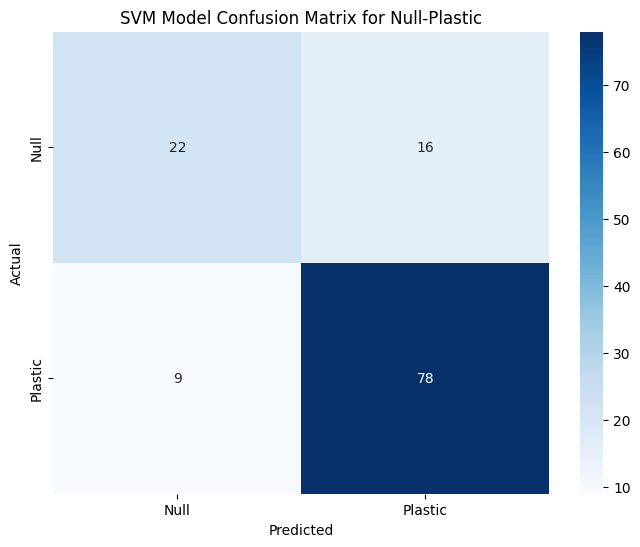


Final model performance:
Test Accuracy: 0.8000
Test F1 Score: 0.8619
Final BIC: 1218.3902


In [ ]:
def FeatureSelectionGeneral(group_name, df, selection_type='forward', model_type='SVM', max_features=None,
                                  min_improvement=10, min_improvement_f1 = 0.01, randomState=42, dataType='k',
                                  printFlag=True, plotFlag=False, f1Flag=False, swapLabel=True, bicAddFlag=True, **model_kwargs):
    """
    Generalized forward/backward feature selection using BIC as the selection criterion.
    Works with multiple ML algorithms: XGB, SVM, LDA, LR, LRL1, kNN

    Parameters:
    -----------
    group_name : str
        Group identifier for data preparation
    df : DataFrame
        Input dataframe
    selection_type : str
        Type of selection to perform ('forward' or 'backward')
    model_type : str
        Type of model to use ('XGB', 'SVM', 'LDA', 'LR', 'LRL1', 'kNN')
    max_features : int, optional
        Maximum number of features to select (default: all features)
    min_improvement : float
        Minimum BIC improvement required to continue selection (default: 0.1)
    randomState : int
        Random state for reproducibility (default: 42)
    dataType : str
        Data type identifier (default: 'k')
    printFlag : bool
        Whether to print progress information (default: True)
    plotFlag : bool
        Whether to plot BIC progression (default: True)
    **model_kwargs : dict
        Additional keyword arguments for the specific model functions

    Returns:
    --------
    dict : Dictionary containing selected features, BIC progression, and final model results
    """

    from sklearn.metrics import accuracy_score, log_loss
    from sklearn.model_selection import cross_val_score
    import warnings
    warnings.filterwarnings('ignore')

    # Model function mapping
    MODEL_FUNCTIONS = {
        'XGB': RunXGBoost,
        'SVM': RunSVM,
        'LDA': RunLDA,
        'LR': RunLR,
        'LRL1': RunLRL1,
        'kNN': RunkNN
    }

    # Validate model type
    if model_type not in MODEL_FUNCTIONS:
        raise ValueError(f"Model type '{model_type}' not supported. "
                        f"Choose from: {list(MODEL_FUNCTIONS.keys())}")

    # Validate selection type
    if selection_type not in ['forward', 'backward']:
        raise ValueError(f"Selection type '{selection_type}' not supported. "
                        f"Choose from: ['forward', 'backward']")

    model_func = MODEL_FUNCTIONS[model_type]
    try:
        # Get initial data preparation
        X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, X, y, y_orig, le = PrepXY(
            group_name, df, printFlag=False, randomState=randomState, dataType=dataType
        )
    except Exception as e:
        if printFlag:
            print(f"Error in data preparation: {e}")
        return _create_error_result(str(e))

    # Validate data
    if X_train.shape[0] == 0 or X_test.shape[0] == 0:
        if printFlag:
            print("Error: No samples in training or test data")
        return _create_error_result('No samples in data')

    if X_train.shape[1] == 0:
        if printFlag:
            print("Error: No features available for selection")
        return _create_error_result('No features available')

    all_features = list(X_train.columns)

    # Initialize based on selection type
    if selection_type == 'forward':
        selected_features = []
        remaining_features = all_features.copy()
    else:  # backward
        selected_features = all_features.copy()
        remaining_features = []

    # Track progression
    bic_history = []
    feature_history = []
    accuracy_history = []
    f1_history = []
    model_results_history = []

    if max_features is None:
        max_features = len(all_features)

    if printFlag:
        print(f"Starting {selection_type.title()} Feature Selection with {len(all_features)} total features")
        print(f"Model: {model_type}, Max features: {max_features}")
        print("-" * 60)

    best_bic = float('inf')

    if selection_type == 'forward':
        # Forward selection loop
        for step in range(min(max_features, len(all_features))):
            best_feature = None
            best_step_bic = float('inf')
            best_step_f1_score = 0
            best_step_results = None
            best_model_output = None

            if printFlag:
                print(f"\nStep {step + 1}: Testing {len(remaining_features)} remaining features...")

            # Test each remaining feature
            for feature in remaining_features:
                current_features = selected_features + [feature]
                #print(current_features)

                try:
                    # Create subset dataframe with only current features
                    feature_columns = [col for col in df.columns if col in current_features or
                                    col in [group_name]]  # Keep Group column
                    temp_df = df[feature_columns].copy()
                    #print(temp_df)
                    # Run the model with current feature set
                    model_results = model_func(
                        group_name=group_name,
                        df=temp_df,
                        randomState=randomState,
                        dataType='bic',
                        printFlag=False,
                        BICFlag=True,
                        f1Flag=f1Flag,
                        swapLabel=swapLabel,
                        **model_kwargs
                    )
                    #print(model_results)
                    # Extract key metrics
                    if 'error' in model_results:
                        if printFlag and len(remaining_features) <= 10:
                            print(f"  Feature '{feature}': Error - {model_results['error']}")
                        continue

                    # Calculate BIC
                    bic = model_results.get("bic", None)
                    accuracy = model_results.get('accuracy', None)
                    f1_score = None
                    if f1Flag:
                        f1_score = model_results.get('f1_score', None)

                    # Check if this is the best BIC for this step
                    if bicAddFlag and (bic < best_step_bic):
                        best_step_bic = bic
                        best_feature = feature
                        best_step_results = {
                            'bic': bic,
                            'accuracy': accuracy,
                            'f1_score': f1_score,
                            'features': current_features.copy(),
                            'n_features': len(current_features)
                        }
                        best_model_output = model_results
                    elif bicAddFlag == False and f1_score < best_step_f1_score:
                        best_step_bic = bic
                        best_step_f1_score = f1_score
                        best_feature = feature
                        best_step_results = {
                            'bic': bic,
                            'accuracy': accuracy,
                            'f1_score': f1_score,
                            'features': current_features.copy(),
                            'n_features': len(current_features)
                        }
                        best_model_output = model_results

                    if printFlag and len(remaining_features) <= 10:
                        print(f"  Feature '{feature}': BIC = {bic:.4f}, Accuracy = {accuracy:.4f}")

                except Exception as e:
                    if printFlag:
                        print(f"  Error testing feature '{feature}': {e}")
                    continue

            # Check if we found a good feature to add
            if best_feature is None:
                if printFlag:
                    print("No valid features found to add. Stopping selection.")
                break

            # Check for improvement
            if bicAddFlag and step > 0 and (best_bic - best_step_bic) < min_improvement:
                if printFlag:
                    print(f"BIC improvement ({best_bic - best_step_bic:.4f}) below threshold ({min_improvement}). Stopping.")
                break
            elif bicAddFlag == False and best_step_f1_score < min_improvement_f1:
                if printFlag:
                    print(f"F1 improvement ({best_f1 - best_step_f1_score:.4f}) below threshold ({min_improvement_f1}). Stopping.")
                break

            # Add the best feature
            selected_features.append(best_feature)
            remaining_features.remove(best_feature)
            best_bic = best_step_bic
            best_f1 = best_step_f1_score

            # Record history
            bic_history.append(best_step_bic)
            feature_history.append(best_feature)
            accuracy_history.append(best_step_results['accuracy'])
            if f1Flag:
                f1_history.append(best_step_results['f1_score'])
            model_results_history.append(best_model_output)

            if printFlag:
                print(f"Added feature: '{best_feature}'")
                print(f"BIC: {best_step_bic:.4f}, Accuracy: {best_step_results['accuracy']:.4f}")
                if f1Flag:
                    print(f"F1 Score: {best_step_results['f1_score']:.4f}")
                print(f"Current features ({len(selected_features)}): {selected_features}")

    else:  # backward selection
        # Start with baseline BIC using all features
        try:
            model_results = model_func(
                group_name=group_name,
                df=df,
                randomState=randomState,
                dataType=dataType,
                printFlag=False,
                BICFlag=False,
                f1Flag=f1Flag,
                swapLabel=swapLabel,
                **model_kwargs
            )
            print(model_results)
            if 'error' not in model_results:
                best_bic = model_results.get("bic", float('inf'))
                baseline_accuracy = model_results.get('accuracy', 0)

                # Record initial state
                bic_history.append(best_bic)
                feature_history.append('baseline')
                accuracy_history.append(baseline_accuracy)
                model_results_history.append(model_results)

                if printFlag:
                    print(f"Baseline (all features): BIC = {best_bic:.4f}, Accuracy = {baseline_accuracy:.4f}")
            else:
                if printFlag:
                    print("Error with baseline model using all features")
                return _create_error_result('Baseline model failed')

        except Exception as e:
            if printFlag:
                print(f"Error evaluating baseline model: {e}")
            return _create_error_result('Baseline evaluation failed')

        # Backward elimination loop
        min_features = max(1, len(all_features) - max_features) if max_features else 1

        while len(selected_features) > min_features:
            best_feature_to_remove = None
            best_step_bic = float('inf')
            best_step_f1_score = 0
            best_step_results = None
            best_model_output = None

            if printFlag:
                print(f"\nStep {len(bic_history)}: Testing removal of {len(selected_features)} current features...")

            # Test removing each current feature
            for feature in selected_features:
                current_features = [f for f in selected_features if f != feature]

                if len(current_features) == 0:
                    continue  # Skip if removing would result in no features

                try:
                    # Create subset dataframe without the current feature
                    feature_columns = [col for col in df.columns if col in current_features or
                                    col in [group_name]]  # Keep Group column
                    temp_df = df[feature_columns].copy()

                    # Run the model without current feature
                    model_results = model_func(
                        group_name=group_name,
                        df=temp_df,
                        randomState=randomState,
                        dataType='bic',
                        printFlag=False,
                        f1Flag=f1Flag,
                        BICFlag=True,
                        **model_kwargs
                    )

                    # Extract key metrics
                    if 'error' in model_results:
                        if printFlag and len(selected_features) <= 10:
                            print(f"  Remove '{feature}': Error - {model_results['error']}")
                        continue

                    # Calculate BIC
                    bic = model_results.get("bic", None)
                    accuracy = model_results.get('accuracy', None)
                    f1_score = None
                    if f1Flag:
                        f1_score = model_results.get('f1_score', None)

                    # Check if this is the best BIC for this step (lowest BIC is best)
                    if bicAddFlag and (bic < best_step_bic):
                        best_step_bic = bic
                        best_feature_to_remove = feature
                        best_step_results = {
                            'bic': bic,
                            'accuracy': accuracy,
                            'f1_score': f1_score,
                            'features': current_features.copy(),
                            'n_features': len(current_features)
                        }
                        best_model_output = model_results
                    elif bicAddFlag == False and f1_score < best_step_f1_score:
                        best_step_bic = bic
                        best_step_f1_score = f1_score
                        best_feature_to_remove = feature
                        best_step_results = {
                            'bic': bic,
                            'accuracy': accuracy,
                            'f1_score': f1_score,
                            'features': current_features.copy(),
                            'n_features': len(current_features)
                        }
                    if printFlag and len(selected_features) <= 10:
                        print(f"  Remove '{feature}': BIC = {bic:.4f}, Accuracy = {accuracy:.4f}")

                except Exception as e:
                    if printFlag:
                        print(f"  Error testing removal of feature '{feature}': {e}")
                    continue

            # Check if we found a feature worth removing
            if best_feature_to_remove is None:
                if printFlag:
                    print("No valid feature removals found. Stopping selection.")
                break

            # Check for improvement (for backward, improvement means BIC decreased)
            if bicAddFlag and ((best_bic - best_step_bic) < min_improvement):
                if printFlag:
                    print(f"BIC improvement ({best_bic - best_step_bic:.4f}) below threshold ({min_improvement}). Stopping.")
                break
            elif bicAddFlag == False and best_step_f1_score < min_improvement_f1:
                if printFlag:
                    print(f"F1 improvement ({best_f1 - best_step_f1_score:.4f}) below threshold ({min_improvement_f1}). Stopping.")
                break

            # Remove the feature that led to best BIC improvement
            selected_features.remove(best_feature_to_remove)
            best_bic = best_step_bic
            best_f1 = best_step_f1_score

            # Record history
            bic_history.append(best_step_bic)
            feature_history.append(f"removed_{best_feature_to_remove}")
            accuracy_history.append(best_step_results['accuracy'])
            if f1Flag:
                f1_history.append(best_step_results['f1_score'])
            model_results_history.append(best_model_output)

            if printFlag:
                print(f"Removed feature: '{best_feature_to_remove}'")
                print(f"BIC: {best_step_bic:.4f}, Accuracy: {best_step_results['accuracy']:.4f}")
                if f1Flag:
                    print(f"F1 Score: {best_step_results['f1_score']:.4f}")
                print(f"Remaining features ({len(selected_features)}): {selected_features}")

    # Final results summary
    if printFlag:
        print(f"\n{'='*60}")
        print(f"{selection_type.upper()} FEATURE SELECTION COMPLETE")
        print(f"{'='*60}")
        print(f"Model Type: {model_type}")
        print(f"Selected {len(selected_features)} features:")
        for i, feature in enumerate(selected_features, 1):
            print(f"  {i:2d}. {feature}")

    # Train final model with selected features
    final_model_results = None
    if selected_features:
        try:
            # Create final dataframe with selected features
            final_feature_columns = [col for col in df.columns if col in selected_features or
                                    col in [group_name]]
            final_df = df[final_feature_columns].copy()

            # Train final model
            final_model_results = model_func(
                group_name=group_name,
                df=final_df,
                randomState=randomState,
                dataType='bic',
                printFlag=False,
                f1Flag=f1Flag,
                cmFlag=True,
                **model_kwargs
            )

            if printFlag and 'error' not in final_model_results:
                print(f"\nFinal model performance:")
                print(f"Test Accuracy: {final_model_results.get('accuracy', None):.4f}")
                if f1Flag:
                    print(f"Test F1 Score: {final_model_results.get('f1_score', None):.4f}")
                print(f"Final BIC: {bic_history[-1] if bic_history else 'N/A':.4f}")

        except Exception as e:
            if printFlag:
                print(f"Error training final model: {e}")

    # Prepare final results
    final_results = {
        'model_type': model_type,
        'selection_type': selection_type,
        'selected_features': selected_features,
        'bic_history': bic_history,
        'feature_history': feature_history,
        'accuracy_history': accuracy_history,
        'f1_history': f1_history if f1Flag else [],
        'model_results_history': model_results_history,
        'final_bic': bic_history[-1] if bic_history else float('inf'),
        'final_accuracy': accuracy_history[-1] if accuracy_history else 0,
        'final_f1_score': f1_history[-1] if f1_history else 0,
        'final_model_results': final_model_results,
        'n_features_selected': len(selected_features),
        'total_features_available': len(all_features)
    }

    # Plot progression
    if plotFlag and bic_history:
        _plot_selection_results(bic_history, accuracy_history, feature_history, model_type, selection_type)

    return final_results

def _plot_selection_results(bic_history, accuracy_history, feature_history, model_type):
    """Plot the feature selection progression"""
    import matplotlib.pyplot as plt

    plt.figure(figsize=(15, 5))

    # BIC progression
    plt.subplot(1, 3, 1)
    plt.plot(range(1, len(bic_history) + 1), bic_history, 'bo-', linewidth=2, markersize=8)
    plt.xlabel('Number of Features')
    plt.ylabel('BIC')
    plt.title(f'BIC vs Number of Features\n({model_type} Model)')
    plt.grid(True, alpha=0.3)

    # Accuracy progression
    plt.subplot(1, 3, 2)
    plt.plot(range(1, len(accuracy_history) + 1), accuracy_history, 'ro-', linewidth=2, markersize=8)
    plt.xlabel('Number of Features')
    plt.ylabel('Accuracy')
    plt.title(f'Accuracy vs Number of Features\n({model_type} Model)')
    plt.grid(True, alpha=0.3)

    # Feature selection order
    plt.subplot(1, 3, 3)
    y_pos = range(len(feature_history))
    plt.barh(y_pos, range(1, len(feature_history) + 1), alpha=0.7)
    plt.yticks(y_pos, [f[:20] + '...' if len(f) > 20 else f for f in feature_history])
    plt.xlabel('Selection Order')
    plt.title(f'Feature Selection Order\n({model_type} Model)')
    plt.gca().invert_yaxis()

    plt.tight_layout()
    plt.show()


def _create_error_result(error_message):
    """Helper function to create standardized error result dictionary"""
    return {
        'error': error_message,
        'model_type': None,
        'selection_type': None,
        'selected_features': [],
        'bic_history': [],
        'feature_history': [],
        'accuracy_history': [],
        'model_results_history': [],
        'final_bic': float('inf'),
        'final_accuracy': 0,
        'final_model_results': None,
        'n_features_selected': 0,
        'total_features_available': 0
    }
def SelectionWrapper(df, selection_types=['forward', 'backward'], dataType='k', kernelType='rbf'):
    algos = ['XGB', 'SVM','LDA','LR','LRL1']
    group_names = ["Group_PN", "Group_Full"]
    for group in group_names:
        for selection_type in selection_types:
            for a in algos:
                if group in group_names == 'Group_PN':
                    results = FeatureSelectionGeneral(group, df, selection_type=selection_type, model_type=a, dataType=dataType, kernelType=kernelType, f1Flag=True)
                else:
                    results = FeatureSelectionGeneral(group, df, selection_type=selection_type, model_type=a, dataType=dataType, kernelType=kernelType, f1Flag=False)


#### Main Code ####

FilePath = '/content/drive/MyDrive/Lexi/MNP/Round_2/KH_Data/20250807KH_combined.csv'

df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedNotPlasticsList = ['BCH', 'BCM', 'BCL', 'CCH', 'CCM', 'CCL', 'MSH', 'MSM', 'MSL', 'SSH', 'SSM', 'SSL'])
#FilePath = '/content/drive/MyDrive/Lexi/MNP/ML Analysis/20250425AIC25s_combined.csv'
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['MSH', 'MSM', 'MSL', 'MCH', 'MCM', 'MCL', 'SSH', 'SSM', 'SSL', 'SCH', 'SCM', 'SCL', '1', '2', '3', '4'])
df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False)
#model_types = ['XGB', 'LDA', 'LRL1', 'LR', 'SVM']
model_types = ['SVM']
for m in model_types:
    results = FeatureSelectionGeneral(
        'Group_PN', df,
        selection_type='backward',
        model_type=m,
        dataType='k',
        kernelType='rbf',  # only used in RunSVM
        bicAddFlag=True,
        f1Flag=True,
        swapLabel=False,
        max_features=700
    )
#SelectionWrapper(df)


In [ ]:
FilePath = '/content/drive/MyDrive/Lexi/MNP/Round_2/KH_Data/20250807KH_combined.csv'
df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedNotPlasticsList = ['BCH', 'BCM', 'BCL', 'CCH', 'CCM', 'CCL', 'MSH', 'MSM', 'MSL', 'SSH', 'SSM', 'SSL'])
print(df)

     Channel Plastic        AH        AL        BH        BL        CH  \
0          0       1  4.941719  5.134148  4.145553  4.968403  5.510925   
1          1       1  4.792103  5.630118  4.572046  5.080342  5.371778   
2          2       1  4.796365  5.593803  5.297004  5.308565  5.435252   
3          3       1  5.193825  5.747676  5.115668  4.969913  5.846541   
4          4       1  4.702975  4.842227  5.288596  5.025671  5.128967   
..       ...     ...       ...       ...       ...       ...       ...   
427       11     VCM  4.635354  4.942228  4.455680  4.869400  5.449211   
428       12     VCM  5.058992  4.956243  5.138867  4.709626  4.673970   
429       13     VCM  3.729789  5.051909  4.835268  4.698439  4.504857   
430       14     VCM  2.739931  4.699115  4.343315  5.075756  4.541433   
431       15     VCM  4.961035  4.947321  4.316897  4.742257  4.767241   

           CL        DH        DL  ...        QH        QL        YH  \
0    5.235836  4.466568  5.043967  ... 

Plastic:240 Null:192


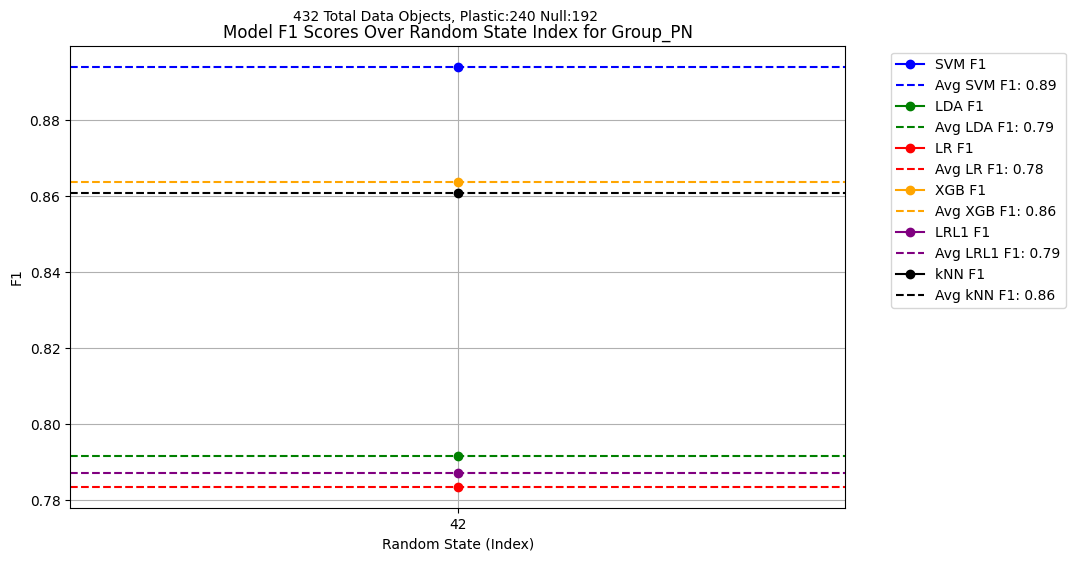

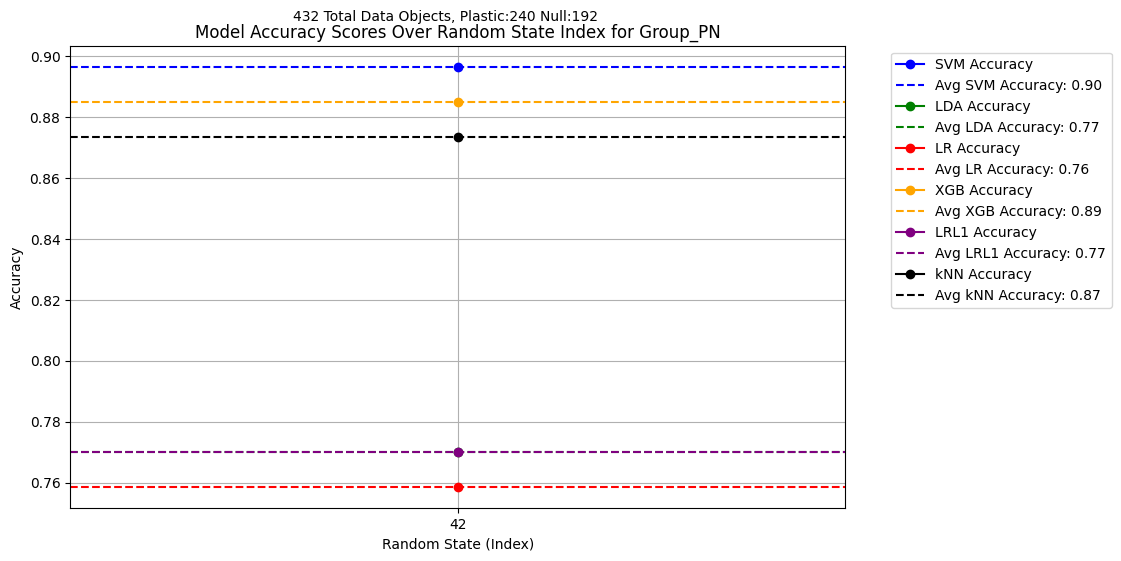

In [ ]:
FilePath = '/content/drive/MyDrive/Lexi/MNP/Round_2/KH_Data/20250807KH_combined.csv'
#Group_Null
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedNotReagentsList = ['CH', 'CL'])
#Group_PN
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False)
#Group_Full
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False)
#Group_MSLVTN
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False)
#Group_PN, kh k, no mixed solvents for plastics
df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedNotPlasticsList = ['BCH', 'BCM', 'BCL', 'CCH', 'CCM', 'CCL', 'MSH', 'MSM', 'MSL', 'SSH', 'SSM', 'SSL'])
#Group_Full, kh k, mixed solvent study
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList=['BCH', 'BCM', 'BCL', 'CCH', 'CCM', 'CCL', 'TCH', 'TCM', 'TCL', '1', '2', '3', '4', '15', '16', '17', '18', '25', '26', '27', '28'])
#Group_CSN

#print(df)
#InvestigateKData(df)

## ** Note that SVM is set is rbf rn!!!! **
##    ...could slave the kernelType to dataType...

dataType = 'k'
group_name = 'Group_PN'
accuracy_df = pd.DataFrame(columns=['random_state', 'SVM_Accuracy', 'LDA_Accuracy', 'LR_Accuracy', 'XGB_Accuracy', 'LRL1_Accuracy'])
f1_df = pd.DataFrame(columns=['random_state', 'SVM_F1', 'LDA_F1', 'LR_F1', "XGB_F1", "LRL1_F1"])
fi_df = pd.DataFrame(columns=['random_state', 'SVM_Feature_Importance', 'LDA_Feature_Importance', 'LR_Feature_Importance', 'XGB_Feature_Importance', 'LRL1_Feature_Importance'])
row_counts = df[group_name].value_counts()
formatted_counts = ' '.join(f'{group}:{count}' for group, count in row_counts.items())
print(formatted_counts)
#nan_count = df.isna().sum()
#print(nan_count.sort_values(ascending=False))
rs_vec = [64678, 51344, 83865, 94980, 72813, 32674, 97809, 976, 35697, 61084]
#rs_vec = random.sample(range(1, 100001), 2)

cmFlag = False
f1Flag = True
swapLabel = False
fAFlag = True
num_rows = df.shape[0]

rs = 42
results = {}
for model_name, run_func in {
    'XGB': RunXGBoost,
    'SVM': RunSVM,
    'LDA': RunLDA,
    'LR': RunLR,
    'LRL1': RunLRL1,
    'kNN': RunkNN
}.items():
    output = run_func(
        group_name, df,
        residualsFlag=False,
        randomState=rs,
        classificationReportFlag=False,
        cmFlag=cmFlag,
        f1Flag=f1Flag,
        swapLabel=swapLabel,
        featureAnalysisFlag=fAFlag,
        dataType=dataType
    )
    results[f'{model_name}_Accuracy'] = output.get('accuracy', None)
    results[f'{model_name}_F1'] = output.get('f1_score', None)
    results[f'{model_name}_Feature_Importance'] = output.get('feature_importance', None)
results['random_state'] = rs
accuracy_df = pd.concat([accuracy_df, pd.DataFrame([{
    k: v for k, v in results.items() if 'Accuracy' in k or k == 'random_state'
}])], ignore_index=True)

if f1Flag:
    f1_df = pd.concat([f1_df, pd.DataFrame([{
        k: v for k, v in results.items() if 'F1' in k or k == 'random_state'
    }])], ignore_index=True)
fi_df = pd.concat([fi_df, pd.DataFrame([{
    k: v for k, v in results.items() if 'Feature_Importance' in k or k == 'random_state'
}])], ignore_index=True)

# Plotting
if f1Flag:
    PlotAvgIndex(group_name, f1_df, "F1", num_rows, formatted_counts)

PlotAvgIndex(group_name, accuracy_df, "Accuracy", num_rows, formatted_counts)

#FeatureAnalysis(fi_df, num_rows=num_rows, formatted_counts=formatted_counts, groupName=group_name, addedName='R10', printFlag=False, rankLimit=10, saveFlag=True)

In [ ]:
import itertools
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import cross_val_score
import warnings
warnings.filterwarnings('ignore')
from datetime import datetime

def FeatureCombinationGridSearch(group_name, df, model_type='SVM', feature_groups=None,
                                min_features=1, max_features=None, combination_type='all',
                                scoring='accuracy', randomState=42, dataType='k',
                                printFlag=True, plotFlag=False, save_results=False,
                                result_filename=None, test_flag=False, kernelType='rbf', swapLabel=False,
                                **model_kwargs):
    """
    Perform grid search over different combinations of features in the dataset.

    Parameters:
    -----------
    group_name : str
        Group identifier for data preparation (target column)
    df : DataFrame
        Input dataframe
    model_type : str
        Type of model to use ('XGB', 'SVM', 'LDA', 'LR', 'LRL1', 'kNN')
    feature_groups : dict, optional
        Dictionary defining feature groups. Example:
        {
            'demographic': ['age', 'gender', 'education'],
            'clinical': ['bp_systolic', 'bp_diastolic', 'heart_rate'],
            'laboratory': ['glucose', 'cholesterol', 'triglycerides']
        }
        If None, will treat each feature individually
    min_features : int
        Minimum number of features to include in combinations
    max_features : int, optional
        Maximum number of features to include in combinations
    combination_type : str
        Type of combinations to generate:
        - 'all': Test all possible combinations within size limits
        - 'incremental': Test combinations of size 1, 2, 3, ... up to max_features
        - 'groups': Test combinations of feature groups (requires feature_groups)
        - 'single': Test each feature individually
        - 'custom': Provide custom combinations
    scoring : str
        Scoring metric to optimize ('accuracy', 'f1_score', 'bic')
    randomState : int
        Random state for reproducibility
    dataType : str
        Data type identifier
    printFlag : bool
        Whether to print progress information
    plotFlag : bool
        Whether to plot results
    save_results : bool
        Whether to save results to CSV
    result_filename : str
        Filename for saving results
    **model_kwargs
        Additional arguments for the model function

    Returns:
    --------
    dict : Dictionary containing best feature combination, all results, and summary statistics
    """
    if result_filename is None:
        current_date = datetime.today().strftime('%Y%m%d')
        result_filename = f"{current_date}_features_grid_search_{group_name}_{model_type}_{scoring}.csv"

    # Get feature columns (exclude group column)
    all_columns = df.columns.tolist()
    if group_name in all_columns:
        all_columns.remove(group_name)

    available_features = all_columns.copy()
    groups_given = available_features[-5:]
    available_features = available_features[2:-5]

    if printFlag:
        print(f"Feature Combination Grid Search")
        print(f"Total available features: {len(available_features)}")
        #print(available_features)
        print(f"Model type: {model_type}")
        print(f"Combination type: {combination_type}")
        print("="*80)

    # Generate feature combinations based on type
    feature_combinations = _generate_feature_combinations(
        available_features, feature_groups, combination_type,
        min_features, max_features, printFlag
    )

    if not feature_combinations:
        print("No feature combinations generated!")
        return None

    if printFlag:
        print(f"Testing {len(feature_combinations)} feature combinations...")
        print("="*80)

    # Model function mapping (same as original)
    MODEL_FUNCTIONS = {
        'XGB': RunXGBoost,
        'SVM': RunSVM,
        'LDA': RunLDA,
        'LR': RunLR,
        'LRL1': RunLRL1,
        'kNN': RunkNN
    }

    if model_type not in MODEL_FUNCTIONS:
        raise ValueError(f"Model type '{model_type}' not supported. "
                        f"Choose from: {list(MODEL_FUNCTIONS.keys())}")

    model_func = MODEL_FUNCTIONS[model_type]

    # Store all results
    all_results = []
    best_score = -np.inf if scoring in ['accuracy', 'f1_score'] else np.inf
    best_features = None
    best_result = None


    if test_flag:
        feature_combinations = feature_combinations[:3]
    if scoring == 'f1_score':
        f1Flag = True
    else:
        f1Flag = False
    # Test each feature combination
    for i, feature_combo in enumerate(feature_combinations):
        if printFlag and (i + 1) % max(1, len(feature_combinations) // 20) == 0:
            print(f"Progress: {i + 1}/{len(feature_combinations)} ({((i + 1)/len(feature_combinations)*100):.1f}%)")
        #print(feature_combo)
        try:
            # Create subset dataframe with current feature combination

            selected_columns = list(["Channel", "Plastic"]) + list(feature_combo) + list(groups_given) + [group_name]
            #print(selected_columns)
            subset_df = df[selected_columns].copy()
            #print(subset_df)

            # Run the model with current feature combination
            result = model_func(
                group_name=group_name,
                df=subset_df,
                randomState=randomState,
                dataType=dataType,
                printFlag=False,
                BICFlag=False,
                f1Flag=f1Flag,
                swapLabel=swapLabel,
                kernelType=kernelType,
                **model_kwargs
            )
            #print(result)
            # Check if result contains error
            if 'error' in result:
                if printFlag and len(feature_combinations) <= 50:
                    print(f"  Features {list(feature_combo)}: ERROR - {result['error']}")
                continue

            # Extract key metrics
            accuracy = result.get('accuracy', 0)
            f1_score_val = result.get('f1_score', 0) if scoring == 'f1_score' else 0
            bic = result.get('bic', np.inf)

            # Calculate score based on scoring metric
            if scoring == 'accuracy':
                score = accuracy
            elif scoring == 'f1_score':
                score = f1_score_val
            elif scoring == 'bic':
                score = bic
            else:
                raise ValueError(f"Unsupported scoring metric: {scoring}")

            # Store result
            result_record = {
                'combination_id': i + 1,
                'features': ', '.join(sorted(feature_combo)),
                'n_features': len(feature_combo),
                'score': score,
                'accuracy': accuracy,
                'f1_score': f1_score_val,
                'bic': bic,
                'feature_list': list(feature_combo)  # Keep as list for analysis
            }
            all_results.append(result_record)

            # Check if this is the best result
            is_better = False
            if scoring in ['accuracy', 'f1_score']:
                is_better = score > best_score
            else:  # BIC - lower is better
                is_better = score < best_score

            if is_better:
                best_score = score
                best_features = list(feature_combo)
                best_result = result.copy()
                best_result['combination_id'] = i + 1
                best_result['selected_features'] = best_features

            if printFlag and len(feature_combinations) <= 50:
                print(f"  Features {list(feature_combo)}: {scoring}={score:.4f}")
                if is_better:
                    print("    *** NEW BEST ***")

        except Exception as e:
            if printFlag and len(feature_combinations) <= 50:
                print(f"  Features {list(feature_combo)}: ERROR - {str(e)}")
            # Record failed attempt
            result_record = {
                'combination_id': i + 1,
                'features': ', '.join(sorted(feature_combo)),
                'n_features': len(feature_combo),
                'score': np.nan,
                'accuracy': np.nan,
                'f1_score': np.nan,
                'bic': np.inf,
                'error': str(e),
                'feature_list': list(feature_combo)
            }
            all_results.append(result_record)
            continue

    # Convert results to DataFrame
    results_df = pd.DataFrame(all_results)

    # Summary and results
    if len(results_df) > 0:
        valid_results = results_df[~results_df['score'].isna()]

        if printFlag:
            print(f"\n{'='*80}")
            print("FEATURE COMBINATION GRID SEARCH RESULTS")
            print(f"{'='*80}")
            print(f"Total combinations tested: {len(feature_combinations)}")
            print(f"Successful runs: {len(valid_results)}")
            print(f"Failed runs: {len(results_df) - len(valid_results)}")

            if len(valid_results) > 0:
                print(f"\nBest {scoring}: {best_score:.4f}")
                print(f"Best feature combination ({len(best_features)} features):")
                for j, feature in enumerate(best_features, 1):
                    print(f"  {j:2d}. {feature}")

                # Show feature frequency analysis
                _analyze_feature_frequency(valid_results, scoring, printFlag)

                # Top 10 combinations
                print(f"\nTop 100 Feature Combinations:")
                print("-" * 80)
                if scoring in ['accuracy', 'f1_score']:
                    top_results = valid_results.nlargest(100, 'score')
                else:
                    top_results = valid_results.nsmallest(10, 'score')

                for idx, (_, row) in enumerate(top_results.iterrows(), 1):
                    features_str = row['features'][:60] + "..." if len(row['features']) > 60 else row['features']
                    print(f"{idx:2d}. {scoring}={row['score']:.4f} | "
                          f"n_feat={row['n_features']:2d} | {features_str}")

    # Save results to CSV if requested
    if save_results and len(results_df) > 0:
        try:
            # Prepare DataFrame for saving (exclude feature_list which can't be saved to CSV easily)
            save_df = results_df.drop(columns=['feature_list'], errors='ignore')
            save_df.to_csv(result_filename, index=False)
            if printFlag:
                print(f"\nResults saved to: {result_filename}")
        except Exception as e:
            if printFlag:
                print(f"Error saving results: {e}")

    # Plot results if requested
    if plotFlag and len(results_df) > 0:
        _plot_feature_combination_results(results_df, scoring)

    # Prepare final output
    final_output = {
        'best_features': best_features,
        'best_score': best_score,
        'best_result': best_result,
        'all_results': results_df,
        'summary': {
            'total_combinations': len(feature_combinations),
            'successful_runs': len(results_df[~results_df['score'].isna()]),
            'failed_runs': len(results_df[results_df['score'].isna()]),
            'scoring_metric': scoring,
            'model_type': model_type
        }
    }

    return final_output


def _generate_feature_combinations(available_features, feature_groups, combination_type,
                                 min_features, max_features, printFlag):
    """Generate different types of feature combinations."""

    if max_features is None:
        max_features = len(available_features)

    max_features = min(max_features, len(available_features))

    combinations = []

    if combination_type == 'single':
        # Test each feature individually
        combinations = [(feat,) for feat in available_features]

    elif combination_type == 'all':
        # Generate all combinations within size limits
        for size in range(min_features, max_features + 1):
            # Limit to reasonable number of combinations
            if len(list(itertools.combinations(available_features, size))) > 25000:
                if printFlag:
                    print(f"Warning: Size {size} would generate {len(list(itertools.combinations(available_features, size)))} combinations. Skipping.")
                continue
            combinations.extend(itertools.combinations(available_features, size))

    elif combination_type == 'incremental':
        # Test combinations of increasing size, but limit total combinations
        for size in range(min_features, max_features + 1):
            size_combinations = list(itertools.combinations(available_features, size))
            # Sample if too many combinations
            if len(size_combinations) > 100:
                np.random.seed(42)  # For reproducibility
                size_combinations = np.random.choice(size_combinations, 100, replace=False).tolist()
                if printFlag:
                    print(f"Sampling 100 combinations of size {size} from {len(list(itertools.combinations(available_features, size)))} total")
            combinations.extend(size_combinations)

    elif combination_type == 'groups' and feature_groups:
        # Generate combinations of feature groups
        group_names = list(feature_groups.keys())
        for r in range(1, len(group_names) + 1):
            for group_combo in itertools.combinations(group_names, r):
                # Combine all features from selected groups
                combined_features = []
                for group in group_combo:
                    combined_features.extend(feature_groups[group])
                # Remove duplicates and ensure features exist
                combined_features = [f for f in combined_features if f in available_features]
                if len(combined_features) >= min_features:
                    combinations.append(tuple(combined_features))

    elif combination_type == 'random':
        # Generate random combinations
        np.random.seed(42)
        combinations = []
        for _ in range(min(500, 2**len(available_features))):  # Limit to 500 random combinations
            size = np.random.randint(min_features, max_features + 1)
            combo = tuple(sorted(np.random.choice(available_features, size, replace=False)))
            if combo not in combinations:
                combinations.append(combo)

    else:
        raise ValueError(f"Unknown combination_type: {combination_type}")

    # Remove duplicates and filter by size
    unique_combinations = []
    seen = set()
    for combo in combinations:
        combo_tuple = tuple(sorted(combo))
        if combo_tuple not in seen and min_features <= len(combo) <= max_features:
            unique_combinations.append(combo)
            seen.add(combo_tuple)

    if printFlag:
        print(f"Generated {len(unique_combinations)} unique feature combinations")
        print(f"Size range: {min_features} to {max_features} features")

    return unique_combinations


def _analyze_feature_frequency(results_df, scoring, printFlag):
    """Analyze how often each feature appears in top combinations."""

    valid_results = results_df[~results_df['score'].isna()]
    if len(valid_results) == 0:
        return

    # Get top 25% of results
    top_n = max(5, len(valid_results) // 4)
    if scoring in ['accuracy', 'f1_score']:
        top_results = valid_results.nlargest(top_n, 'score')
    else:
        top_results = valid_results.nsmallest(top_n, 'score')

    # Count feature frequency in top results
    feature_counts = {}
    for _, row in top_results.iterrows():
        features = row['feature_list']
        for feature in features:
            feature_counts[feature] = feature_counts.get(feature, 0) + 1

    # Sort by frequency
    sorted_features = sorted(feature_counts.items(), key=lambda x: x[1], reverse=True)

    if printFlag:
        print(f"\nFeature Frequency in Top {top_n} Combinations:")
        print("-" * 50)
        for feature, count in sorted_features[:15]:  # Show top 15
            percentage = (count / top_n) * 100
            print(f"{feature:25s}: {count:3d}/{top_n} ({percentage:5.1f}%)")


def _plot_feature_combination_results(results_df, scoring):
    """Plot feature combination results."""
    import matplotlib.pyplot as plt

    valid_results = results_df[~results_df['score'].isna()]
    if len(valid_results) == 0:
        print("No valid results to plot")
        return

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Plot 1: Score distribution
    axes[0, 0].hist(valid_results['score'], bins=20, alpha=0.7, edgecolor='black')
    axes[0, 0].set_title(f'Distribution of {scoring.upper()} Scores')
    axes[0, 0].set_xlabel(f'{scoring.upper()} Score')
    axes[0, 0].set_ylabel('Frequency')

    # Plot 2: Number of features vs Score
    axes[0, 1].scatter(valid_results['n_features'], valid_results['score'], alpha=0.6)
    axes[0, 1].set_title(f'Number of Features vs {scoring.upper()} Score')
    axes[0, 1].set_xlabel('Number of Features')
    axes[0, 1].set_ylabel(f'{scoring.upper()} Score')

    # Plot 3: Box plot by feature count
    unique_sizes = sorted(valid_results['n_features'].unique())
    if len(unique_sizes) > 1:
        score_by_size = [valid_results[valid_results['n_features'] == size]['score'].values
                        for size in unique_sizes]
        axes[1, 0].boxplot(score_by_size, labels=unique_sizes)
        axes[1, 0].set_title(f'{scoring.upper()} Score by Feature Count')
        axes[1, 0].set_xlabel('Number of Features')
        axes[1, 0].set_ylabel(f'{scoring.upper()} Score')

    # Plot 4: Top combinations
    top_n = min(15, len(valid_results))
    if scoring in ['accuracy', 'f1_score']:
        top_results = valid_results.nlargest(top_n, 'score')
    else:
        top_results = valid_results.nsmallest(top_n, 'score')

    y_pos = range(len(top_results))
    axes[1, 1].barh(y_pos, top_results['score'])
    axes[1, 1].set_yticks(y_pos)
    axes[1, 1].set_yticklabels([f"{row['n_features']} feat" for _, row in top_results.iterrows()])
    axes[1, 1].set_title(f'Top {top_n} Feature Combinations')
    axes[1, 1].set_xlabel(f'{scoring.upper()} Score')

    plt.tight_layout()
    plt.show()


# Example usage functions
def create_example_feature_combinations():
    """
    Examples of different ways to set up feature combination searches.
    """

    examples = {
        'single_features': {
            'combination_type': 'single',
            'description': 'Test each feature individually'
        },

        'small_combinations': {
            'combination_type': 'all',
            'min_features': 2,
            'max_features': 4,
            'description': 'Test all combinations of 2-4 features'
        },

        'incremental_search': {
            'combination_type': 'incremental',
            'min_features': 1,
            'max_features': 8,
            'description': 'Test increasing feature sizes (sampled if too many)'
        },

        'grouped_features': {
            'combination_type': 'groups',
            'feature_groups': {
                'demographic': ['age', 'gender', 'education', 'income'],
                'health': ['bmi', 'blood_pressure', 'heart_rate'],
                'lifestyle': ['exercise', 'smoking', 'alcohol'],
                'lab_results': ['glucose', 'cholesterol', 'triglycerides']
            },
            'description': 'Test combinations of predefined feature groups'
        },

        'random_sampling': {
            'combination_type': 'random',
            'min_features': 3,
            'max_features': 10,
            'description': 'Random sampling of feature combinations'
        }
    }

    print("FEATURE COMBINATION GRID SEARCH EXAMPLES")
    print("=" * 60)

    for name, config in examples.items():
        print(f"\n{name.upper()}:")
        print(f"  {config['description']}")
        print(f"  Configuration: {config}")

    return examples


# Main execution example
#FilePath = '/content/drive/MyDrive/Lexi/MNP/Round_2/KH_Data/20250807KH_combined.csv'
#FilePath = '/content/drive/MyDrive/Lexi/MNP/Round_2/KH_Data/20250919KH_combined.csv'
FilePath = '/content/drive/MyDrive/Lexi/MNP/Round_2/KH_Data/20251104KH_combined.csv'
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedNotPlasticsList = ['BCH', 'BCM', 'BCL', 'CCH', 'CCM', 'CCL', 'MSH', 'MSM', 'MSL', 'SSH', 'SSM', 'SSL'])
#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['MSH', 'MSM', 'MSL', 'MCH', 'MCM', 'MCL', 'SCH', 'SCM', 'SCL', 'SSH', 'SSM', 'SSL', '1', '2', '3', '4'])
#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedNotPlasticsList = ['BCH', 'BCM', 'BCL', 'CCH', 'CCM', 'CCL', 'MSH', 'MSM', 'MSL', 'SSH', 'SSM', 'SSL', '15', '16', '17', '18', '25', '26', '27', '28'])
#print(df)VC
#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['BCH', 'BCM', 'BCL', 'CCH', 'CCM', 'CCL', '15', '16', '17', '18', '25', '26', '27', '28'])
#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['BCL', '15'])
#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['MSH', 'MSM', 'MSL', 'MCH', 'MCM', 'MCL', 'SCH', 'SCM', 'SCL', 'SSH', 'SSM', 'SSL'])
#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['NSA', 'NSB', 'NSC', '1', '2'])
#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['MCH', 'SCH', 'TCH', 'LCH', 'VCH', '1', '2', '3', '4'])
#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['MSH', 'MSM', 'MSL', '1', '2', '3', '4'])
#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['OCH', 'OCM', 'OCL', '41', '42'])
df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['ACH', 'ACM', 'ACL', '31', '32'])

#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['MCH', 'MCM', 'MCL', 'SCH', 'SCM', 'SCL', 'VCH', 'VCM', 'VCL', 'LCH', 'LCM', 'LCL', 'TCH', 'TCM', 'TCL', '1', '2', '3', '4'])
#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['MCH', 'MCM', 'MCL', 'SCH', 'SCM', 'SCL', 'VCH', 'VCM', 'VCL', 'LCH', 'LCM', 'LCL', 'TCH', 'TCM', 'TCL'])
#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['MSH', 'MSM', 'MSL
#InvestigateKData(df_entire)
df, df_test = HoldOut(df_entire, hold_out_percent=0.20, printFlag=False)


#(df_entire['Group_PN'] == 'Plastic').sum()
#print(df_entire['Group_Full'].value_counts())

#print(df)
#print(df_test)
model_list = ['SVM', 'LR', 'LDA']
#model_list = ['LR']
#model_list = ['SVM', 'XGB']
group_name = 'Group_PN'
print(df_entire[group_name].value_counts())
kernelType = 'linear'
f1Flag=True
swapLabel=False
for m in model_list:
    results = FeatureCombinationGridSearch(
        group_name=group_name,
        df=df,
        model_type=m,
        combination_type='all',
        min_features=2,
        max_features=17,
        scoring='f1_score',
        printFlag=True,
        plotFlag=True,
        swapLabel=swapLabel,
        kernelType=kernelType
    )

    # Access results
    best_features = results['best_features']
    best_score = results['best_score']
    all_results = results['all_results']
    # Test results
    MODEL_FUNCTIONS = {
        'XGB': RunXGBoost,
        'SVM': RunSVM,
        'LDA': RunLDA,
        'LR': RunLR,
        'LRL1': RunLRL1,
        'kNN': RunkNN
    }

    if m not in MODEL_FUNCTIONS:
        raise ValueError(f"Model type '{m}' not supported. "
                        f"Choose from: {list(MODEL_FUNCTIONS.keys())}")
    print(best_features)
    feature_list =list()
    model_func = MODEL_FUNCTIONS[m]
    for j, feature in enumerate(best_features, 1):
        feature_list.append(feature)
    all_columns = df.columns.tolist()
    groups_given = all_columns[-6:]
    total_col = list(["Channel", "Plastic"]) + feature_list + groups_given
    df_test_use = df_test[total_col].copy()
    #print(df_test)
    result = model_func(
                group_name=group_name,
                df=df,
                randomState=42,
                dataType='k',
                printFlag=False,
                BICFlag=False,
                f1Flag=f1Flag,
                cmFlag=True,
                kernelType=kernelType,
                swapLabel=swapLabel,
                df_test=df_test_use
            )
    #print(result)



Unique values in Plastic: ['31' '32' 'ACH' 'ACL' 'ACM']
Group_PN
Plastic    48
Null       32
Name: count, dtype: int64
Feature Combination Grid Search
Total available features: 17
Model type: SVM
Combination type: all
Generated 131054 unique feature combinations
Size range: 2 to 17 features
Testing 131054 feature combinations...


KeyboardInterrupt: 

##Recall Tie Breaker

Lower Concentrations
Unique values in Plastic: ['1' '2' 'NSA' 'NSB' 'NSC']
F1 Score of the SVM linear model: 1.0
Saved PNG to 20260219_Lower Concentrations_cm.png


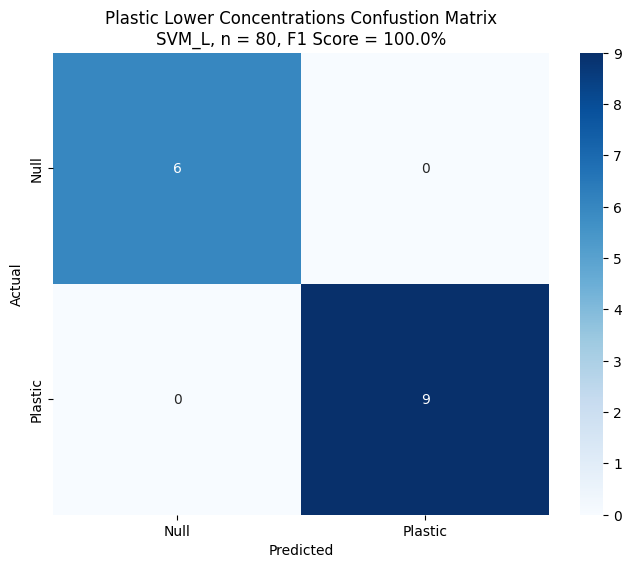

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Recall: 1.0
Feature Rankings (by mean absolute coefficient):
1. Feature 0: 1.5603
2. Feature 2: 1.3172
3. Feature 1: 0.3608
 1. DL                  : 1.5603
 2. N0                  : 1.3172
 3. KL                  : 0.3608


In [ ]:
# Looking at Recall for tie-breakers 12/9/25
from datetime import date
from google.colab import files
from sklearn.metrics import recall_score
pd.set_option('display.max_rows', None)
FilePath = '/content/drive/MyDrive/Lexi/MNP/Round_2/KH_Data/20251104KH_combined.csv'
study_name_list = ['Detection', 'Type', 'Origin', 'Salts', 'Carbon Black', 'Lower Concentrations', 'Morphology']
study_name_list = ['Lower Concentrations']
save_plot_flag=True
swapLabel=False
study_dict = {
        'Detection': {'group_name': 'Group_PN', 'model': 'SVM', 'kernel': 'linear', 'metric': 'f1', 'selected_plastics': ['MCH', 'MCM', 'MCL', 'SCH', 'SCM', 'SCL', 'VCH', 'VCM', 'VCL', 'LCH', 'LCM', 'LCL', 'TCH', 'TCM', 'TCL', '1', '2', '3', '4'], 'selected_reagents': ['AH', 'AL', 'BH', 'CH', 'DH', 'KL', 'N0', 'QH', 'YH']},
        'Type': {'group_name': 'Group_Full', 'model': 'LDA', 'kernel': 'linear', 'metric': 'accuracy', 'selected_plastics': ['MCH', 'MCM', 'MCL', 'SCH', 'SCM', 'SCL', 'VCH', 'VCM', 'VCL', 'LCH', 'LCM', 'LCL', 'TCH', 'TCM', 'TCL', '1', '2', '3', '4'], 'selected_reagents': ['AL', 'BH', 'BL', 'DL', 'GH', 'KL', 'N0', 'QH', 'YH']},
        'Origin': {'group_name': 'Group_CSN', 'model': 'SVM', 'kernel': 'linear', 'metric': 'accuracy', 'selected_plastics': ['MSH', 'MSM', 'MSL', 'MCH', 'MCM', 'MCL', 'SCH', 'SCM', 'SCL', 'SSH', 'SSM', 'SSL', '1', '2', '3', '4'], 'selected_reagents': ['CH', 'CL', 'DH', 'GL', 'KH', 'N0', 'QH']},
        'Salts': {'group_name': 'Group_Full', 'model': 'SVM', 'kernel': 'rbf', 'metric': 'accuracy', 'selected_plastics':['BCH', 'BCM', 'BCL', 'CCH', 'CCM', 'CCL', '15', '16', '17', '18', '25', '26', '27', '28'], 'selected_reagents': ['AH', 'BH', 'GH', 'KH', 'KL', 'N0', 'QH', 'QL', 'YL']},
        'Ammonium Sulfate': {'group_name': 'Group_PN', 'model': 'LR', 'kernel': 'linear', 'metric': 'f1', 'selected_plastics': ['31', '32', 'ACH', 'ACM', 'ACL'], 'selected_reagents': ['BH', 'DL', 'GH', 'GL']},
        'Carbon Black': {'group_name': 'Group_PN', 'model': 'LR', 'kernel': 'linear', 'metric': 'f1', 'selected_plastics': ['41', '42', 'OCH', 'OCM', 'OCL'], 'selected_reagents': ['CH', 'YL']},
        'Lower Concentrations': {'group_name': 'Group_PN', 'model': 'SVM', 'kernel':'linear', 'metric':'f1', 'selected_plastics':['NSA', 'NSB', 'NSC', '1', '2'], 'selected_reagents': ['DL', 'KL', 'N0']},
        'Morphology': {'group_name': 'Group_CSN', 'model': 'LDA', 'kernel':'rbf', 'metric':'f1', 'selected_plastics': ['MCH', 'MCL', 'MCM', 'MSH', 'MSL', 'MSM', 'SCH', 'SCL', 'SCM', 'SSH', 'SSL', 'SSM'], 'selected_reagents': ['CL', 'GH', 'GL', 'KH', 'KL', 'N0', 'QH']}
    }
MODEL_FUNCTIONS = {
        'XGB': RunXGBoost,
        'SVM': RunSVM,
        'LDA': RunLDA,
        'LR': RunLR,
        'LRL1': RunLRL1,
        'kNN': RunkNN
    }
today = date.today()
formatted_date = today.strftime("%Y%m%d")
for study_name in study_name_list:
    print(study_name)
    model_func = MODEL_FUNCTIONS[study_dict[study_name]['model']]
    df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = study_dict[study_name]['selected_plastics'], selectedReagentsList=study_dict[study_name]['selected_reagents'])
    df, df_test = HoldOut(df_entire, hold_out_percent=0.20, printFlag=False)

    if study_dict[study_name]['metric'] == 'f1':
        f1Flag = True
    else:
        f1Flag = False
    if save_plot_flag:
        save_plot_name = f'{formatted_date}_{study_name}_cm.png'
    else:
        save_plot_name = None
    result = model_func(
                    group_name=study_dict[study_name]['group_name'],
                    df=df,
                    randomState=42,
                    dataType='k',
                    printFlag=False,
                    BICFlag=False,
                    f1Flag=f1Flag,
                    cmFlag=True,
                    kernelType=study_dict[study_name]['kernel'],
                    swapLabel=swapLabel,
                    residualsFlag=True,
                    recallFlag=True,
                    df_test=df_test,
                    save_plot_name = save_plot_name
            )
    #print(df_entire.loc[result['misclassified_indices']])

##Residual Analysis for Top Models


Presence
Unique values in Plastic: ['1' '2' '3' '4' 'LCH' 'LCL' 'LCM' 'MCH' 'MCL' 'MCM' 'SCH' 'SCL' 'SCM'
 'TCH' 'TCL' 'TCM' 'VCH' 'VCL' 'VCM']
F1 Score of the Logistic Regression model: 0.9263157894736842
Saved PNG to 20260223_Presence_cm.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

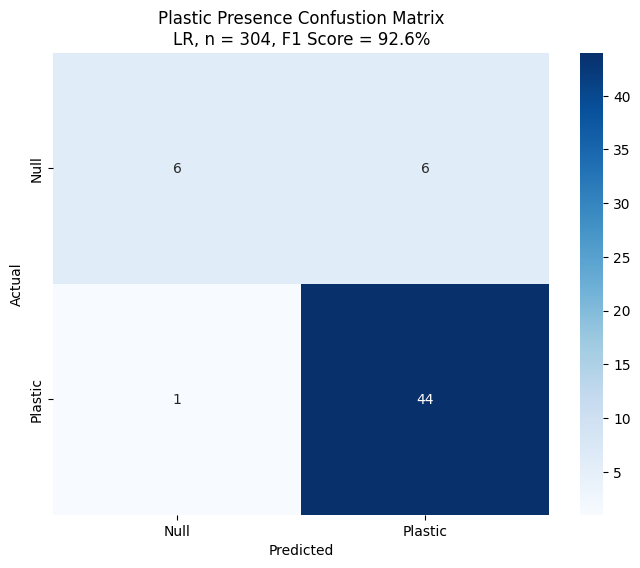

Coefficients: [[ 1.82461544  1.59661358 -1.31144118  1.38234238 -1.7644046   0.77356848
   1.39674473]]
     Channel Plastic        AH        AL        BH        CH        DL  \
0          0       1  4.941719  5.134148  4.145553  5.510925  5.043967   
1          1       1  4.792103  5.630118  4.572046  5.371778  5.109233   
5          5       1  4.888471  4.899840  5.667538  5.281063  4.934597   
48         0       4  5.841190  5.449447  4.712537  4.815355  4.564070   
53         5       4  5.240278  5.056221  5.474815  5.188319  5.280890   
50         2       4  4.999788  4.889274  5.393850  4.973877  4.749935   
131        3     MCL  4.525627  5.031121  4.911636  4.323623  5.707500   

           QH        YH Group_PN Group_MSLVTN Group_Full Group_MHLN Group_CSN  \
0    6.066375  4.258579     Null         Null         DI       Null      Null   
1    5.564461  4.674584     Null         Null         DI       Null      Null   
5    6.085845  5.252181     Null         Null         DI    

In [ ]:
# Residual Analysis for Top Models 12/5/2025
from datetime import date
from google.colab import files
pd.set_option('display.max_rows', None)
FilePath = '/content/drive/MyDrive/Lexi/MNP/Round_2/KH_Data/20251104KH_combined.csv'
study_name_list = ['Presence', 'Type', 'Origin', 'Salts', 'Carbon Black', 'Lower Concentrations', 'Morphology']
study_name_list = ['Presence']
save_plot_flag=True
swapLabel=False
study_dict = {
        'Presence': {'group_name': 'Group_PN', 'model': 'LR', 'kernel': 'linear', 'metric': 'f1', 'selected_plastics': ['MCH', 'MCM', 'MCL', 'SCH', 'SCM', 'SCL', 'VCH', 'VCM', 'VCL', 'LCH', 'LCM', 'LCL', 'TCH', 'TCM', 'TCL', '1', '2', '3', '4'], 'selected_reagents': ['AH', 'AL', 'BH', 'CH', 'DL', 'QH', 'YH']},
        'Type': {'group_name': 'Group_Full', 'model': 'SVM', 'kernel': 'linear', 'metric': 'accuracy', 'selected_plastics': ['MCH', 'MCM', 'MCL', 'SCH', 'SCM', 'SCL', 'VCH', 'VCM', 'VCL', 'LCH', 'LCM', 'LCL', 'TCH', 'TCM', 'TCL', '1', '2', '3', '4'], 'selected_reagents': ['AL', 'BH', 'BL', 'CL', 'DH', 'DL', 'GH', 'GL', 'KH', 'N0', 'QH', 'QL', 'YH', 'YL']},
        'Origin': {'group_name': 'Group_CSN', 'model': 'SVM', 'kernel': 'rbf', 'metric': 'accuracy', 'selected_plastics': ['MSH', 'MSM', 'MSL', 'MCH', 'MCM', 'MCL', 'SCH', 'SCM', 'SCL', 'SSH', 'SSM', 'SSL', '1', '2', '3', '4'], 'selected_reagents': ['AL', 'BL', 'CH', 'GL', 'KH', 'N0', 'QH', 'QL', 'YL']},
        'Salts': {'group_name': 'Group_Full', 'model': 'SVM', 'kernel': 'rbf', 'metric': 'accuracy', 'selected_plastics':['BCH', 'BCM', 'BCL', 'CCH', 'CCM', 'CCL', '15', '16', '17', '18', '25', '26', '27', '28'], 'selected_reagents': ['AH', 'AL', 'BH', 'CL', 'DH', 'GH', 'N0', 'QL', 'YL']},
        'Carbon Black': {'group_name': 'Group_PN', 'model': 'SVM', 'kernel': 'linear', 'metric': 'f1', 'selected_plastics': ['41', '42', 'OCH', 'OCM', 'OCL'], 'selected_reagents': ['CH', 'QL']},
        'Lower Concentrations': {'group_name': 'Group_PN', 'model': 'LR', 'kernel':'linear', 'metric':'f1', 'selected_plastics':['NSA', 'NSB', 'NSC', '1', '2'], 'selected_reagents': ['BH', 'KH']},
        'Morphology': {'group_name': 'Group_CSN', 'model': 'LR', 'kernel':'rbf', 'metric':'accuracy', 'selected_plastics': ['MCH', 'MCL', 'MCM', 'MSH', 'MSL', 'MSM', 'SCH', 'SCL', 'SCM', 'SSH', 'SSL', 'SSM'], 'selected_reagents': ['CL', 'DH', 'GL', 'KL', 'N0', 'YL']}
    }
MODEL_FUNCTIONS = {
        'XGB': RunXGBoost,
        'SVM': RunSVM,
        'LDA': RunLDA,
        'LR': RunLR,
        'LRL1': RunLRL1,
        'kNN': RunkNN
    }
today = date.today()
formatted_date = today.strftime("%Y%m%d")
for study_name in study_name_list:
    print(study_name)
    model_func = MODEL_FUNCTIONS[study_dict[study_name]['model']]
    df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = study_dict[study_name]['selected_plastics'], selectedReagentsList=study_dict[study_name]['selected_reagents'])
    df, df_test = HoldOut(df_entire, hold_out_percent=0.20, printFlag=False)

    if study_dict[study_name]['metric'] == 'f1':
        f1Flag = True
    else:
        f1Flag = False
    if save_plot_flag:
        save_plot_name = f'{formatted_date}_{study_name}_cm.png'
    else:
        save_plot_name = None
    result = model_func(
                    group_name=study_dict[study_name]['group_name'],
                    df=df,
                    randomState=42,
                    dataType='k',
                    printFlag=False,
                    BICFlag=False,
                    f1Flag=f1Flag,
                    cmFlag=True,
                    kernelType=study_dict[study_name]['kernel'],
                    swapLabel=swapLabel,
                    residualsFlag=True,
                    df_test=df_test,
                    save_plot_name = save_plot_name
            )
    print(df_entire.loc[result['misclassified_indices']])

##Feature Plots

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

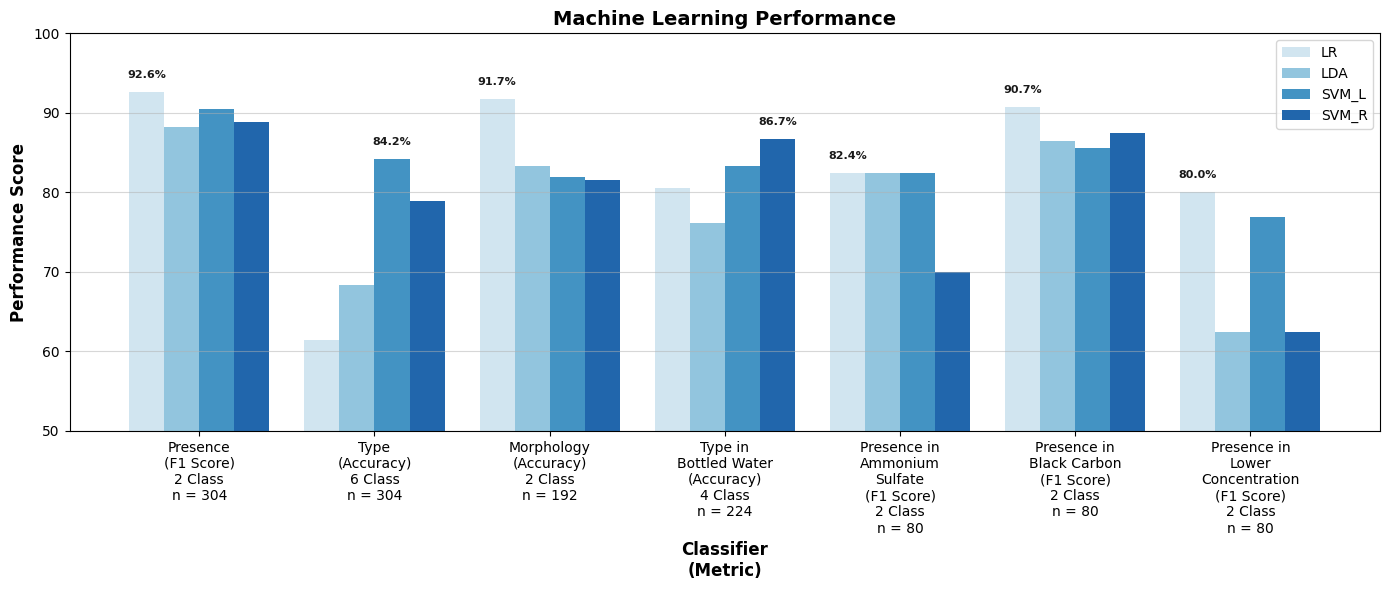

In [ ]:
### For plotting the performance for all models across all tasks

import matplotlib.pyplot as plt
import numpy as np
from google.colab import files
"""
performance_metrics = {
    'Presence\n(F1 Score)\n2 Class\nn = 304': [92.6, 88.2, 90.5, 88.8],
    'Type\n(Accuracy)\n6 Class\nn = 304': [61.4, 68.4, 84.2, 78.9],
    'Morphology\n(Accuracy)\n2 Class\nn = 192': [91.6, 83.3, 81.9, 81.5],
    'Type in\nBottled Water\n(Accuracy)\n4 Class\nn = 224': [80.5, 76.2, 83.3, 86.7],
    'Presence in\nAmmonium\nSulfate\n(F1 Score)\n2 Class\nn = 80': [82.4, 82.4, 82.4, 70.0],
    'Presence in\nBlack Carbon\n(F1 Score)\n2 Class\nn = 80': [90.7, 86.4, 85.6, 87.5],
    'Presence in\nLower\nConcentration\n(F1 Score)\n2 Class\nn = 80': [80.0, 62.5, 76.9, 62.5]
}

# Metric names (customize these to match your seven metrics)
group_names = ['LR', 'LDA', 'SVM_L', 'SVM_R']
colors = ['#d1e5f0', '#92c5de', '#4393c3', '#2166ac']

def create_grouped_bar_chart(data_dict, labels, colors=None, title='Performance Metrics Comparison',
                             ylabel='Score', figsize=(14, 6)):

    Create a grouped bar chart from a dictionary of performance metrics.

    Parameters:
    - data_dict: Dictionary where keys are metric names and values are lists of scores for each set
    - labels: List of set/group names (legend labels)
    - colors: List of colors for each set (optional)
    - title: Chart title
    - ylabel: Y-axis label
    - figsize: Figure size tuple (width, height)

    # Get metrics and their data
    metrics = list(data_dict.keys())
    n_metrics = len(metrics)
    n_sets = len(labels)

    # Set up the bar positions
    x = np.arange(n_metrics)
    width = 0.8 / n_sets  # Width of each bar

    # Create the figure and axis
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_ylim(50, 100)
    ax.grid(axis='y', alpha=0.5, linestyle='-')
    # Create bars for each set
    for i, set_name in enumerate(labels):
        offset = width * i - (width * (n_sets - 1) / 2)
        values = [data_dict[metric][i] for metric in metrics]
        color = colors[i] if colors and i < len(colors) else None
        ax.bar(x + offset, values, width, label=set_name, color=color)

    # Customize the chart
    ax.set_xlabel('Classifier\n(Metric)', fontsize=12, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=12, fontweight='bold')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, ha='center')
    ax.legend(loc='best')

    # Add some padding
    plt.tight_layout()

    return fig, ax

# Create the chart
fig, ax = create_grouped_bar_chart(
    performance_metrics,
    group_names,
    colors=colors,
    title='Machine Learning Performance',
    ylabel='Performance Score'
)

# Save the chart
plt.savefig('performance_chart.png', dpi=600, bbox_inches='tight')
files.download('performance_chart.png')

# Display the chart
plt.show()
"""
performance_metrics = {
    'Presence\n(F1 Score)\n2 Class\nn = 304': [92.6, 88.2, 90.5, 88.8],
    'Type\n(Accuracy)\n6 Class\nn = 304': [61.4, 68.4, 84.2, 78.9],
    'Morphology\n(Accuracy)\n2 Class\nn = 192': [91.7, 83.3, 81.9, 81.5],
    'Type in\nBottled Water\n(Accuracy)\n4 Class\nn = 224': [80.5, 76.2, 83.3, 86.7],
    'Presence in\nAmmonium\nSulfate\n(F1 Score)\n2 Class\nn = 80': [82.4, 82.4, 82.4, 70.0],
    'Presence in\nBlack Carbon\n(F1 Score)\n2 Class\nn = 80': [90.7, 86.4, 85.6, 87.5],
    'Presence in\nLower\nConcentration\n(F1 Score)\n2 Class\nn = 80': [80.0, 62.5, 76.9, 62.5]
}

group_names = ['LR', 'LDA', 'SVM_L', 'SVM_R']
colors = ['#d1e5f0', '#92c5de', '#4393c3', '#2166ac']

def create_grouped_bar_chart(data_dict, labels, colors=None, title='Performance Metrics Comparison',
                             ylabel='Score', figsize=(14, 6)):
    metrics = list(data_dict.keys())
    n_metrics = len(metrics)
    n_sets = len(labels)

    x = np.arange(n_metrics)
    width = 0.8 / n_sets

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_ylim(50, 100)
    ax.grid(axis='y', alpha=0.5, linestyle='-')

    bars_by_metric = {metric: [] for metric in metrics}

    for i, set_name in enumerate(labels):
        offset = width * i - (width * (n_sets - 1) / 2)
        values = [data_dict[metric][i] for metric in metrics]
        color = colors[i] if colors and i < len(colors) else None
        bars = ax.bar(x + offset, values, width, label=set_name, color=color)
        for j, metric in enumerate(metrics):
            bars_by_metric[metric].append((bars[j], values[j], i))

    # Annotate the top-performing bar in each metric group
    for j, metric in enumerate(metrics):
        metric_bars = bars_by_metric[metric]
        top_bar, top_value, top_idx = max(metric_bars, key=lambda b: b[1])
        bar_x = top_bar.get_x() + top_bar.get_width() / 2
        bar_top = top_bar.get_height()

        ax.annotate(
            f'{top_value}%',
            xy=(bar_x, bar_top),
            xytext=(bar_x, bar_top + 1.5),
            ha='center', va='bottom',
            fontsize=8, fontweight='bold', color='#1a1a1a',

        )

    ax.set_xlabel('Classifier\n(Metric)', fontsize=12, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=12, fontweight='bold')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, ha='center')
    ax.legend(loc='best')

    plt.tight_layout()

    return fig, ax

fig, ax = create_grouped_bar_chart(
    performance_metrics,
    group_names,
    colors=colors,
    title='Machine Learning Performance',
    ylabel='Performance Score'
)

plt.savefig('performance_chart.png', dpi=600, bbox_inches='tight')
files.download('performance_chart.png')
plt.show()

['BH', 'BL', 'YH', 'YL', 'KH', 'KL', 'DH', 'DL', 'AH', 'AL', 'QH', 'QL', 'CH', 'CL', 'GH', 'GL', 'N0']
Heatmap saved as 'heatmap.png'


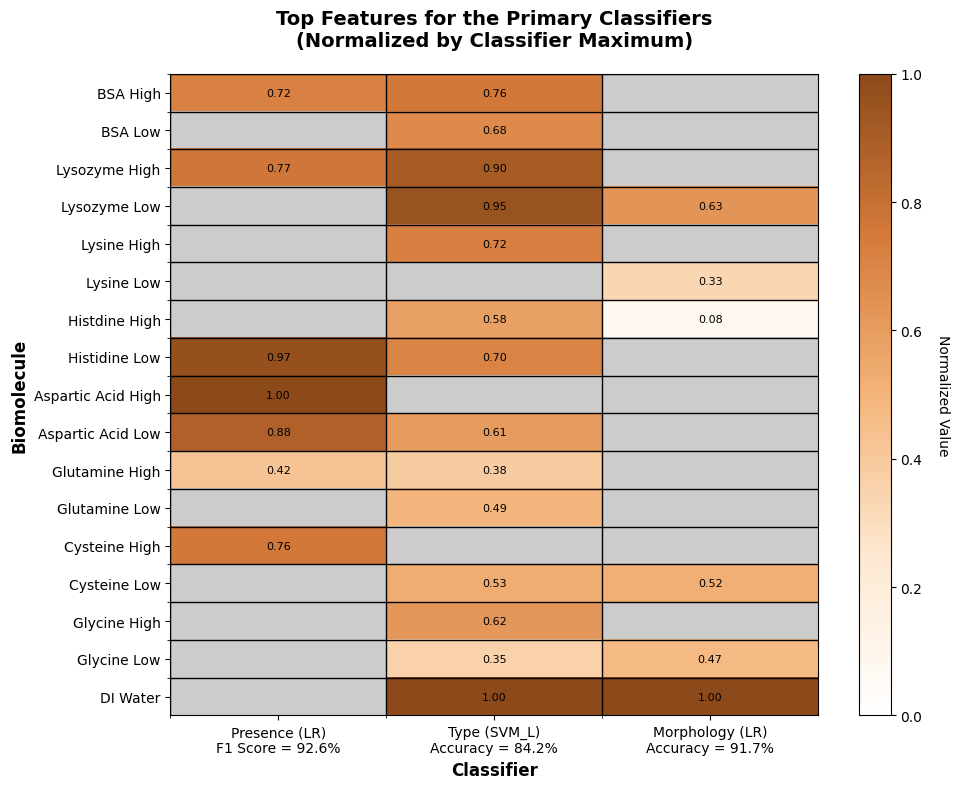

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from google.colab import files

# Data structure: {classifier_name: [(reagent, value), ...]}
data = {
    'Presence (LR)\nF1 Score = 92.6%': [
        ('AH', 1.825),
        ('DL', 1.764),
        ('AL', 1.597),
        ('YH', 1.397),
        ('CH', 1.382),
        ('BH', 1.311),
        ('QH', 0.774)
    ],
    'Type (SVM_L)\nAccuracy = 84.2%': [
        ('N0', 0.608),
        ('YL', 0.578),
        ('YH', 0.550),
        ('BH', 0.460),
        ('KH', 0.439),
        ('DL', 0.428),
        ('BL', 0.413),
        ('GH', 0.378),
        ('AL', 0.368),
        ('DH', 0.354),
        ('CL', 0.322),
        ('QL', 0.297),
        ('QH', 0.234),
        ('GL', 0.215)
    ],
    'Morphology (LR)\nAccuracy = 91.7%': [
        ('N0', 2.380),
        ('YL', 1.502),
        ('CL', 1.235),
        ('GL', 1.123),
        ('KL', 0.793),
        ('DH', 0.184)
    ]
}

# Create reagent name mapping dictionary
reagent_names = {
    'AH': 'AH', 'AL': 'AL', 'BH': 'BH', 'BL': 'BL',
    'CH': 'CH', 'CL': 'CL', 'DH': 'DH', 'DL': 'DL',
    'GH': 'GH', 'GL': 'GL', 'KH': 'KH', 'KL': 'KL',
    'N0': 'N0', 'QH': 'QH', 'QL': 'QL', 'YH': 'YH', 'YL': 'YL'
}
reagent_names = {
    'AH': 'Aspartic Acid High', 'AL': 'Aspartic Acid Low',
    'BH': 'BSA High', 'BL': "BSA Low",
    'CH': 'Cysteine High', 'CL': 'Cysteine Low',
    'DH': 'Histdine High', 'DL': 'Histidine Low',
    'GH': 'Glycine High', 'GL': 'Glycine Low',
    'N0': 'DI Water',
    'QH': 'Glutamine High', 'QL': 'Glutamine Low',
    'YH': 'Lysozyme High', 'YL': 'Lysozyme Low',
    'KH': 'Lysine High', 'KL': 'Lysine Low'
}

# Get all unique reagents
#all_reagents = sorted(set(reagent for classifier_data in data.values()
#                          for reagent, _ in classifier_data))
order_list = ['BH', 'BL', 'YH', 'YL', 'KH', 'KL', 'DH', 'DL', 'AH', 'AL', 'QH', 'QL', 'CH', 'CL', 'GH', 'GL', 'N0']

all_reagents = sorted(
    set(reagent for classifier_data in data.values()
        for reagent, _ in classifier_data),
    key=lambda x: order_list.index(x) if x in order_list else len(order_list)
)
print(all_reagents)
# Get classifier names (column order)
classifiers = list(data.keys())

# Normalize values within each classifier (column)
normalized_data = {}
for classifier, values in data.items():
    # Find absolute max for this classifier
    abs_max = max(abs(val) for _, val in values)

    # Normalize by dividing by absolute max
    normalized_data[classifier] = {
        reagent: value / abs_max for reagent, value in values
    }

# Create the heatmap matrix
# Rows = reagents, Columns = classifiers
matrix = np.full((len(all_reagents), len(classifiers)), np.nan)

for col_idx, classifier in enumerate(classifiers):
    for row_idx, reagent in enumerate(all_reagents):
        if reagent in normalized_data[classifier]:
            matrix[row_idx, col_idx] = normalized_data[classifier][reagent]

# Create custom colormap (blue-white-red, with grey for NaN)
colors_list = ['#2166ac', '#4393c3', '#92c5de', '#d1e5f0',
               '#ffffff',
               '#fddbc7', '#f4a582', '#d6604d', '#b2182b']
colors_list = ['#b2182b', '#d6604d', '#f4a582','#fddbc7'] # reds backwards
colors_list = ['#ffffff','#d1e5f0', '#92c5de','#4393c3','#2166ac']
colors_list = ['#ffffff', '#fde8d0', '#f4b47a', '#d47a3a', '#8c4a1a']

cmap = LinearSegmentedColormap.from_list('custom_diverging', colors_list)
cmap.set_bad(color='#cccccc')  # Grey for missing values

# Create the plot
fig, ax = plt.subplots(figsize=(10, 8))

# Create heatmap
im = ax.imshow(matrix, cmap=cmap, aspect='auto', vmin=-0, vmax=1)

# Set ticks and labels
ax.set_xticks(np.arange(len(classifiers)))
ax.set_yticks(np.arange(len(all_reagents)))
ax.set_xticklabels(classifiers, ha='center')
ax.set_yticklabels([reagent_names[r] for r in all_reagents])

# Add gridlines
ax.set_xticks(np.arange(len(classifiers)) - 0.5, minor=True)
ax.set_yticks(np.arange(len(all_reagents)) - 0.5, minor=True)
ax.grid(which='minor', color='black', linestyle='-', linewidth=1)

# Add value annotations
for i in range(len(all_reagents)):
    for j in range(len(classifiers)):
        if not np.isnan(matrix[i, j]):
            text = ax.text(j, i, f'{matrix[i, j]:.2f}',
                          ha="center", va="center", color="black", fontsize=8)

# Add colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Normalized Value', rotation=270, labelpad=20)

# Labels and title
ax.set_xlabel('Classifier', fontsize=12, fontweight='bold')
ax.set_ylabel('Biomolecule', fontsize=12, fontweight='bold')
ax.set_title('Top Features for the Primary Classifiers\n(Normalized by Classifier Maximum)',
             fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('heatmap.png', dpi=600, bbox_inches='tight')
print("Heatmap saved as 'heatmap.png'")
plt.show()
files.download('heatmap.png')

/tmp/ipython-input-2107222300.py:95: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(names, ha='center')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

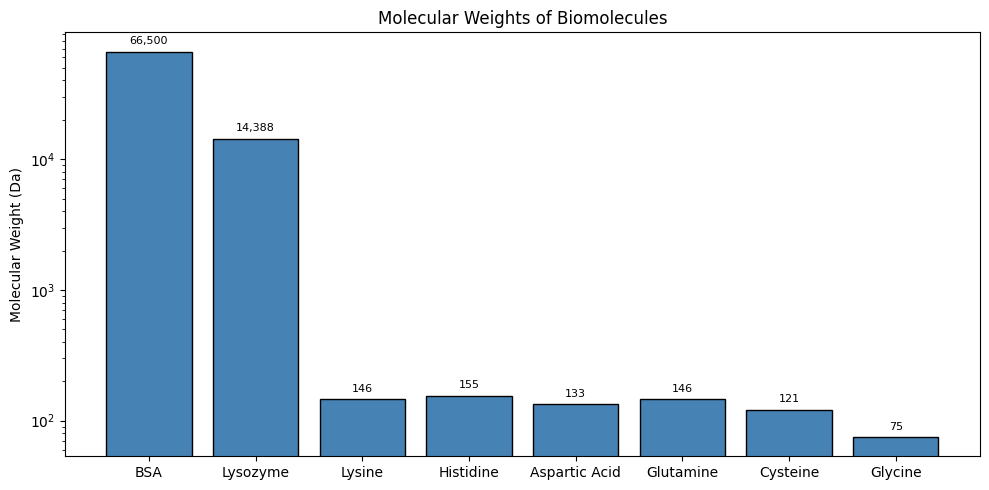

In [ ]:
"""
Plotting Biomolecule Characteristics
"""

def plot_isoelectric_points(ip_dict, baseline=7.0):
    """
    Plot isoelectric points as a diverging bar chart centered at a baseline pH.
    Bars below baseline are red, bars above baseline are blue.

    Args:
        ip_dict: dict of {name: isoelectric_point}
        baseline: pH baseline to diverge from (default 7.0)
    """
    names = list(ip_dict.keys())
    values = list(ip_dict.values())
    deltas = [v - baseline for v in values]
    colors = ['#2563EB' if d >= 0 else '#DC2626' for d in deltas]

    # Sort by delta for a cleaner look
    sorted_data = sorted(zip(deltas, names, values, colors), key=lambda x: x[0])
    sorted_data = list(zip(deltas, names, values, colors))[::-1]
    deltas, names, values, colors = zip(*sorted_data)

    fig, ax = plt.subplots(figsize=(10, 6))

    bars = ax.barh(names, deltas, color=colors, height=0.6,
                   edgecolor='none', zorder=3)

    # Add value labels at the end of each bar
    for bar, val, delta in zip(bars, values, deltas):
        x_pos = delta + (0.08 if delta >= 0 else -0.08)
        ha = 'left' if delta >= 0 else 'right'
        ax.text(x_pos, bar.get_y() + bar.get_height() / 2,
                f'{val}', va='center', ha=ha,
                color='black', fontsize=9, fontweight='bold')

    # Baseline line

    # Styling
    ax.set_xlabel('Isoelectric Point (pH)', color='black', fontsize=11)
    ax.set_xticks([-6, -4, -2, 0, 2, 4, 6])
    ax.set_xticklabels([1, 3, 5, 7, 9, 11, 13])
    ax.set_title('Isoelectric Points of Biomolecules',
                 fontsize=14, fontweight='bold', pad=16)
    ax.set_xlim(-7, 7)

    ax.tick_params(colors='black', labelsize=10)
    ax.xaxis.label.set_color('black')
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.grid(axis='x', color='black', linestyle='-', linewidth=0.7, zorder=0)

    # Legend

    plt.tight_layout()
    plt.savefig('isoelectric_points.png', dpi=600, bbox_inches='tight')
    plt.show()
    print("Chart saved to isoelectric_points.png")
    files.download('isoelectric_points.png')


# --- Run ---
ip_dict = {
    'BSA': 4.5,
    'Lysozyme':11.0,
    'Lysine': 9.74,
    'Histidine': 7.59,
    'Aspartic Acid': 2.77,
    'Glutamine': 5.65,
    'Cysteine': 5.07,
    'Glycine': 5.97,
}

mw_dict = {
    'BSA': 66.5 * 10**3,
    'Lysozyme': 14.388 * 10**3,
    'Lysine': 146,
    'Histidine': 155,
    'Aspartic Acid': 133,
    'Glutamine': 146,
    'Cysteine': 121,
    'Glycine': 75,
}

def plot_molecular_weights(mw_dict):
    names = list(mw_dict.keys())
    weights = list(mw_dict.values())

    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(names, weights, color='steelblue', edgecolor='black')

    ax.set_yscale('log')  # log scale helps since BSA/Lysozyme dwarf the amino acids
    ax.set_ylabel('Molecular Weight (Da)')
    ax.set_title('Molecular Weights of Biomolecules')
    ax.set_xticklabels(names, ha='center')

    # Annotate bars with values
    for bar, val in zip(bars, weights):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.1,
                f'{val:,.0f}', ha='center', va='bottom', fontsize=8)

    plt.tight_layout()
    plt.savefig('molecular_weights.png', dpi=600, bbox_inches='tight')
    files.download('molecular_weights.png')
    plt.show()

plot_molecular_weights(mw_dict)
#plot_isoelectric_points(ip_dict)

Saved PNG to 20251212TopFeatures_mw.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

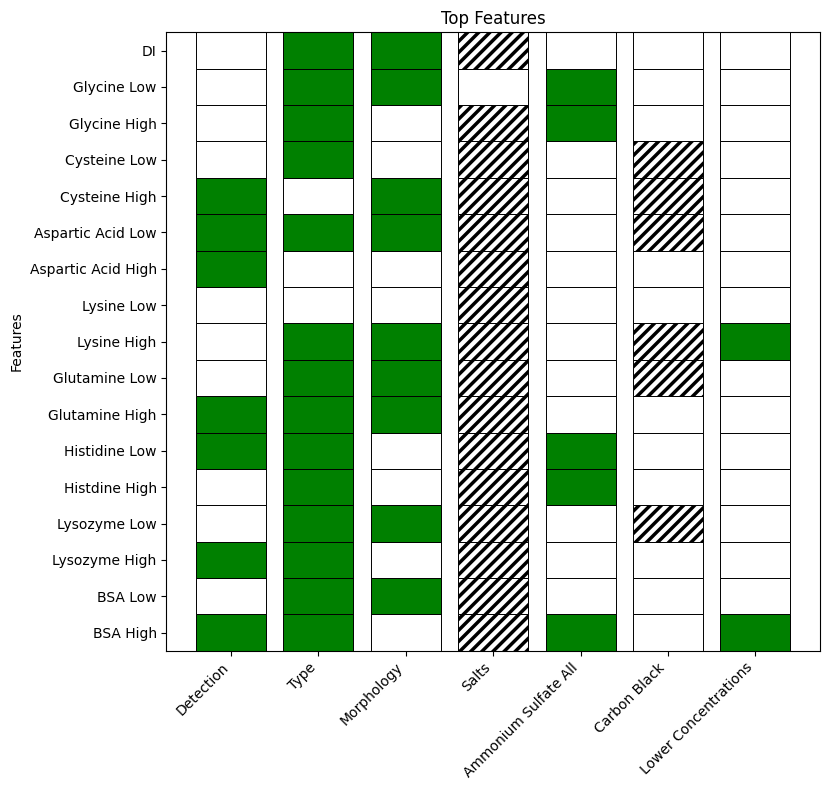

In [ ]:
from google.colab import files
import matplotlib.pyplot as plt
import matplotlib as mpl

def plot_top_reagent_chart(stores, items, item_order=None, item_rename_map=None,
                          hatched_stores=None, svg_path=None):
    """
    Plot a stacked bar chart where each bar corresponds to a store.
    Each bar contains layers for each item (in order).
    Layers are filled green if item is a top item for that store, else white.
    Optionally, certain stores can have hatched fills instead of solid colors.

    Parameters:
        stores (dict): { store_name: [list of top item names] }
        items (list): ordered list of all item names
        item_order (list): custom ordering for items
        item_rename_map (dict): rename items for display
        hatched_stores (list): stores that should use hatched fill instead of solid green
        svg_path (str): optional; if provided, saves a PNG to this path
    """
    if item_order is None:
        item_order = items
    else:
        # Validate that order only includes valid items
        missing = [x for x in item_order if x not in items]
        if missing:
            raise ValueError(f"item_order contains unknown items: {missing}")

    # If no rename map, use identity mapping
    if item_rename_map is None:
        item_rename_map = {}

    # If no hatched stores specified, use empty set
    if hatched_stores is None:
        hatched_stores = set()
    else:
        hatched_stores = set(hatched_stores)

    num_items = len(items)
    num_stores = len(stores)

    # Set hatch linewidth to make lines thicker
    mpl.rcParams['hatch.linewidth'] = 2.5  # Increase this value for thicker lines

    fig, ax = plt.subplots(figsize=(1.2 * num_stores, 8))

    # Height of each layer
    layer_height = 1
    y_positions = [i + layer_height/2 for i in range(num_items)]

    for store_idx, (store, top_items) in enumerate(stores.items()):
        y_offset = 0
        is_hatched_store = store in hatched_stores

        for item in item_order:
            is_top = item in top_items

            # Determine fill properties
            if is_top:
                if is_hatched_store:
                    color = "white"
                    hatch = "///"  # Slanted lines
                else:
                    color = "green"
                    hatch = None
            else:
                color = "white"
                hatch = None

            ax.bar(
                store_idx,
                layer_height,
                bottom=y_offset,
                width=0.8,
                color=color,
                hatch=hatch,
                edgecolor="black",
                linewidth=0.7
            )
            y_offset += layer_height

    # Style adjustments
    y_labels = [item_rename_map.get(item, item) for item in item_order]
    ax.set_xticks(range(num_stores))
    ax.set_xticklabels(list(stores.keys()), rotation=45, ha="right")
    ax.set_ylim(0, num_items * layer_height)
    ax.set_yticks(y_positions)
    ax.set_yticklabels(y_labels)
    ax.set_ylabel("Features")
    ax.set_title("Top Features")

    plt.tight_layout()

    # Save PNG if requested
    if svg_path is not None:
        plt.savefig(svg_path, format='png', dpi=600, bbox_inches='tight')
        print(f"Saved PNG to {svg_path}")
        files.download(svg_path)

    plt.show()

    # Reset to default after plotting
    mpl.rcParams['hatch.linewidth'] = 1.0

#### Main Code ####

reagent_list = ['AH', 'AL', 'BL', 'BH', 'CH', 'CL', 'DH', 'DL', 'GH', 'GL', 'KH', 'KL', 'QH', 'QL', 'YH', 'YL', 'N0']
reagent_order_mw = ['BH', 'BL', 'YH', 'YL', 'DH', 'DL', 'QH', 'QL', 'KH', 'KL', 'AH', 'AL', 'CH', 'CL', 'GH', 'GL', 'N0']
reagent_order_ip = ['YH', 'YL', 'KH', 'KL', 'DH', 'DL', 'GH', 'GL', 'QH', 'QL', 'CH', 'CL', 'BH', 'BL', 'AH', 'AL', 'N0']
reagent_rename_map = {
    'AH': 'Aspartic Acid High', 'AL': 'Aspartic Acid Low',
    'BH': 'BSA High', 'BL': "BSA Low",
    'CH': 'Cysteine High', 'CL': 'Cysteine Low',
    'DH': 'Histdine High', 'DL': 'Histidine Low',
    'GH': 'Glycine High', 'GL': 'Glycine Low',
    'N0': 'DI',
    'QH': 'Glutamine High', 'QL': 'Glutamine Low',
    'YH': 'Lysozyme High', 'YL': 'Lysozyme Low',
    'KH': 'Lysine High', 'KL': 'Lysine Low'
}

model_reagents = {
    "Detection": ['AH', 'AL', 'BH', 'CH', 'DL', 'QH', 'YH'],
    "Type": ['AL', 'BH', 'BL', 'CL', 'DH', 'DL', 'GH', 'GL', 'KH', 'N0', 'QH', 'QL', 'YH', 'YL'],
    "Morphology_old": ['AL', 'BL', 'CH', 'GL', 'KH', 'N0', 'QH', 'QL', 'YL'],
    "Salts": ['AH', 'AL', 'BH', 'BL', 'CH', 'CL', 'DH', 'DL', 'GH', 'KH', 'KL', 'N0', 'QH', 'QL', 'YH', 'YL'],
    "Ammonium Sulfate All": ['BH', 'DH', 'DL', 'GH', 'GL'],
    "Carbon Black": ['AL', 'CH', 'CL', 'KH', 'QL', 'YL'],
    "Lower Concentrations": ['BH', 'KH']
}
model_reagents = {
    "Detection": ['AH', 'AL', 'BH', 'CH', 'DL', 'QH', 'YH'],
    "Type": ['AL', 'BH', 'BL', 'CL', 'DH', 'DL', 'GH', 'GL', 'KH', 'N0', 'QH', 'QL', 'YH', 'YL'],
    "Morphology_old": ['AL', 'BL', 'CH', 'GL', 'KH', 'N0', 'QH', 'QL', 'YL'],
}

# Specify which columns (stores/conditions) should have hatched pattern
hatched_columns = ['Carbon Black', 'Salts']  # Modify as needed

plot_top_reagent_chart(
    model_reagents,
    reagent_list,
    item_order=reagent_order_mw,
    item_rename_map=reagent_rename_map,
    hatched_stores=hatched_columns,
    svg_path='20251212TopFeatures_mw.png'
)

Saved PNG to 20251205TopFeatures_ip.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

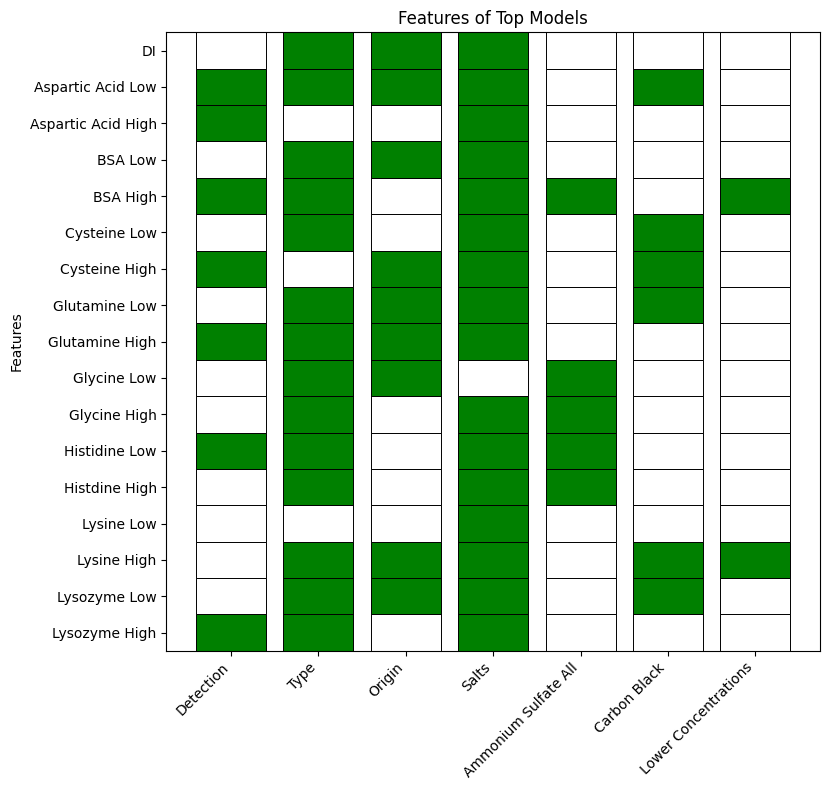

In [ ]:
from google.colab import files
def plot_top_reagent_chart(stores, items, item_order=None, item_rename_map=None, svg_path=None):
    """
    Plot a stacked bar chart where each bar corresponds to a store.
    Each bar contains layers for each item (in order).
    Layers are filled green if item is a top item for that store, else white.

    Parameters:
        stores (dict): { store_name: [list of top item names] }
        items (list): ordered list of all item names
        svg_path (str): optional; if provided, saves an SVG to this path
    """
    if item_order is None:
        item_order = items
    else:
        # Validate that order only includes valid items
        missing = [x for x in item_order if x not in items]
        if missing:
            raise ValueError(f"item_order contains unknown items: {missing}")
    # If no rename map, use identity mapping
    if item_rename_map is None:
        item_rename_map = {}
    num_items = len(items)
    num_stores = len(stores)

    fig, ax = plt.subplots(figsize=(1.2 * num_stores, 8))

    # Height of each layer
    layer_height = 1
    y_positions = [i + layer_height/2 for i in range(num_items)]
    for store_idx, (store, top_items) in enumerate(stores.items()):
        y_offset = 0

        for item in item_order:
            is_top = item in top_items

            ax.bar(
                store_idx,
                layer_height,
                bottom=y_offset,
                width=0.8,
                color="green" if is_top else "white",
                edgecolor="black",
                linewidth=0.7
            )
            y_offset += layer_height

    # Style adjustments
    y_labels = [item_rename_map.get(item, item) for item in item_order]
    ax.set_xticks(range(num_stores))
    ax.set_xticklabels(list(stores.keys()), rotation=45, ha="right")
    ax.set_ylim(0, num_items * layer_height)
    ax.set_yticks(y_positions)
    ax.set_yticklabels(y_labels)
    ax.set_ylabel("Features")
    ax.set_title("Features of Top Models")
    #ax.invert_yaxis()  # optional: top item appears at top of bar

    plt.tight_layout()

    # Save SVG if requested
    if svg_path is not None:
        plt.savefig(svg_path, format='png', dpi=600, bbox_inches='tight')
        print(f"Saved PNG to {svg_path}")

        # Download the file
        files.download(svg_path)

    plt.show()

#### Main Code ####

reagent_list = ['AH', 'AL', 'BL', 'BH', 'CH', 'CL', 'DH', 'DL', 'GH', 'GL', 'KH', 'KL', 'QH', 'QL', 'YH', 'YL', 'N0']
reagent_order_mw = ['BH', 'BL', 'YH', 'YL', 'DH', 'DL', 'QH', 'QL', 'KH', 'KL', 'AH', 'AL', 'CH', 'CL', 'GH', 'GL', 'N0']
reagent_order_ip = ['YH', 'YL', 'KH', 'KL', 'DH', 'DL', 'GH', 'GL', 'QH', 'QL', 'CH', 'CL', 'BH', 'BL', 'AH', 'AL', 'N0']
reagent_rename_map = {'AH': 'Aspartic Acid High', 'AL': 'Aspartic Acid Low', 'BH': 'BSA High', 'BL':"BSA Low", 'CH':'Cysteine High', 'CL': 'Cysteine Low', 'DH': 'Histdine High', 'DL':'Histidine Low', 'GH':'Glycine High', 'GL':'Glycine Low', 'N0':'DI', 'QH':'Glutamine High', 'QL':'Glutamine Low', 'YH':'Lysozyme High', 'YL':'Lysozyme Low', 'KH': 'Lysine High', 'KL':'Lysine Low'}
model_reagents = {
    "Detection": ['AH', 'AL', 'BH', 'CH', 'DL', 'QH', 'YH'],
    "Type": ['AL', 'BH', 'BL', 'CL', 'DH', 'DL', 'GH', 'GL', 'KH', 'N0', 'QH', 'QL', 'YH', 'YL'],
    "Origin": ['AL', 'BL', 'CH', 'GL', 'KH', 'N0', 'QH', 'QL', 'YL'],
    "Salts": ['AH', 'AL', 'BH', 'BL', 'CH', 'CL', 'DH', 'DL', 'GH', 'KH', 'KL', 'N0', 'QH', 'QL', 'YH', 'YL'],
    "Ammonium Sulfate All": ['BH', 'DH', 'DL', 'GH', 'GL'],
    "Carbon Black": ['AL', 'CH', 'CL', 'KH', 'QL', 'YL'],
    "Lower Concentrations": ['BH', 'KH']
}

plot_top_reagent_chart(model_reagents, reagent_list, item_order = reagent_order_ip, item_rename_map=reagent_rename_map, svg_path='20251205TopFeatures_ip.png')

## Statistical Analyses

In [ ]:
#FilePath = '/content/drive/MyDrive/Lexi/MNP/Round_2/KH_Data/20250919KH_combined.csv'
FilePath = '/content/drive/MyDrive/Lexi/MNP/Round_2/KH_Data/20251104KH_combined.csv'
#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False)
#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedNotPlasticsList = ['BCH', 'BCM', 'BCL', 'CCH', 'CCM', 'CCL', 'MSH', 'MSM', 'MSL', 'SSH', 'SSM', 'SSL', '15', '16', '17', '18', '25', '26', '27', '28'])
#df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['MSH', 'MSM', 'MSL', 'MCH', 'MCM', 'MCL', 'SCH', 'SCM', 'SCL', 'SSH', 'SSM', 'SSL', '1', '2', '3', '4'])
df_entire = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList = ['OCH', 'OCM', 'OCL', 'ACH', 'ACM', 'ACL', '31', '32', '41', '42'])
reagent_list = df_entire.columns[2:-6]
label_list = ['Group_CSN', 'Group_PN', 'Group_Full']
#label_list = ['Group_Full']

reagent_plots = False
label_plots = True

if label_plots:
    for l in label_list:
        for r in reagent_list:
            plt.scatter(df_entire[l], df_entire[r])
            plt.title(f'Scatterplot of {r} by {l} Label')
            plt.xlabel('Label')
            plt.ylabel("K value")
            plt.xticks(rotation=45)
            plt.ylabel(r)
            plt.show()
            sns.boxplot(x=l, y=r, data=df_entire)
            plt.title(f'Boxplot of {r} by {l} Label')
            plt.ylabel("K value")
            plt.xticks(rotation=45)
            plt.xlabel('Label')
            plt.show()
if reagent_plots:
    for r in reagent_list:
        plt.scatter(df_entire["Plastic"], df_entire[r])
        plt.title(f'Scatterplot of {r} by Plastic')
        plt.xlabel('Plastic')
        plt.ylabel("K value")
        plt.xticks(rotation=45)
        plt.ylabel(r)
        plt.show()
        sns.boxplot(x='Plastic', y=r, data=df_entire)
        plt.title(f'Boxplot of {r} by Plastic')
        plt.ylabel("K value")
        plt.xticks(rotation=45)
        plt.xlabel('Plastic')
        plt.show()


Output hidden; open in https://colab.research.google.com to view.

##K and K Diff Analysis

In [ ]:
FilePath = '/content/drive/MyDrive/Lexi/MNP/Round_2/KH_Data/20250807KH_combined.csv'
#Group_Null
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedNotReagentsList = ['CH', 'CL'])
#Group_PN
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False)
#Group_Full
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False)
#Group_MSLVTN
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False)
#Group_PN, kh k, no mixed solvents for plastics
df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedNotPlasticsList = ['BCH', 'BCM', 'BCL', 'CCH', 'CCM', 'CCL', 'MSH', 'MSM', 'MSL', 'SSH', 'SSM', 'SSL'])
#Group_Full, kh k, mixed solvent study
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedPlasticsList=['BCH', 'BCM', 'BCL', 'CCH', 'CCM', 'CCL', 'TCH', 'TCM', 'TCL', '1', '2', '3', '4', '15', '16', '17', '18', '25', '26', '27', '28'])
#Group_CSN

#print(df)
#InvestigateKData(df)

## ** Note that SVM is set is rbf rn!!!! **
##    ...could slave the kernelType to dataType...

dataType = 'k'
group_name = 'Group_PN'
accuracy_df = pd.DataFrame(columns=['random_state', 'SVM_Accuracy', 'LDA_Accuracy', 'LR_Accuracy', 'XGB_Accuracy', 'LRL1_Accuracy'])
f1_df = pd.DataFrame(columns=['random_state', 'SVM_F1', 'LDA_F1', 'LR_F1', "XGB_F1", "LRL1_F1"])
fi_df = pd.DataFrame(columns=['random_state', 'SVM_Feature_Importance', 'LDA_Feature_Importance', 'LR_Feature_Importance', 'XGB_Feature_Importance', 'LRL1_Feature_Importance'])
row_counts = df[group_name].value_counts()
formatted_counts = ' '.join(f'{group}:{count}' for group, count in row_counts.items())
print(formatted_counts)
#nan_count = df.isna().sum()
#print(nan_count.sort_values(ascending=False))
rs_vec = [64678, 51344, 83865, 94980, 72813, 32674, 97809, 976, 35697, 61084]
#rs_vec = random.sample(range(1, 100001), 2)

cmFlag = False
f1Flag = True
swapLabel = False
fAFlag = True
num_rows = df.shape[0]
print(df)

for i, rs in enumerate(rs_vec, 1):
    print(f"\r\033[1mCompleting {i} of {len(rs_vec)}\033[0m Model Rounds", end='', flush=True)
    results = {}
    for model_name, run_func in {
        'XGB': RunXGBoost,
        'SVM': RunSVM,
        'LDA': RunLDA,
        'LR': RunLR,
        'LRL1': RunLRL1,
        'kNN': RunkNN
    }.items():
        output = run_func(
            group_name, df,
            residualsFlag=False,
            randomState=rs,
            classificationReportFlag=False,
            cmFlag=cmFlag,
            f1Flag=f1Flag,
            swapLabel=swapLabel,
            featureAnalysisFlag=fAFlag,
            dataType=dataType
        )
        results[f'{model_name}_Accuracy'] = output.get('accuracy', None)
        results[f'{model_name}_F1'] = output.get('f1_score', None)
        results[f'{model_name}_Feature_Importance'] = output.get('feature_importance', None)
    results['random_state'] = rs
    accuracy_df = pd.concat([accuracy_df, pd.DataFrame([{
        k: v for k, v in results.items() if 'Accuracy' in k or k == 'random_state'
    }])], ignore_index=True)

    if f1Flag:
        f1_df = pd.concat([f1_df, pd.DataFrame([{
            k: v for k, v in results.items() if 'F1' in k or k == 'random_state'
        }])], ignore_index=True)
    fi_df = pd.concat([fi_df, pd.DataFrame([{
        k: v for k, v in results.items() if 'Feature_Importance' in k or k == 'random_state'
    }])], ignore_index=True)

# Plotting
if f1Flag:
    PlotAvgIndex(group_name, f1_df, "F1", num_rows, formatted_counts)

PlotAvgIndex(group_name, accuracy_df, "Accuracy", num_rows, formatted_counts)

#FeatureAnalysis(fi_df, num_rows=num_rows, formatted_counts=formatted_counts, groupName=group_name, addedName='R10', printFlag=False, rankLimit=10, saveFlag=True)


Plastic:240 Null:192
     Channel Plastic        AH        AL        BH        BL        CH  \
0          0       1  4.941719  5.134148  4.145553  4.968403  5.510925   
1          1       1  4.792103  5.630118  4.572046  5.080342  5.371778   
2          2       1  4.796365  5.593803  5.297004  5.308565  5.435252   
3          3       1  5.193825  5.747676  5.115668  4.969913  5.846541   
4          4       1  4.702975  4.842227  5.288596  5.025671  5.128967   
..       ...     ...       ...       ...       ...       ...       ...   
427       11     VCM  4.635354  4.942228  4.455680  4.869400  5.449211   
428       12     VCM  5.058992  4.956243  5.138867  4.709626  4.673970   
429       13     VCM  3.729789  5.051909  4.835268  4.698439  4.504857   
430       14     VCM  2.739931  4.699115  4.343315  5.075756  4.541433   
431       15     VCM  4.961035  4.947321  4.316897  4.742257  4.767241   

           CL        DH        DL  ...        QH        QL        YH  \
0    5.235836  4.4

,AH,AL,BH,BL,CH,CL,DH,DL,GH,GL,KH,KL,N0,QH,QL,YH,YL
0,4.941719,5.134148,4.145553,4.968403,5.510925,5.235836,4.466568,5.043967,4.837749,4.994404,4.834701,4.752075,5.236466,6.066375,3.766836,4.258579,5.020434
1,4.792103,5.630118,4.572046,5.080342,5.371778,4.948860,4.678435,5.109233,4.516177,4.823568,4.869920,4.750673,4.959276,5.564461,4.555353,4.674584,4.881083
2,4.796365,5.593803,5.297004,5.308565,5.435252,4.987685,5.118046,5.282843,4.840432,4.808658,5.245215,5.352026,4.541292,4.976486,4.851372,4.641616,4.731899
3,5.193825,5.747676,5.115668,4.969913,5.846541,5.266472,4.171417,5.456792,4.875630,4.634814,5.102143,5.534466,5.113516,4.929969,4.837799,4.705492,4.888167
4,4.702975,4.842227,5.288596,5.025671,5.128967,5.237083,4.833471,4.847848,4.922757,5.276337,3.847913,4.049995,5.091344,4.440534,4.557747,5.120058,5.050373
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
427,4.635354,4.942228,4.455680,4.869400,5.449211,4.828676,4.737381,4.507529,5.560721,5.600277,4.816790,5.015533,5.477968,5.002749,4.650268,7.011731,7.038226
428,5.058992,4.956243,5.138867,4.709626,4.673970,4.743021,4.285056,4.274089,5.510477,4.622413,4.976519,4.644281,4.907785,5.477131,4.555766,7.807121,6.969616
429,3.729789,5.051909,4.835268,4.698439,4.504857,4.717264,4.919823,4.507566,5.804289,3.758297,5.330771,4.609402,4.856560,5.018554,5.336533,7.396608,7.071391
430,2.739931,4.699115,4.343315,5.075756,4.541433,4.780178,4.451546,4.530607,4.669095,4.154223,5.148476,5.153747,4.899776,4.942861,5.404823,7.173946,7.145733


Index(['AH', 'AL', 'BH', 'BL', 'CH', 'CL', 'DH', 'DL', 'GH', 'GL', 'KH', 'KL',
       'N0', 'QH', 'QL', 'YH', 'YL'],
      dtype='object')
Unique Y train values (array([0, 1]), array([153, 192]))
Unique Y test values (array([0, 1]), array([39, 48]))
Unique Y values (array(['Null', 'Plastic'], dtype=object), array([192, 240]))


KeyboardInterrupt: 

BH:35 YH:22 CH:15 CL:13 DL:10 DH:10 YL:6 BL:4 GH:3 KH:1 AH:1

BH:35 YH:22 CH:15 CL:13 DL:10 DH:10 YL:6 BL:4 GH:3 KH:1 AH:1


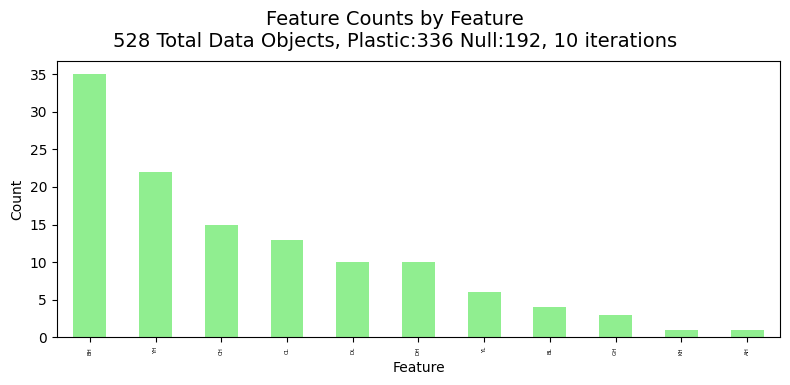

Feature
BH    35
YH    22
CH    15
CL    13
DL    10
DH    10
YL     6
BL     4
GH     3
KH     1
AH     1
Name: count, dtype: int64


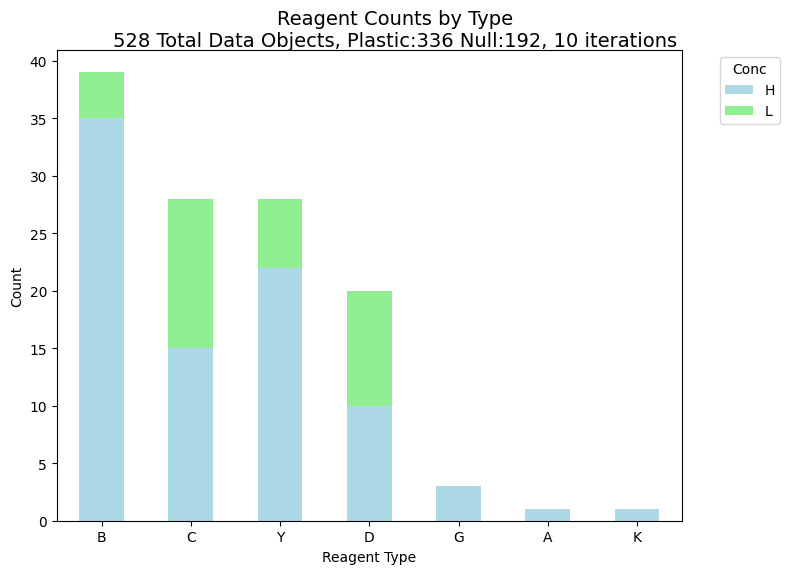

Reagent_Type  A   B   C  D  G  K   Y
Model                               
LDA           0  10   5  5  0  0  10
LR            0  11  13  5  0  0   1
LRL1          0  11   6  2  0  0  11
XGB           1   7   4  8  3  1   6


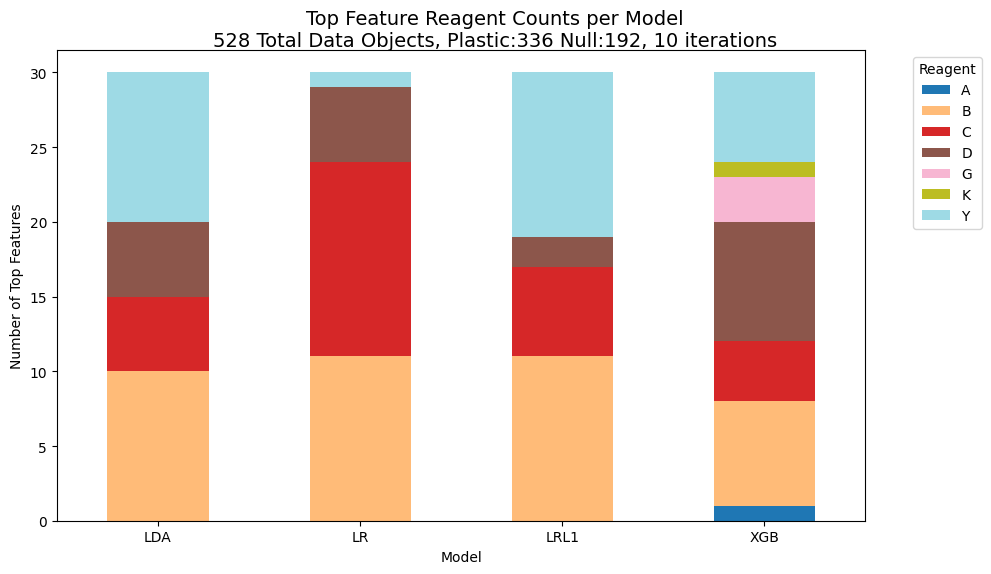

In [ ]:

FeatureAnalysis(fi_df, num_rows=num_rows, formatted_counts=formatted_counts, groupName=group_name, addedName='R10', printFlag=False, rankLimit=10, saveFlag=False, dataType=dataType)

## **Parameters for slope/aic slope:**

Slope (vs Adjusted_Slope with the internal control) - WrangleData(slopeFlag=False)

**for the models:**

group_name

cmFlag

f1Flag

swapLabel

(rs_vec, entries and length)

residualsFlag

classificationReportFlag

##Command Code for Slope

Plastic:240 Null:192
Completing 10 of 10 Model Rounds

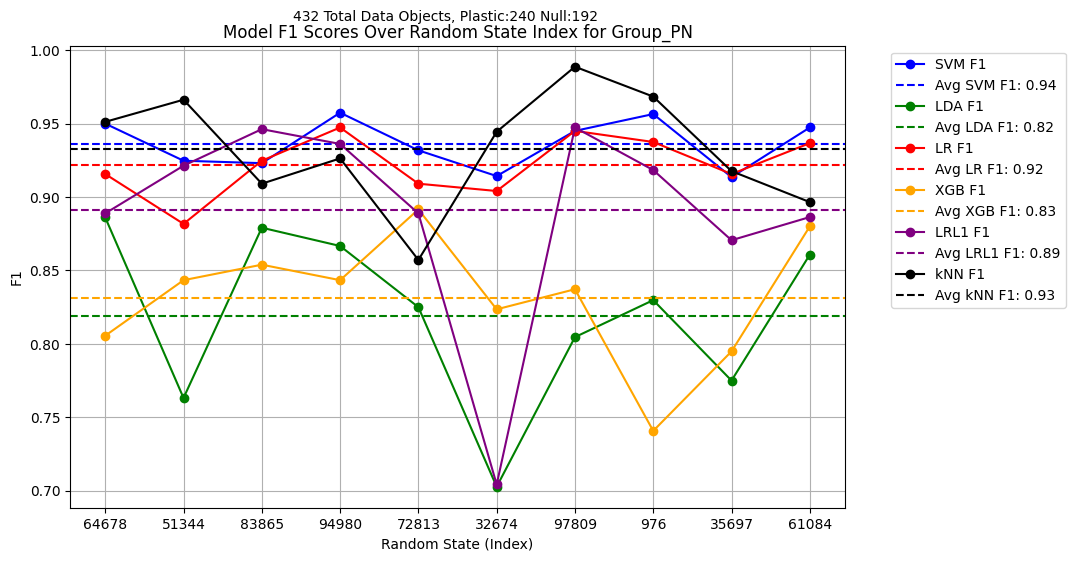

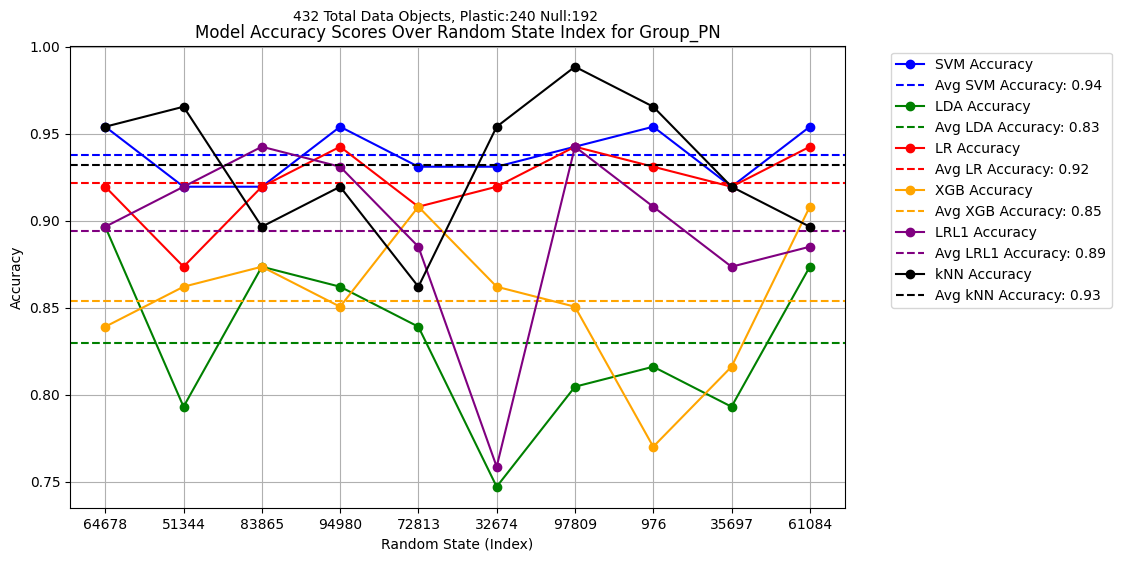

In [ ]:
warnings.filterwarnings("ignore", category=FutureWarning)
FilePath = '/content/drive/MyDrive/Lexi/MNP/ML Analysis/20250425AIC25s_combined.csv'
#df = WrangleData(FilePath, printFlag=False, slopeFlag=False)

df = WrangleData(FilePath, printFlag=False, slopeFlag=False, selectedNotPlasticsList = ['BCH', 'BCM', 'BCL', 'CCH', 'CCM', 'CCL', 'MSH', 'MSM', 'MSL', 'SSH', 'SSM', 'SSL'])
#df = df[((df['Group_MHL'] == 'Low') | (df['Group_PN'] == 'Null'))]
#print(df)
group_name = 'Group_PN'
accuracy_df = pd.DataFrame(columns=['random_state', 'SVM_Accuracy', 'LDA_Accuracy', 'LR_Accuracy', 'XGB_Accuracy', 'LRL1_Accuracy'])
f1_df = pd.DataFrame(columns=['random_state', 'SVM_F1', 'LDA_F1', 'LR_F1', "XGB_F1", "LRL1_F1"])
fi_df = pd.DataFrame(columns=['random_state', 'SVM_Feature_Importance', 'LDA_Feature_Importance', 'LR_Feature_Importance', 'XGB_Feature_Importance', 'LRL1_Feature_Importance'])
row_counts = df[group_name].value_counts()
formatted_counts = ' '.join(f'{group}:{count}' for group, count in row_counts.items())
print(formatted_counts)
#nan_count = df.isna().sum()
#print(nan_count.sort_values(ascending=False))
rs_vec = [64678, 51344, 83865, 94980, 72813, 32674, 97809, 976, 35697, 61084]
#rs_vec = random.sample(range(1, 100001), 2)

cmFlag = False
f1Flag = True
swapLabel = True
fAFlag = True
num_rows = df.shape[0]

for i, rs in enumerate(rs_vec, 1):
    print(f"\r\033[1mCompleting {i} of {len(rs_vec)}\033[0m Model Rounds", end='', flush=True)
    results = {}
    for model_name, run_func in {
        'XGB': RunXGBoost,
        'SVM': RunSVM,
        'LDA': RunLDA,
        'LR': RunLR,
        'LRL1': RunLRL1,
        'kNN': RunkNN
    }.items():
        output = run_func(
            group_name, df,
            residualsFlag=False,
            randomState=rs,
            classificationReportFlag=False,
            cmFlag=cmFlag,
            f1Flag=f1Flag,
            swapLabel=swapLabel,
            featureAnalysisFlag=fAFlag
        )
        results[f'{model_name}_Accuracy'] = output.get('accuracy', None)
        results[f'{model_name}_F1'] = output.get('f1_score', None)
        results[f'{model_name}_Feature_Importance'] = output.get('feature_importance', None)
    results['random_state'] = rs
    accuracy_df = pd.concat([accuracy_df, pd.DataFrame([{
        k: v for k, v in results.items() if 'Accuracy' in k or k == 'random_state'
    }])], ignore_index=True)

    if f1Flag:
        f1_df = pd.concat([f1_df, pd.DataFrame([{
            k: v for k, v in results.items() if 'F1' in k or k == 'random_state'
        }])], ignore_index=True)
    fi_df = pd.concat([fi_df, pd.DataFrame([{
        k: v for k, v in results.items() if 'Feature_Importance' in k or k == 'random_state'
    }])], ignore_index=True)

# Plotting
if f1Flag:
    PlotAvgIndex(group_name, f1_df, "F1", num_rows, formatted_counts)

PlotAvgIndex(group_name, accuracy_df, "Accuracy", num_rows, formatted_counts)


Adjusted Rand Index (ARI): -0.04


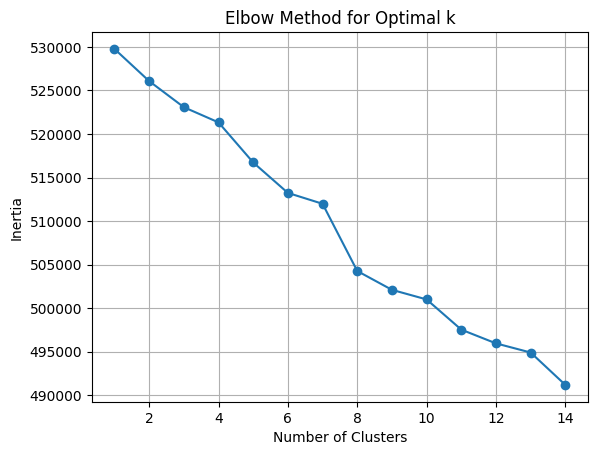

In [ ]:
#PlotAvgIndex(group_name, accuracy_df, "Accuracy", num_rows, formatted_counts)

RunkMeans(group_name, df, printFlag=False, randomState=42, cmFlag=True)


#FeatureAnalysis(fi_df, num_rows=num_rows, formatted_counts=formatted_counts, groupName=group_name, addedName='R10', printFlag=False, rankLimit=10, saveFlag=True)

Accuracy of the kNN model: 1.0


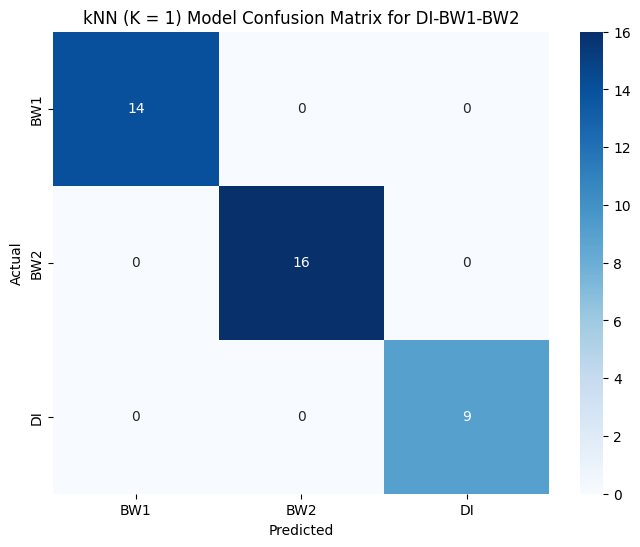

{'accuracy': 1.0}

In [ ]:
###################### kNN ######################
group_name = 'Group_Null'
k=5
RunkNN(group_name, df, printFlag=False, k=k, featureAnalysisFlag=False, residualsFlag=False, classificationReportFlag=False, randomState=42, cmFlag=True)


##PCA

Explained variance ratio for each principal component: [0.14793541 0.11446687]


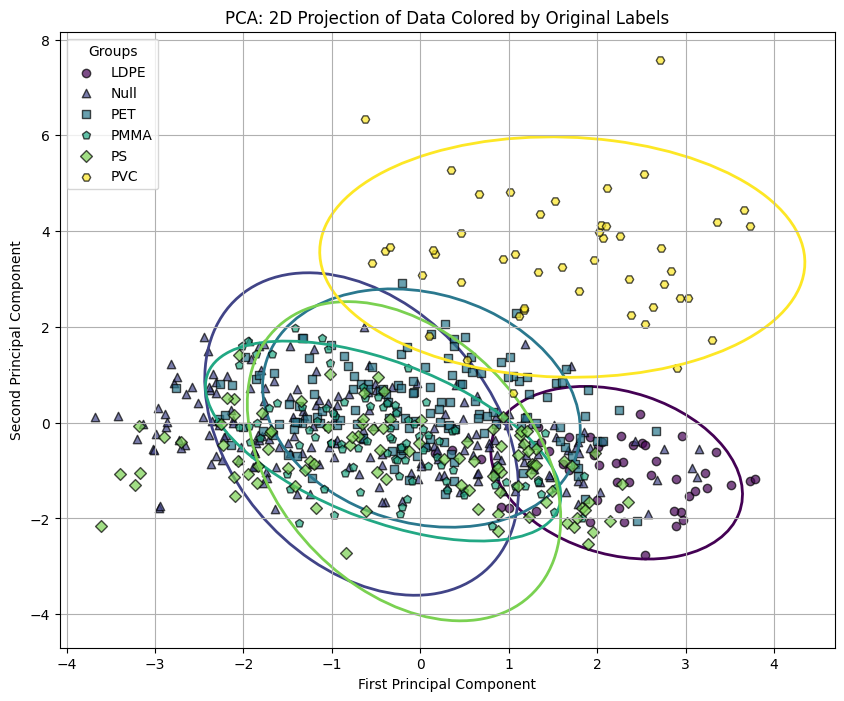

In [ ]:
############################### PCA ###############################
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from matplotlib.patches import Ellipse

# Assuming data and preprocessing steps are done as described earlier
df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False)
group_name = 'Group_MSLVTN'

data = df.dropna(subset=[group_name])
X = data[df.columns[2:-6]] # 2:-7 for slope
y = data[group_name]

le = LabelEncoder()
y_encoded = le.fit_transform(y)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 2: Apply PCA
pca = PCA(n_components=2)  # Reduce to 2 components for visualization
X_pca = pca.fit_transform(X_scaled)

# Step 3: Explained Variance (Optional, to check how much variance each component captures)
explained_variance = pca.explained_variance_ratio_
print("Explained variance ratio for each principal component:", explained_variance)

y_unencoded = le.inverse_transform(y_encoded)

# Step 8: Plot the PCA results, color-coded by the original labels
plt.figure(figsize=(10, 8))

# Step 9: Iterate through each unique category in the unencoded labels and plot separately for legend
unique_labels = np.unique(y_unencoded)  # Get unique unencoded labels
colors = plt.cm.viridis(np.linspace(0, 1, len(unique_labels)))  # Generate a color map

# Different markers for each label
markers = ['o', '^', 's', 'p', 'D', 'H', '+', 'x']  # Add more if needed

for i, label in enumerate(unique_labels):
    # Select the points corresponding to the current label
    mask = y_unencoded == label
    pca_points = X_pca[mask]

    # Plot the scatter points with a different marker for each label
    plt.scatter(pca_points[:, 0], pca_points[:, 1],
                label=label,  # Label for the legend
                color=colors[i],  # Color for the points
                edgecolors='k', alpha=0.7, marker=markers[i % len(markers)])

    # Fit ellipse around the points
    mean = np.mean(pca_points, axis=0)  # Mean of the points (center of the ellipse)
    cov = np.cov(pca_points.T)  # Covariance of the points
    v, w = np.linalg.eigh(cov)  # Eigenvectors and eigenvalues of the covariance matrix
    v = 3.0 * np.sqrt(2.0) * np.sqrt(v)  # Scaling the axes for better visibility

    # Create the ellipse
    ellipse = Ellipse(mean, v[0], v[1], angle=np.degrees(np.arctan(w[0, 0] / w[1, 0])),
                      edgecolor=colors[i], facecolor='none', lw=2)

    # Add ellipse to plot
    plt.gca().add_patch(ellipse)

# Step 10: Set the labels and title for the plot
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA: 2D Projection of Data Colored by Original Labels')

# Step 11: Add a legend using unencoded labels
plt.legend(title='Groups', loc='best')

plt.grid(True)

# Show the plot
plt.show()


##Old & Backups

In [ ]:
def FeatureSelectionGeneral(group_name, df, selection_type='forward', model_type='SVM', max_features=None,
                                  min_improvement=0.1, randomState=42, dataType='bic',
                                  printFlag=True, plotFlag=False, **model_kwargs):
    """
    Generalized forward feature selection using BIC as the selection criterion.
    Works with multiple ML algorithms: XGB, SVM, LDA, LR, LRL1, kNN

    Parameters:
    -----------
    group_name : str
        Group identifier for data preparation
    df : DataFrame
        Input dataframe
    model_type : str
        Type of model to use ('XGB', 'SVM', 'LDA', 'LR', 'LRL1', 'kNN')
    max_features : int, optional
        Maximum number of features to select (default: all features)
    min_improvement : float
        Minimum BIC improvement required to continue selection (default: 0.1)
    randomState : int
        Random state for reproducibility (default: 42)
    dataType : str
        Data type identifier (default: 'k')
    printFlag : bool
        Whether to print progress information (default: True)
    plotFlag : bool
        Whether to plot BIC progression (default: True)
    **model_kwargs : dict
        Additional keyword arguments for the specific model functions

    Returns:
    --------
    dict : Dictionary containing selected features, BIC progression, and final model results
    """

    from sklearn.metrics import accuracy_score, log_loss
    from sklearn.model_selection import cross_val_score
    import warnings
    warnings.filterwarnings('ignore')

    # Model function mapping
    MODEL_FUNCTIONS = {
        'XGB': RunXGBoost,
        'SVM': RunSVM,
        'LDA': RunLDA,
        'LR': RunLR,
        'LRL1': RunLRL1,
        'kNN': RunkNN
    }

    # Validate model type
    if model_type not in MODEL_FUNCTIONS:
        raise ValueError(f"Model type '{model_type}' not supported. "
                        f"Choose from: {list(MODEL_FUNCTIONS.keys())}")

    model_func = MODEL_FUNCTIONS[model_type]
    try:
        # Get initial data preparation
        X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, X, y, y_orig, le = PrepXY(
            group_name, df, printFlag=False, randomState=randomState, dataType='k'
        )
    except Exception as e:
        if printFlag:
            print(f"Error in data preparation: {e}")
        return _create_error_result(str(e))

    # Validate data
    if X_train.shape[0] == 0 or X_test.shape[0] == 0:
        if printFlag:
            print("Error: No samples in training or test data")
        return _create_error_result('No samples in data')

    if X_train.shape[1] == 0:
        if printFlag:
            print("Error: No features available for selection")
        return _create_error_result('No features available')

    all_features = list(X_train.columns)
    selected_features = []
    remaining_features = all_features.copy()

    # Track progression
    bic_history = []
    feature_history = []
    accuracy_history = []
    model_results_history = []

    if max_features is None:
        max_features = len(all_features)

    if printFlag:
        print(f"Starting {selection_type} Feature Selection with {len(all_features)} total features")
        print(f"Model: {model_type}, Max features: {max_features}")
        print("-" * 60)

    best_bic = float('inf')
    if selection_type == 'forward':
        # Forward selection loop
        for step in range(min(max_features, len(all_features))):
            best_feature = None
            best_step_bic = float('inf')
            best_step_results = None
            best_model_output = None

            if printFlag:
                print(f"\nStep {step + 1}: Testing {len(remaining_features)} remaining features...")

            # Test each remaining feature
            for feature in remaining_features:
                current_features = selected_features + [feature]
                #print(f'Current Feature is {current_features}')

                try:
                    # Create subset dataframe with only current features
                    feature_columns = [col for col in df.columns if col in current_features or
                                    col in [group_name]]  # Keep Group column
                    temp_df = df[feature_columns].copy()
                    #print(temp_df)

                    # Run the model with current feature set
                    model_results = model_func(
                        group_name=group_name,
                        df=temp_df,
                        randomState=randomState,
                        dataType=dataType,
                        printFlag=False,
                        BICFlag=True,
                        **model_kwargs
                    )

                    # Extract key metrics
                    if 'error' in model_results:
                        if printFlag and len(remaining_features) <= 10:
                            print(f"  Feature '{feature}': Error - {model_results['error']}")
                        continue

                    # Calculate BIC
                    bic = model_results.get("bic", None)
                    #print(f'BIC is {bic}')
                    #print(model_results)
                    accuracy = model_results.get('accuracy', None)

                    # Check if this is the best BIC for this step
                    if bic < best_step_bic:
                        best_step_bic = bic
                        best_feature = feature
                        best_step_results = {
                            'bic': bic,
                            'accuracy': accuracy,
                            'features': current_features.copy(),
                            'n_features': len(current_features)
                        }
                        best_model_output = model_results

                    if printFlag and len(remaining_features) <= 10:
                        print(f"  Feature '{feature}': BIC = {bic:.4f}, Accuracy = {accuracy:.4f}")

                except Exception as e:
                    if printFlag:
                        print(f"  Error testing feature '{feature}': {e}")
                    continue

            # Check if we found a good feature to add
            if best_feature is None:
                if printFlag:
                    print("No valid features found to add. Stopping selection.")
                break

            # Check for improvement
            if step > 0 and (best_bic - best_step_bic) < min_improvement:
                if printFlag:
                    print(f"BIC improvement ({best_bic - best_step_bic:.4f}) below threshold ({min_improvement}). Stopping.")
                break

            # Add the best feature
            selected_features.append(best_feature)
            remaining_features.remove(best_feature)
            best_bic = best_step_bic

            # Record history
            bic_history.append(best_step_bic)
            feature_history.append(best_feature)
            accuracy_history.append(best_step_results['accuracy'])
            model_results_history.append(best_model_output)

            if printFlag:
                print(f"Added feature: '{best_feature}'")
                print(f"BIC: {best_step_bic:.4f}, Accuracy: {best_step_results['accuracy']:.4f}")
                print(f"Current features ({len(selected_features)}): {selected_features}")

    # Final results summary
    if printFlag:
        print(f"\n{'='*60}")
        print("FORWARD FEATURE SELECTION COMPLETE")
        print(f"{'='*60}")
        print(f"Model Type: {model_type}")
        print(f"Selected {len(selected_features)} features:")
        for i, feature in enumerate(selected_features, 1):
            print(f"  {i:2d}. {feature}")

    # Train final model with selected features
    final_model_results = None
    if selected_features:
        try:
            # Create final dataframe with selected features
            final_feature_columns = [col for col in df.columns if col in current_features or
                                    col in [group_name]]
            final_df = df[final_feature_columns].copy()

            # Train final model
            final_model_results = model_func(
                group_name=group_name,
                df=final_df,
                randomState=randomState,
                dataType=dataType,
                printFlag=printFlag,
                **model_kwargs
            )

            if printFlag and 'error' not in final_model_results:
                print(f"\nFinal model performance:")
                print(f"Test Accuracy: {final_model_results.get('accuracy', None):.4f}")
                print(f"Final BIC: {bic_history[-1] if bic_history else 'N/A':.4f}")

        except Exception as e:
            if printFlag:
                print(f"Error training final model: {e}")

    # Prepare final results
    final_results = {
        'model_type': model_type,
        'selected_features': selected_features,
        'bic_history': bic_history,
        'feature_history': feature_history,
        'accuracy_history': accuracy_history,
        'model_results_history': model_results_history,
        'final_bic': bic_history[-1] if bic_history else float('inf'),
        'final_accuracy': accuracy_history[-1] if accuracy_history else 0,
        'final_model_results': final_model_results,
        'n_features_selected': len(selected_features),
        'total_features_available': len(all_features)
    }

    # Plot progression
    if plotFlag and bic_history:
        _plot_selection_results(bic_history, accuracy_history, feature_history, model_type)

    return final_results
def ForwardFeatureSelectionGeneral(group_name, df, model_type='SVM', max_features=None,
                                  min_improvement=0.1, randomState=42, dataType='bic',
                                  printFlag=True, plotFlag=False, **model_kwargs):
    """
    Generalized forward feature selection using BIC as the selection criterion.
    Works with multiple ML algorithms: XGB, SVM, LDA, LR, LRL1, kNN

    Parameters:
    -----------
    group_name : str
        Group identifier for data preparation
    df : DataFrame
        Input dataframe
    model_type : str
        Type of model to use ('XGB', 'SVM', 'LDA', 'LR', 'LRL1', 'kNN')
    max_features : int, optional
        Maximum number of features to select (default: all features)
    min_improvement : float
        Minimum BIC improvement required to continue selection (default: 0.1)
    randomState : int
        Random state for reproducibility (default: 42)
    dataType : str
        Data type identifier (default: 'k')
    printFlag : bool
        Whether to print progress information (default: True)
    plotFlag : bool
        Whether to plot BIC progression (default: True)
    **model_kwargs : dict
        Additional keyword arguments for the specific model functions

    Returns:
    --------
    dict : Dictionary containing selected features, BIC progression, and final model results
    """

    from sklearn.metrics import accuracy_score, log_loss
    from sklearn.model_selection import cross_val_score
    import warnings
    warnings.filterwarnings('ignore')

    # Model function mapping
    MODEL_FUNCTIONS = {
        'XGB': RunXGBoost,
        'SVM': RunSVM,
        'LDA': RunLDA,
        'LR': RunLR,
        'LRL1': RunLRL1,
        'kNN': RunkNN
    }

    # Validate model type
    if model_type not in MODEL_FUNCTIONS:
        raise ValueError(f"Model type '{model_type}' not supported. "
                        f"Choose from: {list(MODEL_FUNCTIONS.keys())}")

    model_func = MODEL_FUNCTIONS[model_type]
    try:
        # Get initial data preparation
        X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, X, y, y_orig, le = PrepXY(
            group_name, df, printFlag=False, randomState=randomState, dataType='k'
        )
    except Exception as e:
        if printFlag:
            print(f"Error in data preparation: {e}")
        return _create_error_result(str(e))

    # Validate data
    if X_train.shape[0] == 0 or X_test.shape[0] == 0:
        if printFlag:
            print("Error: No samples in training or test data")
        return _create_error_result('No samples in data')

    if X_train.shape[1] == 0:
        if printFlag:
            print("Error: No features available for selection")
        return _create_error_result('No features available')

    all_features = list(X_train.columns)
    selected_features = []
    remaining_features = all_features.copy()

    # Track progression
    bic_history = []
    feature_history = []
    accuracy_history = []
    model_results_history = []

    if max_features is None:
        max_features = len(all_features)

    if printFlag:
        print(f"Starting Forward Feature Selection with {len(all_features)} total features")
        print(f"Model: {model_type}, Max features: {max_features}")
        print("-" * 60)

    best_bic = float('inf')

    # Forward selection loop
    for step in range(min(max_features, len(all_features))):
        best_feature = None
        best_step_bic = float('inf')
        best_step_results = None
        best_model_output = None

        if printFlag:
            print(f"\nStep {step + 1}: Testing {len(remaining_features)} remaining features...")

        # Test each remaining feature
        for feature in remaining_features:
            current_features = selected_features + [feature]
            #print(f'Current Feature is {current_features}')

            try:
                # Create subset dataframe with only current features
                feature_columns = [col for col in df.columns if col in current_features or
                                 col in [group_name]]  # Keep Group column
                temp_df = df[feature_columns].copy()
                #print(temp_df)

                # Run the model with current feature set
                model_results = model_func(
                    group_name=group_name,
                    df=temp_df,
                    randomState=randomState,
                    dataType=dataType,
                    printFlag=False,
                    BICFlag=True,
                    **model_kwargs
                )

                # Extract key metrics
                if 'error' in model_results:
                    if printFlag and len(remaining_features) <= 10:
                        print(f"  Feature '{feature}': Error - {model_results['error']}")
                    continue

                # Calculate BIC
                bic = model_results.get("bic", None)
                #print(f'BIC is {bic}')
                #print(model_results)
                accuracy = model_results.get('accuracy', None)

                # Check if this is the best BIC for this step
                if bic < best_step_bic:
                    best_step_bic = bic
                    best_feature = feature
                    best_step_results = {
                        'bic': bic,
                        'accuracy': accuracy,
                        'features': current_features.copy(),
                        'n_features': len(current_features)
                    }
                    best_model_output = model_results

                if printFlag and len(remaining_features) <= 10:
                    print(f"  Feature '{feature}': BIC = {bic:.4f}, Accuracy = {accuracy:.4f}")

            except Exception as e:
                if printFlag:
                    print(f"  Error testing feature '{feature}': {e}")
                continue

        # Check if we found a good feature to add
        if best_feature is None:
            if printFlag:
                print("No valid features found to add. Stopping selection.")
            break

        # Check for improvement
        if step > 0 and (best_bic - best_step_bic) < min_improvement:
            if printFlag:
                print(f"BIC improvement ({best_bic - best_step_bic:.4f}) below threshold ({min_improvement}). Stopping.")
            break

        # Add the best feature
        selected_features.append(best_feature)
        remaining_features.remove(best_feature)
        best_bic = best_step_bic

        # Record history
        bic_history.append(best_step_bic)
        feature_history.append(best_feature)
        accuracy_history.append(best_step_results['accuracy'])
        model_results_history.append(best_model_output)

        if printFlag:
            print(f"Added feature: '{best_feature}'")
            print(f"BIC: {best_step_bic:.4f}, Accuracy: {best_step_results['accuracy']:.4f}")
            print(f"Current features ({len(selected_features)}): {selected_features}")

    # Final results summary
    if printFlag:
        print(f"\n{'='*60}")
        print("FORWARD FEATURE SELECTION COMPLETE")
        print(f"{'='*60}")
        print(f"Model Type: {model_type}")
        print(f"Selected {len(selected_features)} features:")
        for i, feature in enumerate(selected_features, 1):
            print(f"  {i:2d}. {feature}")

    # Train final model with selected features
    final_model_results = None
    if selected_features:
        try:
            # Create final dataframe with selected features
            final_feature_columns = [col for col in df.columns if col in selected_features or
                                   col in ['Group', 'Label']]
            final_df = df[final_feature_columns].copy()

            # Train final model
            final_model_results = model_func(
                group_name=group_name,
                df=final_df,
                randomState=randomState,
                dataType=dataType,
                printFlag=printFlag,
                **model_kwargs
            )

            if printFlag and 'error' not in final_model_results:
                print(f"\nFinal model performance:")
                print(f"Training Accuracy: {final_model_results.get('train_accuracy', 'N/A'):.4f}")
                print(f"Test Accuracy: {final_model_results.get('test_accuracy', 'N/A'):.4f}")
                print(f"Final BIC: {bic_history[-1] if bic_history else 'N/A':.4f}")

        except Exception as e:
            if printFlag:
                print(f"Error training final model: {e}")

    # Prepare final results
    final_results = {
        'model_type': model_type,
        'selected_features': selected_features,
        'bic_history': bic_history,
        'feature_history': feature_history,
        'accuracy_history': accuracy_history,
        'model_results_history': model_results_history,
        'final_bic': bic_history[-1] if bic_history else float('inf'),
        'final_accuracy': accuracy_history[-1] if accuracy_history else 0,
        'final_model_results': final_model_results,
        'n_features_selected': len(selected_features),
        'total_features_available': len(all_features)
    }

    # Plot progression
    if plotFlag and bic_history:
        _plot_selection_results(bic_history, accuracy_history, feature_history, model_type)

    return final_results


def _plot_selection_results(bic_history, accuracy_history, feature_history, model_type):
    """Plot the feature selection progression"""
    import matplotlib.pyplot as plt

    plt.figure(figsize=(15, 5))

    # BIC progression
    plt.subplot(1, 3, 1)
    plt.plot(range(1, len(bic_history) + 1), bic_history, 'bo-', linewidth=2, markersize=8)
    plt.xlabel('Number of Features')
    plt.ylabel('BIC')
    plt.title(f'BIC vs Number of Features\n({model_type} Model)')
    plt.grid(True, alpha=0.3)

    # Accuracy progression
    plt.subplot(1, 3, 2)
    plt.plot(range(1, len(accuracy_history) + 1), accuracy_history, 'ro-', linewidth=2, markersize=8)
    plt.xlabel('Number of Features')
    plt.ylabel('Accuracy')
    plt.title(f'Accuracy vs Number of Features\n({model_type} Model)')
    plt.grid(True, alpha=0.3)

    # Feature selection order
    plt.subplot(1, 3, 3)
    y_pos = range(len(feature_history))
    plt.barh(y_pos, range(1, len(feature_history) + 1), alpha=0.7)
    plt.yticks(y_pos, [f[:20] + '...' if len(f) > 20 else f for f in feature_history])
    plt.xlabel('Selection Order')
    plt.title(f'Feature Selection Order\n({model_type} Model)')
    plt.gca().invert_yaxis()

    plt.tight_layout()
    plt.show()


# Convenience wrapper functions for specific models
def ForwardFeatureSelectionXGB(group_name, df, **kwargs):
    """Forward feature selection using XGBoost"""
    return ForwardFeatureSelectionGeneral(group_name, df, model_type='XGB', **kwargs)

def ForwardFeatureSelectionSVM(group_name, df, **kwargs):
    """Forward feature selection using SVM"""
    return ForwardFeatureSelectionGeneral(group_name, df, model_type='SVM', **kwargs)

def ForwardFeatureSelectionLDA(group_name, df, **kwargs):
    """Forward feature selection using LDA"""
    return ForwardFeatureSelectionGeneral(group_name, df, model_type='LDA', **kwargs)

def ForwardFeatureSelectionLR(group_name, df, **kwargs):
    """Forward feature selection using Logistic Regression"""
    return ForwardFeatureSelectionGeneral(group_name, df, model_type='LR', **kwargs)

def ForwardFeatureSelectionLRL1(group_name, df, **kwargs):
    """Forward feature selection using L1 Logistic Regression"""
    return ForwardFeatureSelectionGeneral(group_name, df, model_type='LRL1', **kwargs)

def ForwardFeatureSelectionkNN(group_name, df, **kwargs):
    """Forward feature selection using k-Nearest Neighbors"""
    return ForwardFeatureSelectionGeneral(group_name, df, model_type='kNN', **kwargs)


#### Main Code ####

FilePath = '/content/drive/MyDrive/Lexi/MNP/Round_2/KH_Data/20250807KH_combined.csv'
#Group_Null
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedNotReagentsList = ['CH', 'CL'])
#Group_PN
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False)
#Group_Full
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False)
#Group_MSLVTN
#df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False)
#Group_PN, kh k, no mixed solvents for plastics
df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False, selectedNotPlasticsList = ['BCH', 'BCM', 'BCL', 'CCH', 'CCM', 'CCL', 'MSH', 'MSM', 'MSL', 'SSH', 'SSM', 'SSL'])
# Single model feature selection
#results_xgb = ForwardFeatureSelectionXGB('Group_PN', df, max_features=10)

# Use with custom parameters
results_svm = ForwardFeatureSelectionGeneral(
    'Group_Full', df,
    model_type='SVM',
    kernelType='rbf',  # only used in RunSVM
    max_features=20
)

Plastic:432 Null:192
Completing 1 of 1 Model Rounds

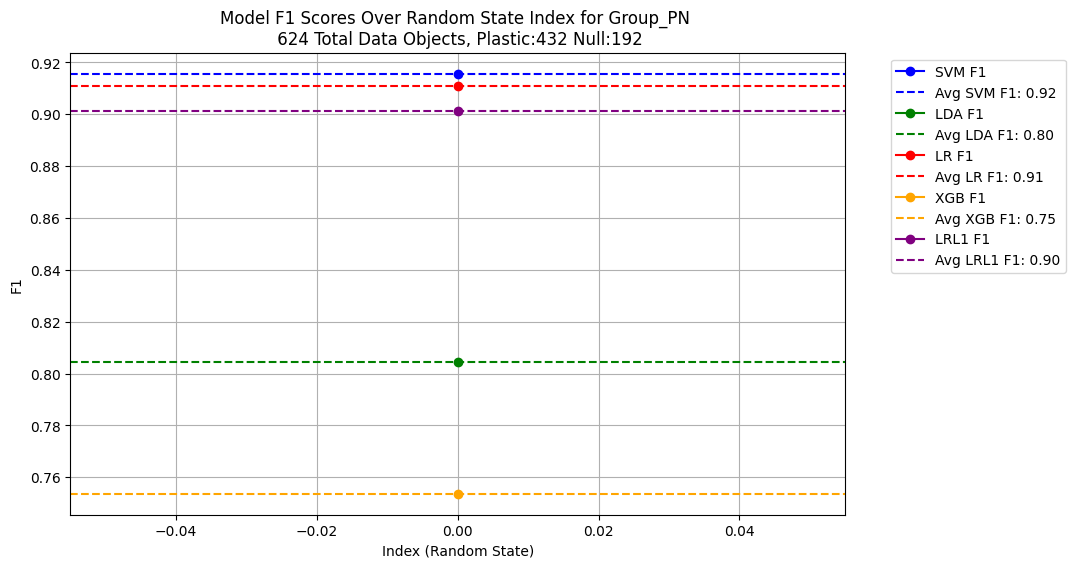

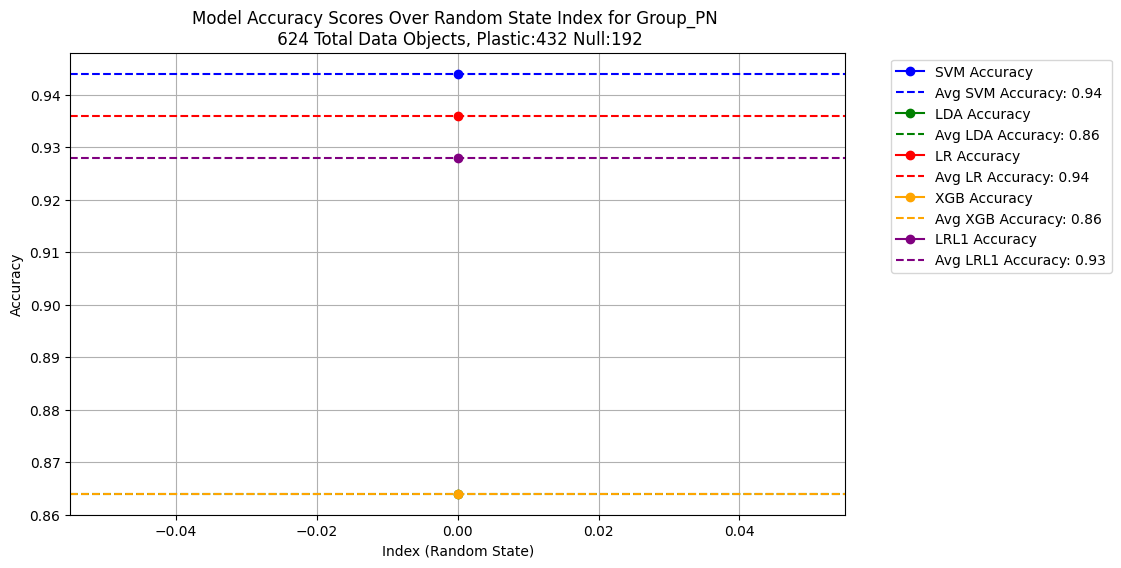

In [ ]:
########## OLD Main Code, Sandbox for F1 ##########
warnings.filterwarnings("ignore", category=FutureWarning)
FilePath = '/content/drive/MyDrive/Lexi/MNP/ML Analysis/20250422AIC25s_combined.csv'
df = WrangleData(FilePath, printFlag=False)
#df = df[((df['Group_MHL'] == 'High') | (df['Group_PN'] == 'Null'))]

group_name = 'Group_PN'
accuracy_df = pd.DataFrame(columns=['random_state', 'SVM_Accuracy', 'LDA_Accuracy', 'LR_Accuracy', 'XGB_Accuracy', 'LRL1_Accuracy'])
f1_df = pd.DataFrame(columns=['random_state', 'SVM_F1', 'LDA_F1', 'LR_F1', "XGB_F1", "LRL1_F1"])
row_counts = df[group_name].value_counts()
formatted_counts = ' '.join(f'{group}:{count}' for group, count in row_counts.items())
print(formatted_counts)
#nan_count = df.isna().sum()
#print(nan_count.sort_values(ascending=False))
#rs_vec = [64678, 51344, 83865, 94980, 72813, 32674, 97809, 976, 35697, 61084]
rs_vec = random.sample(range(1, 100001), 1)

cmFlag = False
f1Flag = True
swapLabel = True
num_rows = df.shape[0]

##Need to add average='samples' to all F1 scores

if f1Flag:
    for i, rs in (enumerate(rs_vec, 1)):
        print(f"\r\033[1mCompleting {i} of {len(rs_vec)}\033[0m Model Rounds", end='', flush=True)
        a_xgb, f1_xgb = RunXGBoost(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag, swapLabel=swapLabel)
        a_svm, f1_svm = RunSVM(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag, swapLabel=swapLabel)
        a_lda, f1_lda = RunLDA(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag, swapLabel=swapLabel)
        a_lr, f1_lr = RunLR(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag, swapLabel=swapLabel)
        a_lrl1, f1_lrl1 = RunLRL1(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag, swapLabel=swapLabel)
        new_row = pd.DataFrame({'random_state': [rs], 'SVM_Accuracy': [a_svm], 'LDA_Accuracy': [a_lda], 'LR_Accuracy': [a_lr], 'XGB_Accuracy': [a_xgb], 'LRL1_Accuracy': [a_lrl1]})
        new_row_f1 = pd.DataFrame({'random_state': [rs], 'SVM_F1': [f1_svm], 'LDA_F1': [f1_lda], 'LR_F1': [f1_lr], 'XGB_F1': [f1_xgb], 'LRL1_F1': [f1_lrl1]})
        accuracy_df = pd.concat([accuracy_df, new_row], ignore_index=True)
        f1_df = pd.concat([f1_df, new_row_f1], ignore_index=True)
    PlotAvgIndex(group_name, f1_df, "F1", num_rows, formatted_counts)
    PlotAvgIndex(group_name, accuracy_df, "Accuracy", num_rows, formatted_counts)
else:
    for i, rs in (enumerate(rs_vec, 1)):
        print(f"\r\033[1mCompleting {i} of {len(rs_vec)}\033[0m Model Rounds", end='', flush=True)
        a_xgb = RunXGBoost(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag, swapLabel=swapLabel)
        a_svm = RunSVM(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag, swapLabel=swapLabel)
        a_lda = RunLDA(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag, swapLabel=swapLabel)
        a_lr = RunLR(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag, swapLabel=swapLabel)
        a_lrl1 = RunLRL1(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag, swapLabel=swapLabel)
        new_row = pd.DataFrame({'random_state': [rs], 'SVM_Accuracy': [a_svm], 'LDA_Accuracy': [a_lda], 'LR_Accuracy': [a_lr], 'XGB_Accuracy': [a_xgb], 'LRL1_Accuracy': [a_lrl1]})
        accuracy_df = pd.concat([accuracy_df, new_row], ignore_index=True)
    PlotAvgIndex(group_name, accuracy_df, "Accuracy")


In [ ]:
FilePath = '/content/drive/MyDrive/Lexi/MNP/ML Analysis/20250425AIC25s_combined.csv'
df = WrangleData(FilePath, printFlag=False)
count = df.shape[1]
print(df["Plastic"].unique())
FitData = pd.read_csv(FilePath, index_col=0)
FitData.reset_index(0, inplace=True)
dataFrame = FitData.copy()
#dataFrame["Plastic"] = dataFrame['Plastic'].astype(str)
print(dataFrame["Plastic"].unique())

['1' '15' '16' '17' '18' '2' '25' '26' '27' '28' '3' '4' 'BCH' 'BCL' 'BCM'
 'CCH' 'CCL' 'CCM' 'LCH' 'LCL' 'LCM' 'MCH' 'MCL' 'MCM' 'MSH' 'MSL' 'MSM'
 'SCH' 'SCL' 'SCM' 'SSH' 'SSL' 'SSM' 'TCH' 'TCL' 'TCM' 'VCH' 'VCL' 'VCM']
['SC0' 'SCH' 'SCL' 'SCM' '0' '1' '2' '3' '4' 'MS0' 'MSH' 'MSL' 'MSM' 'MC0'
 'MCH' 'MCL' 'MCM' 'SS0' 'SSH' 'SSL' 'SSM' 'LC0' 'LCH' 'LCL' 'LCM' 'VC0'
 'VCH' 'VCL' 'VCM' 'TC0' 'TCH' 'TCL' 'TCM' 'BC0' 'BCH' 'BCL' 'BCM' '10'
 '15' '16' '17' '18' '20' '25' '26' '27' '28' 'CC0' 'CCH' 'CCL' 'CCM']


In [ ]:
########## OLD Main Code, Sandbox for F1 Boxplot ##########
FilePath = '/content/drive/MyDrive/Lexi/MNP/ML Analysis/20250422AIC25s_combined.csv'
df = WrangleData(FilePath, printFlag=False)
#df = df[((df['Group_MHL'] == 'High') | (df['Group_PN'] == 'Null'))]

group_name = 'Group_PN'
accuracy_df = pd.DataFrame(columns=['random_state', 'SVM', 'LDA', 'LR', 'XGB', 'LRL1'])
f1_df = pd.DataFrame(columns=['random_state', 'SVM', 'LDA', 'LR', "XGB", "LRL1"])
df[group_name].value_counts()
#nan_count = df.isna().sum()

#print(nan_count.sort_values(ascending=False))


cmFlag = False
f1Flag = True
for i, rs in enumerate(random.sample(range(1, 100001), 20), 0):
  a_xgb, f1_xgb = RunXGBoost(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag)
  a_svm, f1_svm = RunSVM(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag)
  a_lda, f1_lda = RunLDA(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag)
  a_lr, f1_lr = RunLR(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag)
  a_lrl1, f1_lrl1 = RunLRL1(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag, f1Flag=f1Flag)
  new_row = pd.DataFrame({'random_state': [rs], 'SVM': [a_svm], 'LDA': [a_lda], 'LR': [a_lr], 'XGB': [a_xgb], 'LRL1': [a_lrl1]})
  new_row_f1 = pd.DataFrame({'random_state': [rs], 'SVM': [f1_svm], 'LDA': [f1_lda], 'LR': [f1_lr], 'XGB': [f1_xgb], 'LRL1': [f1_lrl1]})
  accuracy_df = pd.concat([accuracy_df, new_row], ignore_index=True)
  f1_df = pd.concat([f1_df, new_row_f1], ignore_index=True)

plt.figure(figsize=(10, 6))

ax = accuracy_df.plot(kind='box')
plt.title(f'Model Accuracies for {group_name}')
ax.set_ylabel("Accuracy")

# Show the plot
plt.grid(True)
plt.show()

""" F1 Plot"""
plt.figure(figsize=(10, 6))

ax = f1_df.plot(kind='box')
plt.title(f'Model F1 Scores for {group_name}')
ax.set_ylabel("F1 Score")

# Show the plot
plt.grid(True)
plt.show()

KeyboardInterrupt: 

In [ ]:
rs_vec = random.sample(range(1, 100001), 10)
print(rs_vec)

[4356, 90104, 83865, 11091, 67440, 26753, 72998, 44118, 59793, 57465]


Completing 10 of 10 Model Rounds

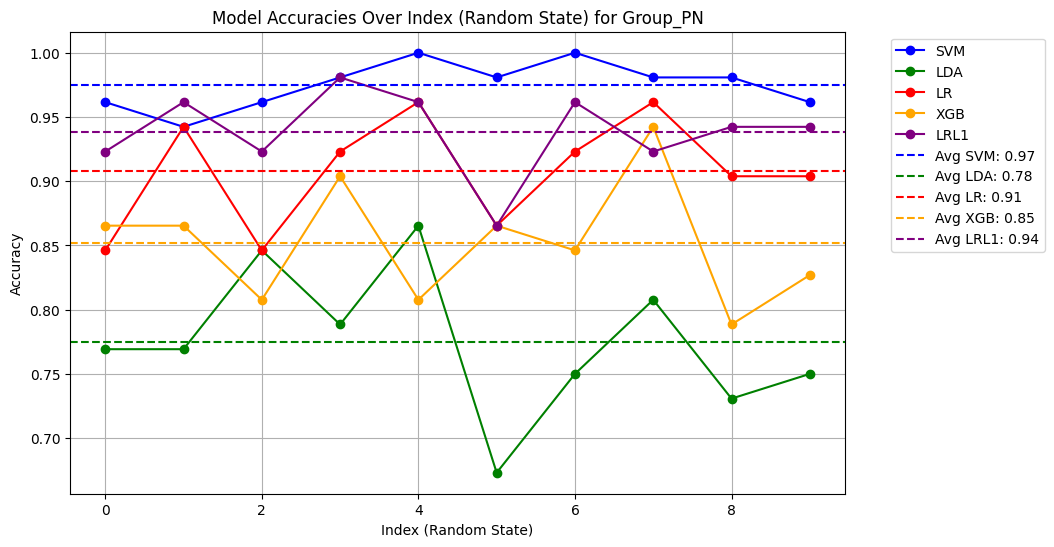

In [ ]:
########## OLD Main Code, Stable ##########
warnings.filterwarnings("ignore", category=FutureWarning)
FilePath = '/content/drive/MyDrive/Lexi/MNP/ML Analysis/20250422AIC25s_combined.csv'
df = WrangleData(FilePath, printFlag=False)


df = df[((df['Group_MHL'] == 'High') | (df['Group_PN'] == 'Null'))]
cmFlag = False
#rs_vec = random.sample(range(1, 100001), 10)
rs_vec = [64678, 51344, 83865, 94980, 72813, 32674, 97809, 976, 35697, 61084]
group_name = 'Group_PN'



accuracy_df = pd.DataFrame(columns=['random_state', 'SVM_Accuracy', 'LDA_Accuracy', 'LR_Accuracy', "LRL1_Accuracy"])
df[group_name].value_counts()
#nan_count = df.isna().sum()

#print(nan_count.sort_values(ascending=False))

for i, rs in enumerate(rs_vec, 1):
    print(f"\r\033[1mCompleting {i} of {len(rs_vec)}\033[0m Model Rounds", end='', flush=True)
    a_xgb = RunXGBoost(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag)
    a_svm = RunSVM(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag)
    a_lda = RunLDA(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag)
    a_lr = RunLR(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag)
    a_lrl1 = RunLRL1(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=cmFlag)
    new_row = pd.DataFrame({'random_state': [rs], 'SVM_Accuracy': [a_svm], 'LDA_Accuracy': [a_lda], 'LR_Accuracy': [a_lr], 'XGB_Accuracy': [a_xgb], 'LRL1_Accuracy': [a_lrl1]})
    accuracy_df = pd.concat([accuracy_df, new_row], ignore_index=True)
#display(accuracy_df)

plt.figure(figsize=(10, 6))
average_svm = accuracy_df['SVM_Accuracy'].mean()
average_lda = accuracy_df['LDA_Accuracy'].mean()
average_lr = accuracy_df['LR_Accuracy'].mean()
average_xgb = accuracy_df['XGB_Accuracy'].mean()
average_lrl1 = accuracy_df['LRL1_Accuracy'].mean()

# Plot each accuracy column
plt.plot(accuracy_df.index, accuracy_df['SVM_Accuracy'], label='SVM', marker='o', linestyle='-', color='b')
plt.plot(accuracy_df.index, accuracy_df['LDA_Accuracy'], label='LDA', marker='o', linestyle='-', color='g')
plt.plot(accuracy_df.index, accuracy_df['LR_Accuracy'], label='LR', marker='o', linestyle='-', color='r')
plt.plot(accuracy_df.index, accuracy_df['XGB_Accuracy'], label='XGB', marker='o', linestyle='-', color='orange')
plt.plot(accuracy_df.index, accuracy_df['LRL1_Accuracy'], label='LRL1', marker='o', linestyle='-', color='purple')
plt.axhline(y=average_svm, color='b', linestyle='--', label=f'Avg SVM: {average_svm:.2f}')
plt.axhline(y=average_lda, color='g', linestyle='--', label=f'Avg LDA: {average_lda:.2f}')
plt.axhline(y=average_lr, color='r', linestyle='--', label=f'Avg LR: {average_lr:.2f}')
plt.axhline(y=average_xgb, color='orange', linestyle='--', label=f'Avg XGB: {average_xgb:.2f}')
plt.axhline(y=average_lrl1, color='purple', linestyle='--', label=f'Avg LRL1: {average_lrl1:.2f}')


# Adding labels and title
plt.xlabel('Index (Random State)')
plt.ylabel('Accuracy')
plt.title(f'Model Accuracies Over Index (Random State) for {group_name}')

# Adding random_state labels to the plot
#for i, txt in enumerate(accuracy_df['random_state']):
#    plt.annotate(txt, (accuracy_df.index[i], accuracy_df['SVM_Accuracy'][i]), textcoords="offset points", xytext=(0, 5), ha='center')

# Show the legend
#plt.legend()
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Show the plot
plt.grid(True)
plt.show()


##Breaking Models Attempt

<ipython-input-17-c6e8d106c022>:39: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  accuracy_df = pd.concat([accuracy_df, new_row], ignore_index=True)


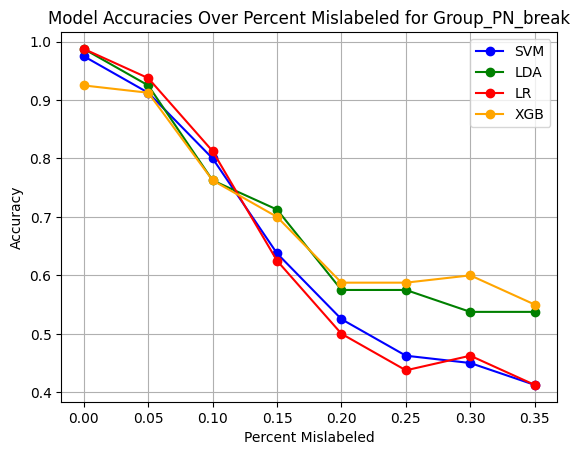

In [ ]:
########## 'Breaking Models' Attempt 1 ##########
FilePath = '/content/drive/MyDrive/Lexi/MNP/ML Analysis/20250310AIC25s_combined.csv'
df = WrangleData(FilePath, selectedNotReagentsList = ['KH', 'KL'], printFlag=False)

#print(df)

group_name = 'Group_PN'
break_name = group_name + "_break"
percentages_to_change = np.arange(0, 0.4, 0.05)
accuracy_df = pd.DataFrame(columns=['random_state', 'SVM_Accuracy', 'LDA_Accuracy', 'LR_Accuracy', 'percent_mislabeled'])
for percent_to_change in percentages_to_change:
    # Calculate the number of rows to modify
    num_rows_to_change = int(len(df) * percent_to_change)
    # Create the new column 'Group_Full_Break' initially as a copy of 'Group_Full'
    df[break_name] = df[group_name]

    # Randomly select the rows to modify
    rows_to_modify = np.random.choice(df.index, size=num_rows_to_change, replace=False)

    # Get unique categories from 'Group_Full' column
    existing_categories = df[group_name].unique()

    # Assign new values to 'Group_Full_Break' for the selected rows from existing categories (excluding current values)
    for row in rows_to_modify:
        current_value = df.loc[row, group_name]
        # Remove the current value from the list of categories to avoid assigning the same value
        available_categories = existing_categories[existing_categories != current_value]

        # Randomly pick a new value from the remaining categories
        df.loc[row, break_name] = np.random.choice(available_categories)

    group_name = break_name
    rs=42
    a_xgb = RunXGBoost(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=False)
    a_svm = RunSVM(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=False)
    a_lda = RunLDA(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=False)
    a_lr = RunLR(group_name, df, residualsFlag=False, randomState=rs, classificationReportFlag=False, cmFlag=False)
    new_row = pd.DataFrame({'random_state': [rs], 'percent_mislabeled': [percent_to_change], 'SVM_Accuracy': [a_svm], 'LDA_Accuracy': [a_lda], 'LR_Accuracy': [a_lr], 'XGB_Accuracy': [a_xgb]})
    accuracy_df = pd.concat([accuracy_df, new_row], ignore_index=True)
    #print(accuracy_df)
plt.plot(accuracy_df['percent_mislabeled'], accuracy_df['SVM_Accuracy'], label='SVM', marker='o', linestyle='-', color='b')
plt.plot(accuracy_df['percent_mislabeled'], accuracy_df['LDA_Accuracy'], label='LDA', marker='o', linestyle='-', color='g')
plt.plot(accuracy_df['percent_mislabeled'], accuracy_df['LR_Accuracy'], label='LR', marker='o', linestyle='-', color='r')
plt.plot(accuracy_df['percent_mislabeled'], accuracy_df['XGB_Accuracy'], label='XGB', marker='o', linestyle='-', color='orange')

# Adding labels and title
plt.xlabel('Percent Mislabeled')
plt.ylabel('Accuracy')
plt.title(f'Model Accuracies Over Percent Mislabeled for {group_name}')

# Adding random_state labels to the plot
#for i, txt in enumerate(accuracy_df['random_state']):
#    plt.annotate(txt, (accuracy_df.index[i], accuracy_df['SVM_Accuracy'][i]), textcoords="offset points", xytext=(0, 5), ha='center')

# Show the legend
plt.legend()

# Show the plot
plt.grid(True)
plt.show()

In [ ]:
df_Full_Flat["Group_PN"].value_counts()

,count
Group_PN,
Plastic,96
Null,64


['1' '2' '3' '4' 'TCH' 'TCL' 'TCM' 'BCH' 'BCL' 'BCM']
['Null' 'Plastic']
['Null' 'PET']
['Null' 'TC']
[nan 'High' 'Low' 'Medium']
['1' '2' '3' '4' nan]
Unique Plastics: ['1' '2' '3' '4' 'BCH' 'BCL' 'BCM' 'TCH' 'TCL' 'TCM']
Index(['15_YH', '15_YL', '30_YH', '30_YL', '45_YH', '45_YL', '60_YH', '60_YL',
       '75_YH', '75_YL', '90_YH', '90_YL', '105_YH', '105_YL', '120_YH',
       '120_YL', '135_YH', '135_YL', '150_YH', '150_YL'],
      dtype='object')
Intercept: [3.69907845]
Classes: ['Null' 'Plastic']
Iterations: [52]
Accuracy: 0.875


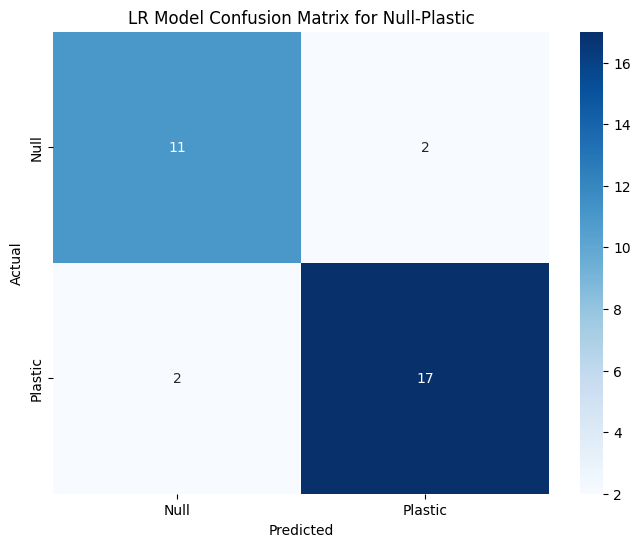

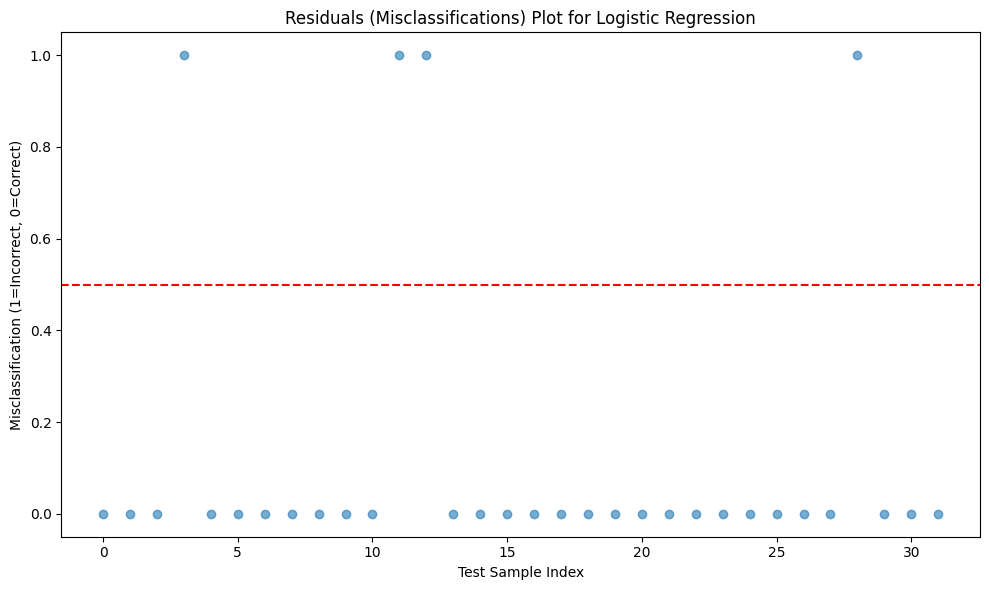

In [ ]:
FilePath = '/content/drive/MyDrive/Lexi/MNP/ML Analysis/20250320AIC25s_combined.csv'
FitData = pd.read_csv(FilePath, index_col=0)
FitData.reset_index(0, inplace=True)
dataFrame = FitData.copy()


#selectedNotReagents = ['KH', 'KL']
selectedReagents = ['YH', 'YL']
#dataFrame = dataFrame[~dataFrame['Reagent'].isin(selectedNotReagents)]
dataFrame = dataFrame[dataFrame['Reagent'].isin(selectedReagents)]
#selectedPlastics = ['MCH', 'MCM', 'MCL', "MSH", "MSM", "MSL", "SCH", "SCM", "SCL", "SSH", "SSM", "SSL", "LCH", "LCM", "LCL", "VCH", "VCM", "VCL", "4", "3", "2", "1", "TCH", "TCM", "TCL"]
selectedPlastics = ["BCH", "BCM", "BCL", "TCH", "TCM", "TCL", "4", "3", "2", "1"]
dataFrame = dataFrame[dataFrame['Plastic'].isin(selectedPlastics)]
print(dataFrame['Plastic'].unique())


#dataFrameOrig = dataFrame
dataFrameFull = pd.pivot_table(dataFrame, values='Adjusted_Slope', index=['Plastic', "Channel"], columns=['WindowEdge', 'Reagent'])
df_Full_Flat = dataFrameFull.copy()
df_Full_Flat.columns = ['_'.join(map(str, col)) for col in df_Full_Flat.columns]


df_Full_Flat = df_Full_Flat.reset_index(0)
df_Full_Flat = df_Full_Flat.reset_index(0)
df_Full_Flat['Group_PN'] = df_Full_Flat['Plastic'].apply(lambda x: 'Plastic' if x[0] in ['M', 'S', 'L', 'T', 'V', 'B'] else 'Null')
#df_Full_Flat['Group_MSN'] = df_Full_Flat['Plastic'].apply(
#    lambda x: 'PMMA' if x[0] == "M" else ('PS' if x[0] == 'S' else ('Null' if x[0] in ["4", "3", "2", "1"] else np.nan))
#)
df_Full_Flat['Group_MSLVTN'] = df_Full_Flat['Plastic'].apply(
      lambda x: 'PMMA' if x[0] == "M" else ('PS' if x[0] == 'S' else ('LDPE' if x[0] == 'L' else ('PVC' if x[0] == 'V' else ('PET' if x[0] == 'T' else 'Null'))))
)
df_Full_Flat['Group_Full'] = df_Full_Flat['Plastic'].apply(
      lambda x: x[0:2] if x[0] in ["M", "S", "L", "V", "T"] else "Null"
)
df_Full_Flat['Group_MHL'] = df_Full_Flat['Plastic'].apply(
      lambda x: np.nan if x[0] in ["4", "3", "2", "1"] else (
      'Medium' if x[2] == "M" else ('High' if x[2] == 'H' else ('Low' if x[2] == 'L' else np.nan)))
)
df_Full_Flat['Group_CS'] = df_Full_Flat['Plastic'].apply(
    lambda x: np.nan if x[0] in ["4", "3", "2", "1"] else (
    'Cryo' if x[1] == "C" else ("Spherical" if x[1] == 'S' else np.nan))
)
df_Full_Flat['Group_Null'] = df_Full_Flat['Plastic'].apply(
      lambda x: x if x[0] in ["1", "2", "3", "4"] else np.nan
)

#display(df_Full_Flat)
print(df_Full_Flat['Group_PN'].unique())
print(df_Full_Flat['Group_MSLVTN'].unique())
print(df_Full_Flat['Group_Full'].unique())
print(df_Full_Flat['Group_MHL'].unique())
print(df_Full_Flat['Group_Null'].unique())


group_name = 'Group_PN'

data = df_Full_Flat.dropna(subset=[group_name])
#data = data[~data['Plastic'].isin(['1', '2', '3', '4', 'SCH', 'SCM', 'SCL', 'MSH', 'MSM', 'MSL'])]
# Define features (X) and target variable (y)
#print(df_Full_Flat.columns[2:-5])
X = data[df_Full_Flat.columns[2:-7]]
#display(X)
y = data[group_name]
#print(df_Full_Flat[group_name].unique())
print(f'Unique Plastics: {data["Plastic"].unique()}')
col_names = X.columns[:20]
print(col_names)
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
"""
testLabels = ["BCH", "BCM", "BCL"]

X_train = X[~df_Full_Flat["Plastic"].isin(testLabels)]
X_test = X[df_Full_Flat["Plastic"].isin(testLabels)]
y_train = y[~df_Full_Flat["Plastic"].isin(testLabels)]
y_test = y[df_Full_Flat["Plastic"].isin(testLabels)]

display(X_train)
display(X_test)
display(y_train)
display(y_test)
"""

# Create a multinomial logistic regression model
model = LogisticRegression(solver='lbfgs')
#print(X_train)
# Fit the model on the training data
model.fit(X_train, y_train)

# Make predictions on the test data
y_pred = model.predict(X_test)

# Evaluate the model's accuracy

#print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("Classes:", model.classes_)
print("Iterations:", model.n_iter_)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=model.classes_, yticklabels=model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'LR Model Confusion Matrix for {str("-".join(y.unique()))}')
plt.show()

y_prob = model.predict_proba(X_test)

# Get the predicted class (the class with the highest predicted probability)
y_pred_class = model.classes_[np.argmax(y_prob, axis=1)]

# Calculate residuals as a binary indicator of misclassifications (1 for incorrect, 0 for correct)
residuals = (y_pred_class != y_test).astype(int)

# Plot residuals (misclassifications)
plt.figure(figsize=(10, 6))
plt.scatter(np.arange(len(y_test)), residuals, alpha=0.6)
plt.axhline(y=0.5, color='r', linestyle='--')  # Reference line for misclassification
plt.title('Residuals (Misclassifications) Plot for Logistic Regression')
plt.xlabel('Test Sample Index')
plt.ylabel('Misclassification (1=Incorrect, 0=Correct)')
plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Classification Report (LR L1):
               precision    recall  f1-score   support

           0       0.90      0.93      0.92        29
           1       0.97      0.96      0.97        74

    accuracy                           0.95       103
   macro avg       0.94      0.95      0.94       103
weighted avg       0.95      0.95      0.95       103

Accuracy of the LRL1 model: 0.9514563106796117


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


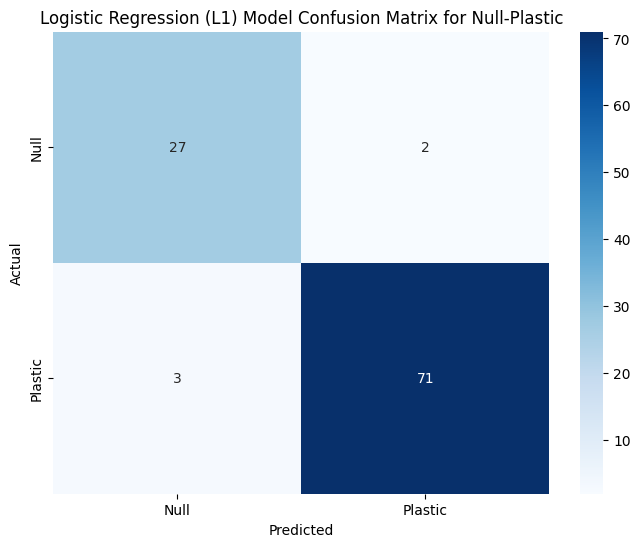

0.9514563106796117

In [ ]:
########## Main Code, Sandbox ##########
FilePath = '/content/drive/MyDrive/Lexi/MNP/ML Analysis/20250406AIC25s_combined.csv'
df = WrangleData(FilePath, selectedNotReagentsList = ['DH', 'DL'], printFlag=False)

#print(df['Plastic'].unique())

group_name = 'Group_PN'
accuracy_df = pd.DataFrame(columns=['random_state', 'SVM_Accuracy', 'LDA_Accuracy', 'LR_Accuracy'])
df[group_name].value_counts()
#nan_count = df.isna().sum()

#print(nan_count.sort_values(ascending=False))

RunLRL1(group_name, df, residualsFlag=False, randomState=42, classificationReportFlag=True, cmFlag=True, printFlag=False)

In [ ]:
df["Group_PN"].value_counts()

,count
Group_PN,
Plastic,336
Null,64


##LR w L1 Regulatization

Unique Plastics: ['1' '2' '3' '4' 'LCH' 'LCL' 'LCM' 'MCH' 'MCL' 'MCM' 'MSH' 'MSL' 'MSM'
 'SCH' 'SCL' 'SCM' 'SSH' 'SSL' 'SSM' 'TCH' 'TCL' 'TCM' 'VCH' 'VCL' 'VCM']
Index(['15_AH', '15_AL', '15_BH', '15_BL', '15_CH', '15_CL', '15_DH', '15_DL',
       '15_GH', '15_GL', '15_N0', '15_QH', '15_QL', '15_YH', '15_YL', '30_AH',
       '30_AL', '30_BH', '30_BL', '30_CH'],
      dtype='object')


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter wa

Best C from cross-validation: [166.81005372 166.81005372 166.81005372 166.81005372 166.81005372
 166.81005372 166.81005372 166.81005372 166.81005372 166.81005372
 166.81005372]


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Accuracy: 0.8375


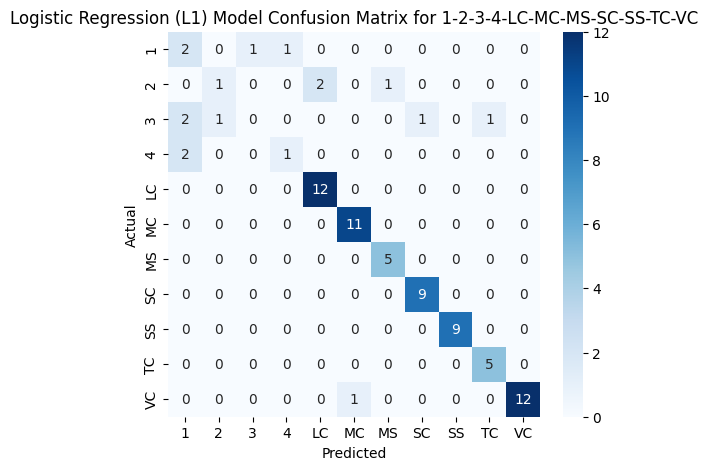

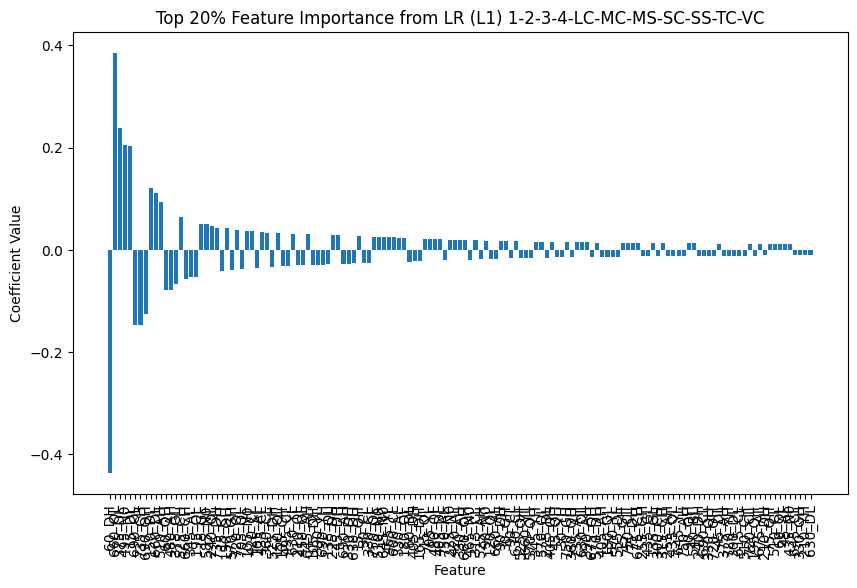

In [ ]:
############################### LR w/ L1 Regularization ###############################


group_name = 'Group_Full'

data = df_Full_Flat.dropna(subset=[group_name])
#data = data[~data['Plastic'].isin(['1', '2', '3', '4', 'MSH', 'MSM', 'MSL', 'SCH', 'SCM', 'SCL'])]

#print(df_Full_Flat.columns[2:-5])
X = data[df_Full_Flat.columns[2:-7]]
y = data[group_name]

print(f'Unique Plastics: {data["Plastic"].unique()}')

le = LabelEncoder()
y_orig = y
# Transform the target variable y (mapping the categories to 1 and 0)
y = le.fit_transform(y)

col_names = X.columns[:20]
print(col_names)
# Step 1: Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.4, random_state=42)

# Step 2: Standardize the data (Lasso benefits from standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)



# Step 1: Create a LogisticRegressionCV model with L1 penalty and 10-fold cross-validation
log_reg_cv = LogisticRegressionCV(cv=5, penalty='l1', solver='saga', max_iter=1000)  # 5-fold cross-validation

# Step 2: Fit the model
log_reg_cv.fit(X_val_scaled, y_val)

# Step 3: Best C (inverse of regularization strength) from cross-validation
print(f"Best C from cross-validation: {log_reg_cv.C_}")


##### LASSO w/ best alpha from CV #####
lasso_logistic_best_alpha = LogisticRegression(penalty='l1', solver='saga', C=log_reg_cv.C_[0], max_iter=1000)
lasso_logistic_best_alpha.fit(X_train_scaled, y_train)

y_pred = lasso_logistic_best_alpha.predict(X_test_scaled)

accuracy_cv = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy_cv:.4f}")

# Generate and plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Logistic Regression (L1) Model Confusion Matrix for {str("-".join(y_orig.unique()))}')
plt.show()

########## Logistic Regression (L1) Feature Importance ##########
coefficients = log_reg_cv.coef_[0]  # Get coefficients of the model

# Sort the coefficients by absolute value to rank features by importance
non_zero_idx = np.where(coefficients != 0)[0]
coefficients_non_zero = coefficients[non_zero_idx]
features_non_zero = X.columns[non_zero_idx]
sorted_idx = np.argsort(np.abs(coefficients_non_zero))[::-1]
top_idx = sorted_idx[:int(0.2 * len(sorted_idx))]

# Plot the feature importance
plt.figure(figsize=(10, 6))
plt.bar(range(len(top_idx)), coefficients_non_zero[top_idx], align='center')
plt.xticks(range(len(top_idx)), features_non_zero[top_idx], rotation=90)  # X.columns if X is a DataFrame
plt.xlabel('Feature')
plt.ylabel('Coefficient Value')
plt.title(f'Top 20% Feature Importance from LR (L1) {str("-".join(y_orig.unique()))}')
plt.show()


##Pairwise Plots

In [ ]:
###################### Pairwise Plots ######################
def pairplot_limited_columns(df, num_columns=18, hue=None):
    """
    Creates a Seaborn pairplot using a specified number of numerical columns.

    Parameters:
    - df (pd.DataFrame): The input DataFrame.
    - num_columns (int): Number of numerical columns to use for the plot.
    - hue (str, optional): Column name to use as the hue (color coding).
    """
    # Select only numeric columns
    numeric_df = df.select_dtypes(include='number')

    # Limit to the first `num_columns` numeric columns
    selected_cols = numeric_df.columns[:num_columns]

    # Create the pairplot
    sns.pairplot(df[selected_cols.tolist() + ([hue] if hue else [])], hue=hue)
    if hue:
        plt.legend(title=hue, bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()



FilePath = '/content/drive/MyDrive/Lexi/MNP/Round_2/KH_Data/20250807KH_combined.csv'
df = WrangleKData(FilePath, printFlag=False, kdiffFlag=False)
pairplot_limited_columns(df, hue='Group_Full')











#plt.show()
#pair_plot = sns.pairplot(df_Full_Flat.iloc[:, :20], hue='Plastic')

#cols_to_move = ['Group_MSLVN', 'Group_PN', 'Group_CS', 'Plastic']


# Reorder columns by placing '15_AH' first
#df_Full_Flat = df_Full_Flat[cols_to_move + [col for col in df_Full_Flat.columns if col not in cols_to_move]]

#filtered_columns = [col for col in df_Full_Flat.columns if '_' in col and col.split('_')[1][0] == "Y"]
#filtered_columns.extend(['Group_PN'])


# Create a new DataFrame with only the filtered columns
#filtered_df = df_Full_Flat[filtered_columns]
#filtered_df = df_Full_Flat[['Group_PN'] + [col for col in filtered_df.columns if col not in cols_to_move]]


# Save the plot as a PDF file
#pair_plot.savefig('/content/drive/MyDrive/Lexi/MNP/ML Analysis/pairplot20250306.png')
#pair_plot = sns.pairplot(filtered_df.iloc[:, :25], hue='Group_PN')
#pair_plot.savefig('/content/drive/MyDrive/Lexi/MNP/ML Analysis/pairplot20250306Y.png')


#pair_plot = sns.pairplot(df_Full_Flat.iloc[:, :25], hue='Group_CS')
#pair_plot.savefig('/content/drive/MyDrive/Lexi/MNP/ML Analysis/pairplot20250306CS.png')


#208 row = 16 channels / plastic and there are 13 plastics as of 2025-01-08 (check)

Output hidden; open in https://colab.research.google.com to view.

##LASSO

Unique Plastics: ['LCH' 'LCL' 'LCM' 'MCH' 'MCL' 'MCM' 'MSH' 'MSL' 'MSM' 'SCH' 'SCL' 'SCM'
 'SSH' 'SSL' 'SSM' 'TCH' 'TCL' 'TCM' 'VCH' 'VCL' 'VCM']
Index(['15_AH', '15_AL', '15_BH', '15_BL', '15_DH', '15_DL', '15_GH', '15_GL',
       '15_QH', '15_QL', '15_YH', '15_YL', '30_AH', '30_AL', '30_BH', '30_BL',
       '30_DH', '30_DL', '30_GH', '30_GL'],
      dtype='object')
Best alpha from Validation: 0.62479313020775
Mean Squared Error from Validation: 2.5354
R² Score from Validation: -0.0195
Mean Squared Error from Test: 2.5658
R² Score from Test: -0.0317


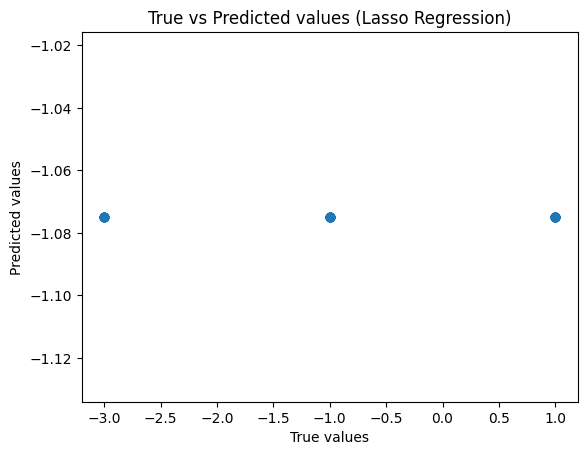

Model Coefficients: [ 0. -0.  0.  0. -0.  0.  0.  0. -0. -0. -0. -0.  0.  0.  0.  0. -0. -0.
  0. -0.  0.  0. -0.  0. -0. -0. -0. -0.  0. -0. -0. -0. -0. -0.  0. -0.
  0. -0.  0.  0.  0. -0. -0.  0. -0. -0.  0.  0.  0. -0. -0. -0. -0.  0.
  0.  0.  0. -0.  0. -0. -0. -0. -0.  0. -0. -0.  0.  0. -0. -0. -0. -0.
  0.  0.  0. -0.  0. -0.  0. -0.  0. -0.  0. -0. -0.  0. -0. -0. -0. -0.
  0. -0.  0. -0. -0. -0. -0. -0.  0. -0.  0.  0.  0.  0.  0. -0. -0.  0.
  0.  0.  0. -0. -0.  0.  0. -0. -0.  0. -0. -0. -0.  0.  0.  0.  0.  0.
  0.  0. -0. -0. -0.  0. -0.  0. -0. -0.  0.  0.  0. -0.  0. -0. -0. -0.
 -0. -0. -0.  0. -0.  0.  0. -0. -0. -0. -0. -0.  0.  0.  0.  0. -0.  0.
  0. -0. -0.  0.  0.  0. -0. -0. -0. -0.  0.  0.  0. -0. -0. -0. -0.  0.
 -0.  0.  0.  0. -0.  0.  0. -0.  0.  0.  0.  0.  0. -0.  0. -0. -0. -0.
 -0.  0.  0. -0.  0. -0.  0. -0.  0.  0. -0.  0.  0.  0. -0. -0. -0. -0.
 -0.  0. -0. -0.  0.  0. -0.  0.  0.  0.  0. -0. -0. -0.  0. -0.  0. -0.
 -0.  0. -0. -0. -0.  0. -0.  0

'\naccuracy = accuracy_score(y_test, y_pred_binary)\nprint(f"Accuracy: {accuracy:.4f}")\n# Gnerate and Plot the confusion matrix\ncm = confusion_matrix(y_test, y_pred_binary)\nplt.figure(figsize=(6, 5))\nsns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)\nplt.xlabel(\'Predicted\')\nplt.ylabel(\'Actual\')\nplt.title(f\'LASSO Model Confusion Matrix for {str("-".join(y_orig.unique()))}\')\nplt.show()\n\n########## LASSO Feature Importance ##########\ncoefficients = lasso.coef_\n\n# Sort the coefficients by absolute value to rank features by importance\nnon_zero_idx = np.where(coefficients != 0)[0]\ncoefficients_non_zero = coefficients[non_zero_idx]\nfeatures_non_zero = X.columns[non_zero_idx]\nsorted_idx = np.argsort(np.abs(coefficients_non_zero))[::-1]\ntop_idx = sorted_idx[:int(0.2 * len(sorted_idx))]\n\n\n# Plot the feature importance\nplt.figure(figsize=(10, 6))\nplt.bar(range(len(top_idx)), coefficients_non_zero[top_idx], align=\'cent

In [ ]:
############################### LASSO ###############################
##### woking on MHL grouping with numeric values #####

group_name = 'Group_MHL'

data = df_Full_Flat.dropna(subset=[group_name])
#data = data[~data['Plastic'].isin(['1', '2', '3', '4', 'MSH', 'MSM', 'MSL', 'SCH', 'SCM', 'SCL'])]
data.loc[:, 'Group_MHL'] = data['Group_MHL'].map({'High': np.log10(10.0), 'Medium': np.log10(0.1), 'Low': np.log10(0.001)})

X = data[df_Full_Flat.columns[2:-7]]
y = data[group_name]


print(f'Unique Plastics: {data["Plastic"].unique()}')


col_names = X.columns[:20]
print(col_names)
# Step 1: Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.3, random_state=42)

# Step 2: Standardize the data (Lasso benefits from standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Step 1: Create a LassoCV model (automatically tunes alpha via cross-validation)
lasso_cv = LassoCV(cv=10)  # 10-fold cross-validation

# Step 2: Fit the model
lasso_cv.fit(X_val_scaled, y_val)

# Step 3: Best alpha from cross-validation
print(f"Best alpha from Validation: {lasso_cv.alpha_}")

# Step 4: Evaluate the model with the best alpha
y_pred_cv = lasso_cv.predict(X_test_scaled)
mse_cv = mean_squared_error(y_test, y_pred_cv)
r2_cv = r2_score(y_test, y_pred_cv)

print(f"Mean Squared Error from Validation: {mse_cv:.4f}")
print(f"R² Score from Validation: {r2_cv:.4f}")


##### LASSO w/ best alpha from CV #####
lasso = Lasso(alpha=lasso_cv.alpha_)
lasso.fit(X_train_scaled, y_train)
y_pred = lasso.predict(X_test_scaled)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error from Test: {mse:.4f}")
print(f"R² Score from Test: {r2:.4f}")

# Plot the true vs predicted values
plt.scatter(y_test, y_pred)
plt.xlabel('True values')
plt.ylabel('Predicted values')
plt.title('True vs Predicted values (Lasso Regression)')
plt.show()

# Coefficients of the Lasso regression model
print(f"Model Coefficients: {lasso.coef_}")

"""
accuracy = accuracy_score(y_test, y_pred_binary)
print(f"Accuracy: {accuracy:.4f}")
# Gnerate and Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred_binary)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'LASSO Model Confusion Matrix for {str("-".join(y_orig.unique()))}')
plt.show()

########## LASSO Feature Importance ##########
coefficients = lasso.coef_

# Sort the coefficients by absolute value to rank features by importance
non_zero_idx = np.where(coefficients != 0)[0]
coefficients_non_zero = coefficients[non_zero_idx]
features_non_zero = X.columns[non_zero_idx]
sorted_idx = np.argsort(np.abs(coefficients_non_zero))[::-1]
top_idx = sorted_idx[:int(0.2 * len(sorted_idx))]


# Plot the feature importance
plt.figure(figsize=(10, 6))
plt.bar(range(len(top_idx)), coefficients_non_zero[top_idx], align='center')
plt.xticks(range(len(top_idx)), features_non_zero[top_idx], rotation=90)  # X.columns if X is a DataFrame
plt.xlabel('Feature')
plt.ylabel('Coefficient Value')
plt.title(f'Top 20% Feature Importance from Lasso Regression {str("-".join(y_orig.unique()))}')
plt.show()
"""


##Ordinal Logistic Regression

In [ ]:
###################### Ordinal Logistic Regression ######################
#still under development; depricated 20250310

from statsmodels.miscmodels.ordinal_model import OrderedModel

group_name = 'Group_MHL'

data = df_Full_Flat.dropna(subset=[group_name]).copy()  # Use .copy() to explicitly create a copy
display(data)
# Map the 'L', 'M', 'H' values to 'low', 'medium', 'high'
data.loc[:, 'Group_MHL'] = data['Group_MHL'].map({'Low': 10.0, 'Medium': 0.1, 'High': 0.001})
display(data)

# Convert the 'Group_MHL' column to an ordinal categorical type with proper ordering
data.loc[:, 'Group_MHL'] = pd.Categorical(data['Group_MHL'], categories=['low', 'medium', 'high'], ordered=True)

display(data)

#print(df_Full_Flat.columns[2:-5])
X = data[df_Full_Flat.columns[2:-7]]
y = data[group_name]

le = LabelEncoder()
y_orig = y
# Transform the target variable y (mapping the categories to 1 and 0)
y = le.fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Standardize the data (Lasso benefits from standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 1: Fit the Ordered Logit (Ordinal Logistic Regression) model
model = OrderedModel(y_train, X_train_scaled, distr='logit')

print(model)

result = model.fit()

# Print the model summary
print(result.summary())

# Step 2: Predict on the test set
y_pred = result.predict(X_test_scaled)

# Convert the predicted probabilities to the most likely category
y_pred_class = le.inverse_transform(y_pred.argmax(axis=1))

# Accuracy on test data
accuracy = accuracy_score(y_test, y_pred_class)
print(f"Accuracy: {accuracy:.4f}")

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_class))

,Channel,Plastic,15_AH,15_AL,15_BH,15_BL,15_CH,15_CL,15_DH,15_DL,...,750_GL,750_N0,750_QH,750_QL,750_YH,750_YL,Group_PN,Group_MSLVTN,Group_MHL,Group_CS
64,0,LCH,7.600234,0.327044,0.528686,1.128161,-0.781396,-0.610470,0.559557,-1.135470,...,-7.098675,-3.066313,0.045074,-10.653925,-1.260383,5.361467,Plastic,LDPE,High,Cryo
65,1,LCH,6.167457,1.383010,2.040890,-1.124876,-1.513067,-1.531694,0.063049,-0.195185,...,-5.739765,-5.790842,-15.527649,-6.376706,-6.130570,-10.223347,Plastic,LDPE,High,Cryo
66,2,LCH,4.952346,0.431354,0.023256,-0.245767,-1.937340,-2.347287,-0.882406,-2.067417,...,5.550638,-5.591519,-12.798214,-14.551483,-1.457866,-2.834962,Plastic,LDPE,High,Cryo
67,3,LCH,3.497101,-0.785538,-1.771047,-2.492396,-0.104983,-2.412481,-0.954093,-0.047772,...,-3.408880,-1.513632,6.652901,4.332243,-8.475602,-9.440211,Plastic,LDPE,High,Cryo
68,4,LCH,-2.428986,-6.012561,-5.546516,-3.164814,-1.260744,1.845643,0.241668,-1.358239,...,-12.703144,6.036703,-12.607747,9.781593,-1.549936,6.228402,Plastic,LDPE,High,Cryo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,11,VCM,-0.051827,-0.595138,-1.813581,-0.176293,-0.996893,0.896522,0.536562,0.020544,...,1.113846,-16.061040,-0.053105,-1.026909,0.679824,-2.433867,Plastic,PVC,Medium,Cryo
396,12,VCM,-0.406808,0.344037,0.069471,0.801477,1.706774,2.568318,1.025058,-0.522469,...,1.522504,-0.153693,3.752404,1.210439,-3.550008,13.958282,Plastic,PVC,Medium,Cryo
397,13,VCM,0.107072,0.570563,-1.795610,1.607107,1.149229,0.971573,2.238530,-0.788658,...,7.540622,1.013970,2.383740,-1.896262,0.335513,-3.735756,Plastic,PVC,Medium,Cryo
398,14,VCM,-0.629243,0.612342,1.702528,4.247635,-0.196621,3.543248,0.847214,-0.544930,...,-0.244263,-10.657846,-9.301442,-2.871963,0.138787,6.177236,Plastic,PVC,Medium,Cryo


,Channel,Plastic,15_AH,15_AL,15_BH,15_BL,15_CH,15_CL,15_DH,15_DL,...,750_GL,750_N0,750_QH,750_QL,750_YH,750_YL,Group_PN,Group_MSLVTN,Group_MHL,Group_CS
64,0,LCH,7.600234,0.327044,0.528686,1.128161,-0.781396,-0.610470,0.559557,-1.135470,...,-7.098675,-3.066313,0.045074,-10.653925,-1.260383,5.361467,Plastic,LDPE,0.001,Cryo
65,1,LCH,6.167457,1.383010,2.040890,-1.124876,-1.513067,-1.531694,0.063049,-0.195185,...,-5.739765,-5.790842,-15.527649,-6.376706,-6.130570,-10.223347,Plastic,LDPE,0.001,Cryo
66,2,LCH,4.952346,0.431354,0.023256,-0.245767,-1.937340,-2.347287,-0.882406,-2.067417,...,5.550638,-5.591519,-12.798214,-14.551483,-1.457866,-2.834962,Plastic,LDPE,0.001,Cryo
67,3,LCH,3.497101,-0.785538,-1.771047,-2.492396,-0.104983,-2.412481,-0.954093,-0.047772,...,-3.408880,-1.513632,6.652901,4.332243,-8.475602,-9.440211,Plastic,LDPE,0.001,Cryo
68,4,LCH,-2.428986,-6.012561,-5.546516,-3.164814,-1.260744,1.845643,0.241668,-1.358239,...,-12.703144,6.036703,-12.607747,9.781593,-1.549936,6.228402,Plastic,LDPE,0.001,Cryo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,11,VCM,-0.051827,-0.595138,-1.813581,-0.176293,-0.996893,0.896522,0.536562,0.020544,...,1.113846,-16.061040,-0.053105,-1.026909,0.679824,-2.433867,Plastic,PVC,0.1,Cryo
396,12,VCM,-0.406808,0.344037,0.069471,0.801477,1.706774,2.568318,1.025058,-0.522469,...,1.522504,-0.153693,3.752404,1.210439,-3.550008,13.958282,Plastic,PVC,0.1,Cryo
397,13,VCM,0.107072,0.570563,-1.795610,1.607107,1.149229,0.971573,2.238530,-0.788658,...,7.540622,1.013970,2.383740,-1.896262,0.335513,-3.735756,Plastic,PVC,0.1,Cryo
398,14,VCM,-0.629243,0.612342,1.702528,4.247635,-0.196621,3.543248,0.847214,-0.544930,...,-0.244263,-10.657846,-9.301442,-2.871963,0.138787,6.177236,Plastic,PVC,0.1,Cryo


,Channel,Plastic,15_AH,15_AL,15_BH,15_BL,15_CH,15_CL,15_DH,15_DL,...,750_GL,750_N0,750_QH,750_QL,750_YH,750_YL,Group_PN,Group_MSLVTN,Group_MHL,Group_CS
64,0,LCH,7.600234,0.327044,0.528686,1.128161,-0.781396,-0.610470,0.559557,-1.135470,...,-7.098675,-3.066313,0.045074,-10.653925,-1.260383,5.361467,Plastic,LDPE,0.001,Cryo
65,1,LCH,6.167457,1.383010,2.040890,-1.124876,-1.513067,-1.531694,0.063049,-0.195185,...,-5.739765,-5.790842,-15.527649,-6.376706,-6.130570,-10.223347,Plastic,LDPE,0.001,Cryo
66,2,LCH,4.952346,0.431354,0.023256,-0.245767,-1.937340,-2.347287,-0.882406,-2.067417,...,5.550638,-5.591519,-12.798214,-14.551483,-1.457866,-2.834962,Plastic,LDPE,0.001,Cryo
67,3,LCH,3.497101,-0.785538,-1.771047,-2.492396,-0.104983,-2.412481,-0.954093,-0.047772,...,-3.408880,-1.513632,6.652901,4.332243,-8.475602,-9.440211,Plastic,LDPE,0.001,Cryo
68,4,LCH,-2.428986,-6.012561,-5.546516,-3.164814,-1.260744,1.845643,0.241668,-1.358239,...,-12.703144,6.036703,-12.607747,9.781593,-1.549936,6.228402,Plastic,LDPE,0.001,Cryo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,11,VCM,-0.051827,-0.595138,-1.813581,-0.176293,-0.996893,0.896522,0.536562,0.020544,...,1.113846,-16.061040,-0.053105,-1.026909,0.679824,-2.433867,Plastic,PVC,0.1,Cryo
396,12,VCM,-0.406808,0.344037,0.069471,0.801477,1.706774,2.568318,1.025058,-0.522469,...,1.522504,-0.153693,3.752404,1.210439,-3.550008,13.958282,Plastic,PVC,0.1,Cryo
397,13,VCM,0.107072,0.570563,-1.795610,1.607107,1.149229,0.971573,2.238530,-0.788658,...,7.540622,1.013970,2.383740,-1.896262,0.335513,-3.735756,Plastic,PVC,0.1,Cryo
398,14,VCM,-0.629243,0.612342,1.702528,4.247635,-0.196621,3.543248,0.847214,-0.544930,...,-0.244263,-10.657846,-9.301442,-2.871963,0.138787,6.177236,Plastic,PVC,0.1,Cryo


/usr/local/lib/python3.11/dist-packages/statsmodels/base/optimizer.py:737: RuntimeWarning: Maximum number of iterations has been exceeded.
  retvals = optimize.fmin(f, start_params, args=fargs, xtol=xtol,


KeyboardInterrupt: 